# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Игнатенко Анастасия Ивановна

**Файлы данных:** S12

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файл `clients.csv`: кодировка UTF-8, разделитель столбцов - запятая, дробная часть отделяется точкой.

In [2]:
raw_clients = pd.read_csv(RAW_CLIENTS, encoding='utf-8',
                      dtype={'branch_code': str})

clients = raw_clients.copy()
raw_clients.head()

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C002706,1985-03-29,М,Казань,Премиальный,Платина,Премиальная,02.02.2013,19.09.2018,Зарплата в нашем банке,154700.0,Да,2025-02,2.0,00505,Да
1,C000343,1966-11-23,Ж,Санкт-Петербург,Массовый,Базовый,Дебетовая,08.01.2012,20.01.2016,Зарплата в нашем банке,52600.0,Нет,NaN,NaN,00232,Да
2,C001703,1969-06-14,М,г. Санкт-Петербург,Зарплатный,Серебро,Дебетовая,01.06.2017,05.04.2019,Зарплата в другом банке,57900.0,Нет,NaN,5.0,00247,Да
3,C003745,1988-12-20,Ж,Москва,Зарплатный,Серебро,Дебетовая,14.12.2020,12.10.2021,Зарплата в нашем банке,82900.0,Да,2024-03,3.0,00389,Да
4,C002353,1946-03-21,М,Екатеринбург,Массовый,Золото,Дебетовая,25.06.2018,21.10.2020,Зарплата в другом банке,82400.0,Нет,NaN,NaN,00377,Да


Файл `transactions.csv`: кодировка cp1251, разделитель столбцов - точка с запятой, дробная часть отделяется запятой.

In [3]:
raw_transactions = pd.read_csv(RAW_TXN, sep=';', encoding='cp1251', decimal=',',
                           dtype={'txn_id': str,
                                  'mcc_code': str})
transactions = raw_transactions.copy()
raw_transactions.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990207,C002826,2023-11-23 11:22:20,1536.51,RUB,Продукты,5411,Карта,успешно
1,990001,C004036,2023-11-27 16:46:00,1706.40,RUB,Продукты,5411,Токен,успешно
2,990173,C004983,2023-12-04 13:37:27,784.53,RUB,Продукты,5411,Карта,успешно
3,990114,C000812,2023-12-11 20:55:36,931.61,RUB,АЗС,5541,Онлайн-банк,успешно
4,990009,C002145,2023-12-12 11:13:15,1942.17,RUB,кафе и рестораны,5812,Карта,успешно


## 2. Аудит качества

### 2.1. Объём, типы, ключи, единица наблюдения

In [4]:
print('Clients, строк и столбцов:', clients.shape)
print('Transactions, строк и столбцов:', transactions.shape)

Clients, строк и столбцов: (5680, 16)
Transactions, строк и столбцов: (619007, 9)


In [5]:
print('Типы clients:')
print(clients.dtypes)

Типы clients:
client_id                 str
birth_date                str
gender                    str
city                      str
segment                   str
loyalty_tier              str
card_type                 str
registration_date         str
card_open_date            str
income_source             str
monthly_income        float64
has_mobile_app            str
app_last_login            str
satisfaction_score    float64
branch_code               str
marketing_opt_in          str
dtype: object


In [6]:
print('Типы transactions:')
print(transactions.dtypes)

Типы transactions:
txn_id              str
client_id           str
txn_datetime        str
amount          float64
currency            str
category            str
mcc_code            str
channel             str
status              str
dtype: object


In [7]:
print('Clients, строк:', len(clients))
print('Clients, уникальных client_id:', clients['client_id'].nunique())
print()
print('Transactions, строк:', len(transactions))
print('Transactions, уникальных txn_id:', transactions['txn_id'].nunique())

Clients, строк: 5680
Clients, уникальных client_id: 5625

Transactions, строк: 619007
Transactions, уникальных txn_id: 617507


**Типы.** Все даты (`birth_date`, `registration_date`, `card_open_date`, `app_last_login`, `txn_datetime`), категориальные поля и «Да/Нет» прочитаны как строки. `satisfaction_score` прочитан как `float64` из-за пропусков, хотя это целая оценка от 1 до 5. Коды (`client_id`, `branch_code`, `txn_id`, `mcc_code`) специально прочитаны как строки, чтобы не потерять ведущие нули.

**Единица наблюдения.** В `clients` одна строка — один клиент, ключ `client_id`. В `transactions` одна строка — одна операция, ключ `txn_id`; клиент операции определяется по `client_id`.

**Ключи.** Оба ключа не уникальны: в `clients` 5680 строк и 5625 уникальных `client_id`, в `transactions` 619 007 строк и 617 507 уникальных `txn_id`.

### 2.2. Дубли

In [8]:
n_cl, n_tr = len(clients), len(transactions)
full_cl = clients.duplicated().sum()
full_tr = transactions.duplicated().sum()
print(f'Полных дублей в clients: {full_cl} из {n_cl} ({full_cl / n_cl:.2%})')
print(f'Полных дублей в transactions: {full_tr} из {n_tr} ({full_tr / n_tr:.2%})')

Полных дублей в clients: 41 из 5680 (0.72%)
Полных дублей в transactions: 1272 из 619007 (0.21%)


In [9]:
rep_cl = clients[clients.duplicated('client_id', keep=False)]
n_values = rep_cl.groupby('client_id').nunique(dropna=False)
conflict = n_values[(n_values > 1).any(axis=1)]

n_rep = rep_cl['client_id'].nunique()
print(f'Количество client_id, у которых есть повторы: {n_rep} из {clients["client_id"].nunique()}')
print(f'Из них с расхождениями в данных: {len(conflict)} из {n_rep}')
print()

diff = (conflict > 1).sum()
print('Количество client_id с расхождением по полю:')
print(diff[diff > 0].to_string())

Количество client_id, у которых есть повторы: 55 из 5625
Из них с расхождениями в данных: 14 из 55

Количество client_id с расхождением по полю:
city       14
segment    11


In [10]:
rep_tr = transactions[transactions.duplicated('txn_id', keep=False)]
n_values_tr = rep_tr.groupby('txn_id').nunique(dropna=False)
conflict_tr = n_values_tr[(n_values_tr > 1).any(axis=1)]

n_rep_tr = rep_tr['txn_id'].nunique()
print(f'Количество txn_id, у которых есть повторы: {n_rep_tr} из {transactions["txn_id"].nunique()}')
print(f'Из них с расхождениями в данных: {len(conflict_tr)} из {n_rep_tr}')
print()

diff_tr = (conflict_tr > 1).sum()
print('Количество txn_id с расхождением по полю:')
print(diff_tr[diff_tr > 0].to_string())

Количество txn_id, у которых есть повторы: 1500 из 617507
Из них с расхождениями в данных: 228 из 1500

Количество txn_id с расхождением по полю:
txn_datetime    228


В `clients` 41 полный дубль (0.72% строк). Ещё у 14 повторяющихся `client_id` строки расходятся в `city` (14) и `segment` (11), поэтому неясно, какая версия верная. В `transactions` 1272 полных дубля (0.21% строк) и 228 `txn_id`, у которых строки отличаются только `txn_datetime`.

### 2.3. Соответствие данных описанию полей из задания

In [11]:
for name, df in [('clients', clients), ('transactions', transactions)]:
    na = df.isna().sum()
    na = na[na > 0].sort_values(ascending=False)
    print(f'Пропуски в {name}:')
    if na.empty:
        print('отсутствуют')
    for col, k in na.items():
        print(f'{col}: {k} из {len(df)} ({k / len(df):.2%})')
    print()

Пропуски в clients:
satisfaction_score: 3397 из 5680 (59.81%)
app_last_login: 2117 из 5680 (37.27%)
monthly_income: 510 из 5680 (8.98%)

Пропуски в transactions:
отсутствуют



In [12]:
cat_cols = {
    'clients': ['gender', 'segment', 'loyalty_tier', 'card_type', 'income_source',
                'has_mobile_app', 'marketing_opt_in', 'city', 'satisfaction_score'],
    'transactions': ['currency', 'category', 'channel', 'status', 'mcc_code'],
}
tables = {'clients': clients, 'transactions': transactions}

print('Значения категориальных полей и число строк с каждым значением')
for name, cols in cat_cols.items():
    for col in cols:
        print(f'{name}.{col}:')
        print(tables[name][col].value_counts(dropna=False).to_string())
        print()

Значения категориальных полей и число строк с каждым значением
clients.gender:
gender
Ж    2864
М    2816

clients.segment:
segment
Массовый       2941
Зарплатный     1618
Премиальный     900
Private         221

clients.loyalty_tier:
loyalty_tier
Базовый    2930
Серебро    1542
Золото      921
Платина     287

clients.card_type:
card_type
Дебетовая      3982
Кредитная      1224
Премиальная     474

clients.income_source:
income_source
Зарплата в нашем банке     2515
Зарплата в другом банке    1602
Не указан                  1563

clients.has_mobile_app:
has_mobile_app
Да     3563
Нет    2117

clients.marketing_opt_in:
marketing_opt_in
Да     4972
Нет     708

clients.city:
city
Москва                1064
Екатеринбург           703
Санкт-Петербург        634
Казань                 567
Новосибирск            553
Нижний Новгород        546
 москва                193
МОСКВА                 182
Н. Новгород            174
г. Новосибирск         156
ЕКАТЕРИНБУРГ           155
г. Москва      

In [13]:
date_cols = {
    'clients': ['birth_date', 'registration_date', 'card_open_date', 'app_last_login'],
    'transactions': ['txn_datetime'],
}

print('Форматы дат (0 - любая цифра) и число строк с каждым форматом')
for name, cols in date_cols.items():
    for col in cols:
        pattern = tables[name][col].str.replace(r'\d', '0', regex=True)
        print(f'{name}.{col}:')
        print(pattern.value_counts(dropna=False).to_string())
        print()

Форматы дат (0 - любая цифра) и число строк с каждым форматом
clients.birth_date:
birth_date
0000-00-00    5680

clients.registration_date:
registration_date
00.00.0000    5680

clients.card_open_date:
card_open_date
00.00.0000    5680

clients.app_last_login:
app_last_login
0000-00    3563
NaN        2117

transactions.txn_datetime:
txn_datetime
0000-00-00 00:00:00    569114
0000-00-00              49893



In [14]:
clients['monthly_income'].describe().round(1)

count      5170.0
mean      93777.3
std       81663.9
min        -999.0
25%       52100.0
50%       73500.0
75%      108475.0
max      882300.0
Name: monthly_income, dtype: float64

In [15]:
n_999 = (clients['monthly_income'] == -999).sum()
print(f'Метка -999 в monthly_income: {n_999} из {len(clients)} ({n_999 / len(clients):.2%})')

Метка -999 в monthly_income: 55 из 5680 (0.97%)


In [16]:
print('Описательные статистики monthly_income без -999:')
clients.loc[clients['monthly_income'] != -999, 'monthly_income'].describe().round(1)

Описательные статистики monthly_income без -999:


count      5115.0
mean      94796.4
std       81505.1
min          23.6
25%       52600.0
50%       74100.0
75%      108950.0
max      882300.0
Name: monthly_income, dtype: float64

In [17]:
transactions['amount'].describe().round(1)

count    619007.0
mean       1853.1
std        2649.7
min      -69253.8
25%         468.6
50%        1066.5
75%        2251.7
max      108042.2
Name: amount, dtype: float64

In [18]:
print('Описательные статистики amount по валютам:')
transactions.groupby('currency')['amount'].describe().round(2)

Описательные статистики amount по валютам:


,count,mean,std,min,25%,50%,75%,max
currency,,,,,,,,
EUR,1305.0,19.05,25.52,-47.56,4.85,11.74,23.60,282.23
RUB,616476.0,1860.65,2652.53,-69253.81,474.80,1072.74,2259.77,108042.22
USD,1226.0,20.05,28.95,-74.74,5.00,11.54,23.78,319.93


In [19]:
sign = np.where(transactions['amount'] < 0, 'отрицательная', 'положительная')
print('Число операций по статусу и знаку суммы:')
print(pd.crosstab(transactions['status'], sign))

Число операций по статусу и знаку суммы:
col_0      отрицательная  положительная
status                                 
возврат             7523              0
отклонено              0          12015
успешно                0         599469


In [20]:
print('Разных branch_code:', clients['branch_code'].nunique())
print('Клиентов на одно отделение:')
print(clients['branch_code'].value_counts().describe().round(1).to_string())

Разных branch_code: 839
Клиентов на одно отделение:
count    839.0
mean       6.8
std        2.6
min        1.0
25%        5.0
50%        7.0
75%        8.0
max       17.0


In [21]:
city_tmp = clients['city'].str.strip().str.lower().str.replace(r'^г\.\s*', '', regex=True)
cities_per_branch = city_tmp.groupby(clients['branch_code']).nunique()

print('Число разных городов у клиентов одного отделения:')
print(cities_per_branch.value_counts().sort_index().to_string())
print()
print(f'Отделений, где все клиенты из одного города: {(cities_per_branch == 1).sum()} из {len(cities_per_branch)}')

Число разных городов у клиентов одного отделения:
city
1      9
2     73
3    155
4    266
5    217
6     92
7     25
8      2

Отделений, где все клиенты из одного города: 9 из 839


In [22]:
print('Форматы client_id в clients:', clients['client_id'].str.replace(r'\d', '0', regex=True).unique())
print('Форматы client_id в transactions:', transactions['client_id'].str.replace(r'\d', '0', regex=True).unique())
print('Форматы txn_id:', transactions['txn_id'].str.replace(r'\d', '0', regex=True).unique())

Форматы client_id в clients: <ArrowStringArray>
['C000000']
Length: 1, dtype: str
Форматы client_id в transactions: <ArrowStringArray>
['C000000']
Length: 1, dtype: str
Форматы txn_id: <ArrowStringArray>
['000000']
Length: 1, dtype: str


In [23]:
dt_tmp = pd.to_datetime(transactions['txn_datetime'], format='mixed')
n_tr = len(transactions)
before = (dt_tmp < '2024-01-01').sum()
after = (dt_tmp > '2025-06-30 23:59:59').sum()

print('Даты операций: от', dt_tmp.min(), 'до', dt_tmp.max())
print(f'Операций до 01.01.2024: {before} из {n_tr} ({before / n_tr:.2%})')
print(f'Операций после 30.06.2025: {after} из {n_tr} ({after / n_tr:.2%})')

Даты операций: от 2023-11-23 11:22:20 до 2026-08-04 09:53:15
Операций до 01.01.2024: 9 из 619007 (0.00%)
Операций после 30.06.2025: 79 из 619007 (0.01%)


Пропуски есть только в `clients`: `satisfaction_score` 3397 из 5680 (59.81%), `app_last_login` 2117 (37.27%), `monthly_income` 510 (8.98%). Число пропусков в `app_last_login` совпадает с числом клиентов без приложения (`has_mobile_app = Нет`, 2117). Кроме того, в `income_source` встречается значение «Не указан» (1563 строки).

В `monthly_income` встречается значение −999 (55 строк, 0.97%)

`segment`, `loyalty_tier`, `card_type`, `channel`, `status` совпадают со списками из описания. `satisfaction_score` принимает целые значения от 1 до 5, как и заявлено.

`city`: 6 городов записаны 17 разными способами (регистр, пробелы, «г.», сокращения «СПб», «Н. Новгород»).

`category`: по описанию категорий девять, в данных 12 значений, потому что «Связь и интернет» и «Кафе и рестораны» встречаются в нескольких написаниях. Кодов `mcc_code` девять, как и указано в описании данных.

Даты внутри полей записаны в одном формате, но форматы отличаются: `birth_date` в виде ГГГГ-ММ-ДД, `registration_date` и `card_open_date` в виде ДД.ММ.ГГГГ, `app_last_login` только год и месяц. В `txn_datetime` два формата: с временем и без (49 893 строки без времени).

`monthly_income` по описанию в рублях, но при медиане 74 100 минимум 23.6, то есть часть доходов, похоже, записана в тысячах, либо это выброс.

`amount`: помимо RUB есть EUR (1305) и USD (1226). Их суммы на два порядка меньше рублёвых, значит, записаны в валюте операции. Все возвраты, и только они, с отрицательной суммой.


`branch_code`: 839 отделений, в среднем около 7 клиентов на отделение. Только у 9 из 839 все клиенты из одного города, поэтому код отделения к городу не привязан.

Формат идентификаторов единый: `client_id` это «C» и 6 цифр, `txn_id` это 6 цифр.

Операции выходят за период 01.01.2024–30.06.2025: 9 до начала и 79 после конца.

### 2.4. Связь между таблицами

In [24]:
not_in_cl = ~transactions['client_id'].isin(clients['client_id'])
n_tr_clients = transactions['client_id'].nunique()
k_cl = transactions.loc[not_in_cl, 'client_id'].nunique()

print(f'client_id из transactions, которых нет в clients: {k_cl} из {n_tr_clients}')
print(f'Их операций: {not_in_cl.sum()} из {len(transactions)} ({not_in_cl.mean():.2%})')

client_id из transactions, которых нет в clients: 375 из 5994
Их операций: 31348 из 619007 (5.06%)


In [25]:
no_ops = ~clients['client_id'].isin(transactions['client_id'])
print(f'client_id из clients без операций: {clients.loc[no_ops, "client_id"].nunique()} из {clients["client_id"].nunique()}')

client_id из clients без операций: 6 из 5625


В `transactions` есть 375 из 5994 `client_id`, которых нет в справочнике `clients`. На них приходится 31 348 из 619 007 операций (5.06%). Справочник составлен из действующих клиентов на 30.06.2025, поэтому, возможно, это клиенты, которые ушли из банка до этой даты. В обратную сторону у 6 из 5625 клиентов справочника нет ни одной операции.

**Выводы по аудиту.**

1. В `clients` 41 полный дубль (0.72% строк). Из-за них часть клиентов посчитается дважды.
2. У 14 из 5625 `client_id` строки расходятся в `city` и `segment`, неясно, какая версия верная.
3. В `transactions` 1272 полных дубля (0.21% строк). Они завышают число операций клиента, а по операциям мы будем оценивать активность.
4. 228 `txn_id` повторяются с датой в разных форматах. Это одна операция, записанная дважды, мешает так же, как дубли.
5. Пропуски `satisfaction_score` у 3397 из 5680 клиентов (59.81%), по этому признаку можно описать только меньшую часть клиентов.
6. Пропуски `app_last_login` у 2117 из 5680 (37.27%) совпадают с клиентами без приложения.
7. В `monthly_income` 510 пропусков и 55 значений −999 из 5680, а часть доходов меньше тысячи. Без исправления разрезы по доходу будут неверными.
8. В `income_source` 1563 из 5680 значений «Не указан», это ограничивает разрезы по источнику зарплаты.
9. 6 городов записаны 17 способами. Пока написание не приведено к одному виду, разрезы по городу неверны.
10. В `category` 12 значений вместо 9, траты одной категории записаны по-разному. Пока написание не приведено к одному виду, разрезы по категории неверны.
11. Форматы дат в разных полях отличаются, а в `txn_datetime` 49 893 из 619 007 операций записаны без времени. Каждое поле надо читать своим форматом.
12. 2531 из 619 007 операций (0.41%) в EUR и USD, суммы записаны в валюте операции. Складывать их с рублёвыми без пересчёта нельзя.
13. `branch_code` не связан с городом (только у 9 из 839 отделений все клиенты из одного города), поэтому использовать его как географию нельзя.
14. 88 из 619 007 операций (0.01%) вне периода 01.01.2024–30.06.2025 (9 до и 79 после). Периоды для сравнения активности лежат внутри этого интервала, так что эти операции туда попасть не должны.
15. 375 клиентов из `transactions` нет в справочнике, у них 31 348 из 619 007 операций (5.06%). Признаков и согласия на коммуникацию у них нет.
16. У 6 из 5625 клиентов справочника нет ни одной операции, оценить их активность нельзя.

## 3. Препроцессинг

In [26]:
# Журнал изменений: записи добавляем в разделе 3, таблицу собираем в разделе 4
log_rows = []

def add_log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    log_rows.append({'field': field, 'issue': issue, 'scope': scope, 'n_rows': n_rows,
                     'value_before': value_before, 'action': action,
                     'value_after': value_after, 'rationale': rationale})

### 3.1. Типы, даты, числа

Сначала удаляем дубли, чтобы дальнейшие подсчёты шли по реальным строкам.

- **Полные дубли** (41 в `clients`, 1272 в `transactions`). Строки совпадают целиком, это одна запись, выгруженная дважды. Удаляем копии, оставляем одну строку. Какую из одинаковых оставить, неважно.
- **14 `client_id` с расхождениями в `city` и `segment`.** Клиент в справочнике должен быть одной строкой. Какая версия верная, по данным определить нельзя: дат изменения записи нет. Оставляем последнюю строку в файле, предполагая, что выгрузка дописывает более свежие записи в конец. Это допущение, но клиентов всего 14, и на выводы оно почти не влияет.
- **228 `txn_id`, у которых строки отличаются в `txn_datetime`.** Как именно отличаются даты, проверяем ниже, после перевода `txn_datetime` в datetime, и там же решаем, какую строку оставить.

In [27]:
# Полные дубли: оставляем одну строку из одинаковых
n_before = len(clients)
clients = clients.drop_duplicates()
add_log('все поля', 'полные дубли строк', 'clients, строки, совпадающие целиком',
        n_before - len(clients), 'две одинаковые строки', 'удалено', 'одна строка',
        'повтор выгрузки, новой информации не несёт')

n_before = len(transactions)
transactions = transactions.drop_duplicates()
add_log('все поля', 'полные дубли строк', 'transactions, строки, совпадающие целиком',
        n_before - len(transactions), 'две одинаковые строки', 'удалено', 'одна строка',
        'повтор выгрузки, иначе одна операция посчитается дважды')

print('Строк в clients:', len(clients))
print('Строк в transactions:', len(transactions))

Строк в clients: 5639
Строк в transactions: 617735


In [28]:
# client_id с разными city и segment: оставляем последнюю строку в файле
n_before = len(clients)
clients = clients.drop_duplicates(subset='client_id', keep='last')
add_log('все поля', 'у одного client_id несколько строк с разными значениями полей',
        'clients, строки с одинаковым client_id, но разными city и segment', n_before - len(clients),
        'две версии строки клиента', 'удалено', 'последняя строка по client_id',
        'верную версию по данным не определить, носудя по совпадению остальных полей, это тот же клиент; оставляем последнюю строку как, вероятно, более свежую')

print('Строк в clients:', len(clients))
print('Уникальных client_id:', clients['client_id'].nunique())

Строк в clients: 5625
Уникальных client_id: 5625


In [29]:
# Даты clients: у каждого поля свой формат
clients['birth_date'] = pd.to_datetime(clients['birth_date'], format='%Y-%m-%d')
clients['registration_date'] = pd.to_datetime(clients['registration_date'], format='%d.%m.%Y')
clients['card_open_date'] = pd.to_datetime(clients['card_open_date'], format='%d.%m.%Y')
clients['app_last_login'] = pd.to_datetime(clients['app_last_login'], format='%Y-%m').dt.to_period('M')

add_log('birth_date, registration_date, card_open_date, app_last_login', 'даты записаны строками',
        'clients, все строки с заполненной датой', len(clients),
        'строки ГГГГ-ММ-ДД, ДД.ММ.ГГГГ, ГГГГ-ММ', 'исправлено', 'datetime, app_last_login как месяц',
        'значение не меняется, меняется только тип, чтобы с датами можно было работать удобно')

print('Типы дат в clients:')
print(clients[['birth_date', 'registration_date', 'card_open_date', 'app_last_login']].dtypes.to_string())

Типы дат в clients:
birth_date           datetime64[us]
registration_date    datetime64[us]
card_open_date       datetime64[us]
app_last_login            period[M]


In [30]:
# Дата и время операции: два формата, оба начинаются с года
transactions['txn_datetime'] = pd.to_datetime(transactions['txn_datetime'], format='mixed')
add_log('txn_datetime', 'дата записана строкой, часть без времени', 'transactions, все строки',
        len(transactions), 'строки ГГГГ-ММ-ДД ЧЧ:ММ:СС и ГГГГ-ММ-ДД', 'исправлено',
        'datetime, у строк без времени 00:00:00',
        'меняем тип, чтобы с датами можно было работать удобно')

print('Тип txn_datetime:', transactions['txn_datetime'].dtype)

Тип txn_datetime: datetime64[us]


In [31]:
# Чем отличаются даты у повторяющихся txn_id
rep = transactions[transactions.duplicated('txn_id', keep=False)].sort_values('txn_id')
print(rep[['txn_id', 'txn_datetime']].head(6).to_string())
print()

# Совпадает ли день у обеих строк пары
same_day = rep.groupby('txn_id')['txn_datetime'].agg(lambda s: s.dt.normalize().nunique() == 1)
print(f'Пар, у которых совпадает день: {same_day.sum()} из {len(same_day)}')

# Сколько строк пары записаны без времени (время ровно 00:00:00)
no_time = (rep['txn_datetime'] == rep['txn_datetime'].dt.normalize()).groupby(rep['txn_id']).sum()
print(f'Пар, где одна строка без времени (время ровно 00:00:00): {(no_time == 1).sum()} из {len(no_time)}')

       txn_id        txn_datetime
1735   101720 2024-01-03 13:29:31
1736   101720 2024-01-03 00:00:00
15382  115330 2024-01-19 12:39:53
15383  115330 2024-01-19 00:00:00
15697  115643 2024-01-19 00:00:00
15698  115643 2024-01-19 17:32:38

Пар, у которых совпадает день: 228 из 228
Пар, где одна строка без времени (время ровно 00:00:00): 228 из 228


In [32]:
# Повторы txn_id: оставляем строку со временем (её дата-время больше, чем полночь того же дня)
n_before = len(transactions)
transactions = (transactions.sort_values('txn_datetime', ascending=False)
                .drop_duplicates('txn_id', keep='first')
                .sort_index())
add_log('txn_datetime', 'одна операция записана дважды, с временем и без',
        'transactions, строки с одинаковым txn_id, одна из которых без времени',
        n_before - len(transactions), '2024-01-03 13:29:31 и 2024-01-03 00:00:00', 'удалено',
        '2024-01-03 13:29:31', 'день совпадает у всех 228 пар, строка со временем точнее')

print('Строк в transactions:', len(transactions))
print('Уникальных txn_id:', transactions['txn_id'].nunique())

Строк в transactions: 617507
Уникальных txn_id: 617507


In [33]:
# Да/Нет в True/False
for col in ['has_mobile_app', 'marketing_opt_in']:
    clients[col] = clients[col].map({'Да': True, 'Нет': False})
add_log('has_mobile_app, marketing_opt_in', 'да/нет записаны текстом', 'clients, все строки',
        len(clients), 'Да / Нет', 'исправлено', 'True / False',
        'значение не меняется, меняется только тип, чтобы удобно фильтровать и считать доли')

print('Типы после перевода:')
print(clients[['has_mobile_app', 'marketing_opt_in']].dtypes.to_string())

Типы после перевода:
has_mobile_app      bool
marketing_opt_in    bool


In [34]:
# satisfaction_score: дробный тип из-за пропусков, переводим в целый с поддержкой пропусков
clients['satisfaction_score'] = clients['satisfaction_score'].astype('Int64')
add_log('satisfaction_score', 'целая оценка хранится как дробное число из-за пропусков',
        'clients, все строки', len(clients), '5.0', 'исправлено', '5',
        'значение не меняется, меняется только тип, оценка от 1 до 5 целая')

print('Тип satisfaction_score:', clients['satisfaction_score'].dtype)
print(clients['satisfaction_score'].value_counts(dropna=False).sort_index().to_string())

Тип satisfaction_score: Int64
satisfaction_score
1        291
2        458
3        447
4        459
5        607
<NA>    3363


In [35]:
print('Типы clients после 3.1:')
print(clients.dtypes.to_string())
print()
print('Типы transactions после 3.1:')
print(transactions.dtypes.to_string())

Типы clients после 3.1:
client_id                        str
birth_date            datetime64[us]
gender                           str
city                             str
segment                          str
loyalty_tier                     str
card_type                        str
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                    str
monthly_income               float64
has_mobile_app                  bool
app_last_login             period[M]
satisfaction_score             Int64
branch_code                      str
marketing_opt_in                bool

Типы transactions после 3.1:
txn_id                     str
client_id                  str
txn_datetime    datetime64[us]
amount                 float64
currency                   str
category                   str
mcc_code                   str
channel                    str
status                     str


### 3.2. Категориальные признаки

In [36]:
# Город: убираем пробелы, регистр и «г.», потом сводим сокращения к полному названию
city_before = clients['city'].nunique()
city = clients['city'].str.strip().str.lower().str.replace(r'^г\.\s*', '', regex=True)
CITY_FIX = {
    'москва': 'Москва',
    'санкт-петербург': 'Санкт-Петербург',
    'санкт петербург': 'Санкт-Петербург',
    'спб': 'Санкт-Петербург',
    'екатеринбург': 'Екатеринбург',
    'казань': 'Казань',
    'новосибирск': 'Новосибирск',
    'нижний новгород': 'Нижний Новгород',
    'н. новгород': 'Нижний Новгород',
}
changed = (city.map(CITY_FIX) != clients['city']).sum()
clients['city'] = city.map(CITY_FIX)

add_log('city', 'один город записан разными способами',
        'clients, строки, где город записан не полным названием с заглавной буквы', changed,
        '«г. Москва», « москва», «СПб»', 'исправлено', '«Москва», «Санкт-Петербург»',
        'это одни и те же города в разных написаниях, смысл не меняется')

print(f'Изменено строк: {changed} из {len(clients)}')
print('Пропусков после замены:', clients['city'].isna().sum())
print(clients['city'].value_counts().to_string())

Изменено строк: 1604 из 5625
Пропусков после замены: 0
city
Москва             1585
Екатеринбург        975
Санкт-Петербург     945
Нижний Новгород     715
Казань              704
Новосибирск         701


In [37]:
# Категории операций: варианты написания сводим к одному
CAT_FIX = {
    'Связь и Интернет': 'Связь и интернет',
    'Кафе/рестораны': 'Кафе и рестораны',
    'кафе и рестораны': 'Кафе и рестораны',
}
changed = transactions['category'].isin(CAT_FIX.keys()).sum()
transactions['category'] = transactions['category'].replace(CAT_FIX)

add_log('category', 'одна категория записана разными способами',
        'transactions, строки с вариантами «Кафе/рестораны», «кафе и рестораны», «Связь и Интернет»', changed,
        '«Кафе/рестораны», «Связь и Интернет»', 'исправлено', '«Кафе и рестораны», «Связь и интернет»',
        'это одни и те же категории в разных написаниях, смысл не меняется')

print(f'Изменено строк: {changed} из {len(transactions)}')
print(transactions['category'].value_counts().to_string())

Изменено строк: 51337 из 617507
category
Продукты               162640
Кафе и рестораны        79651
Транспорт               65146
Одежда и обувь          63512
АЗС                     56621
Развлечения и досуг     53074
Связь и интернет        48434
Аптеки                  45068
Онлайн-сервисы          43361


In [38]:
# Уровень лояльности: упорядоченная категория
clients['loyalty_tier'] = pd.Categorical(clients['loyalty_tier'],
                                         categories=['Базовый', 'Серебро', 'Золото', 'Платина'],
                                         ordered=True)
add_log('loyalty_tier', 'уровни лояльности записаны текстом без порядка', 'clients, все строки', len(clients),
        '«Базовый», «Серебро», «Золото», «Платина»', 'исправлено', 'Базовый < Серебро < Золото < Платина',
        'значение не меняется, меняется только тип, чтобы уровни можно было сравнивать по порядку')

print(clients['loyalty_tier'].value_counts().sort_index().to_string())

loyalty_tier
Базовый    2898
Серебро    1531
Золото      910
Платина     286


In [39]:
# Категориальные поля: текст в тип category
cat_clients = ['gender', 'city', 'segment', 'card_type', 'income_source']
cat_trans = ['currency', 'category', 'channel', 'status']

clients[cat_clients] = clients[cat_clients].astype('category')
transactions[cat_trans] = transactions[cat_trans].astype('category')

add_log(', '.join(cat_clients), 'категориальные поля записаны текстом', 'clients, все строки',
        len(clients), 'строка «Массовый»', 'исправлено', 'category',
        'значение не меняется, меняется только тип: фиксируется набор допустимых значений, экономится память')
add_log(', '.join(cat_trans), 'категориальные поля записаны текстом', 'transactions, все строки',
        len(transactions), 'строка «Карта»', 'исправлено', 'category',
        'значение не меняется, меняется только тип: фиксируется набор допустимых значений, экономится память')

print('Типы clients:')
print(clients[cat_clients].dtypes.to_string())
print()
print('Типы transactions:')
print(transactions[cat_trans].dtypes.to_string())

Типы clients:
gender           category
city             category
segment          category
card_type        category
income_source    category

Типы transactions:
currency    category
category    category
channel     category
status      category


In [40]:
# branch_code: к городу клиента не привязан, для задачи не используется
clients = clients.drop(columns='branch_code')
add_log('branch_code', 'код отделения не связан с городом клиента', 'clients, все строки', len(clients),
        'код 00490', 'удалено', 'столбца нет',
        'только у 9 из 839 отделений все клиенты из одного города, как признак географии использовать нельзя, для задачи не нужен')

print('Столбцы clients:', list(clients.columns))

Столбцы clients: ['client_id', 'birth_date', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_date', 'card_open_date', 'income_source', 'monthly_income', 'has_mobile_app', 'app_last_login', 'satisfaction_score', 'marketing_opt_in']


In [41]:
# Как mcc_code соотносится с категорией: число операций в каждой паре
print('Число операций по категории и mcc_code:')
print(pd.crosstab(transactions['category'], transactions['mcc_code']))

Число операций по категории и mcc_code:
mcc_code              4111   4814    5411   5541   5651   5812   5815   5912   7832
category                                                                           
АЗС                     18     25      18  56462     17     17     23     23     18
Аптеки                  14     17      13     17      5     14     10  44963     15
Кафе и рестораны        32     24      37     26     44  79404     30     24     30
Одежда и обувь          22     18      22     26  63330     23     23     25     23
Онлайн-сервисы          11      7      14     10     14     13  43262     15     15
Продукты                49     52  162179     55     59     70     59     64     53
Развлечения и досуг     13     13      23     21     21     15     13     20  52935
Связь и интернет        22  48305      10     15     12     17     20     14     19
Транспорт            64967     29      23     17     16     29     22     24     19


In [42]:
# Основной код категории — самый частый; считаем операции с другим кодом
main_mcc = transactions.groupby('category')['mcc_code'].agg(lambda s: s.mode()[0])
mismatch = transactions['mcc_code'] != transactions['category'].map(main_mcc)

print('Основной mcc_code каждой категории:')
print(main_mcc.to_string())
print()
print(f'Операций, где mcc_code не совпадает с основным кодом категории: {mismatch.sum()} из {len(transactions)} ({mismatch.mean():.2%})')

Основной mcc_code каждой категории:
category
АЗС                    5541
Аптеки                 5912
Кафе и рестораны       5812
Одежда и обувь         5651
Онлайн-сервисы         5815
Продукты               5411
Развлечения и досуг    7832
Связь и интернет       4814
Транспорт              4111

Операций, где mcc_code не совпадает с основным кодом категории: 1700 из 617507 (0.28%)


In [43]:
# mcc_code: дублирует category, в части операций ей противоречит
transactions = transactions.drop(columns='mcc_code')
add_log('mcc_code', 'код торговой точки дублирует category', 'transactions, все строки', len(transactions),
        'код 5411 у категории «Продукты»', 'удалено', 'столбца нет',
        f'у каждой категории один основной код, в {mismatch.mean():.2%} операциях код противоречит категории, '
        f'для анализа достаточно category')

print('Столбцы transactions:', list(transactions.columns))

Столбцы transactions: ['txn_id', 'client_id', 'txn_datetime', 'amount', 'currency', 'category', 'channel', 'status']


In [44]:
print('Типы clients после 3.2:')
print(clients.dtypes.to_string())
print()
print('Типы transactions после 3.2:')
print(transactions.dtypes.to_string())

Типы clients после 3.2:
client_id                        str
birth_date            datetime64[us]
gender                      category
city                        category
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source               category
monthly_income               float64
has_mobile_app                  bool
app_last_login             period[M]
satisfaction_score             Int64
marketing_opt_in                bool

Типы transactions после 3.2:
txn_id                     str
client_id                  str
txn_datetime    datetime64[us]
amount                 float64
currency              category
category              category
channel               category
status                category


### 3.3. Пропуски

In [45]:
# Доля пропусков поля в разрезе другого признака
def missing_by(mask, by):
    share = mask.groupby(clients[by], observed=True).mean()
    count = clients.groupby(by, observed=True).size()
    return pd.DataFrame({'доля пропусков': share.round(3), 'клиентов': count})

In [46]:
# app_last_login: пропуск совпадает с отсутствием приложения?
print('Пропуски app_last_login в зависимости от наличия приложения:')
print(pd.crosstab(clients['has_mobile_app'], clients['app_last_login'].isna(),
                  colnames=['app_last_login пропущен']))

Пропуски app_last_login в зависимости от наличия приложения:
app_last_login пропущен  False  True 
has_mobile_app                       
False                        0   2095
True                      3530      0


In [47]:
add_log('app_last_login', 'пропуск у клиентов без приложения', 'clients, has_mobile_app = False',
        clients['app_last_login'].isna().sum(), 'NaN', 'оставлено', 'NaN',
        'без приложения входа в него не было, заполнять нечем и бессмысленно')

In [48]:
# satisfaction_score: от чего зависит пропуск
sat_na = clients['satisfaction_score'].isna()
print(f'Пропусков satisfaction_score: {sat_na.sum()} из {len(clients)} ({sat_na.mean():.2%})')
print()
print(missing_by(sat_na, 'loyalty_tier'))
print()
print(missing_by(sat_na, 'segment'))

Пропусков satisfaction_score: 3363 из 5625 (59.79%)

              доля пропусков  клиентов
loyalty_tier                          
Базовый                0.676      2898
Серебро                0.685      1531
Золото                 0.297       910
Платина                0.301       286

             доля пропусков  клиентов
segment                              
Private               0.304       214
Зарплатный            0.600      1607
Массовый              0.655      2910
Премиальный           0.477       894


In [49]:
add_log('satisfaction_score', 'нет оценки по опросу', 'clients, строки без оценки', sat_na.sum(),
        'NaN', 'оставлено', 'NaN',
        'пропусков 60%, при такой доле заполнение придумает большую часть значений. '
        'Доля пропусков зависит от уровня лояльности (у Базового и Серебра около 68%, у Золота и Платины около 30%), '
        'возможно, клиентов с высоким уровнем опрашивают чаще')

In [50]:
# monthly_income: от чего зависят NaN и -999
inc_na = clients['monthly_income'].isna()
inc_999 = clients['monthly_income'] == -999
print(f'NaN в monthly_income: {inc_na.sum()} из {len(clients)} ({inc_na.mean():.2%})')
print(f'-999 в monthly_income: {inc_999.sum()} из {len(clients)} ({inc_999.mean():.2%})')

NaN в monthly_income: 506 из 5625 (9.00%)
-999 в monthly_income: 52 из 5625 (0.92%)


In [51]:
# Распределение признака у всех клиентов и у выбранной группы (доли внутри каждой)
def plot_compare(mask, group_name):
    cols = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type',
            'income_source', 'has_mobile_app', 'marketing_opt_in', 'satisfaction_score']
    for col in cols:
        share = pd.DataFrame({
            f'все клиенты (n={len(clients)})': clients[col].value_counts(normalize=True, dropna=False),
            f'{group_name} (n={mask.sum()})': clients.loc[mask, col].value_counts(normalize=True, dropna=False),
        }).fillna(0)

        ax = share.plot.bar(figsize=(7, 3), rot=0)
        ax.set_title(f'{col}: доля клиентов в каждой категории')
        ax.set_xlabel('')
        ax.set_ylabel('доля')
        plt.show()

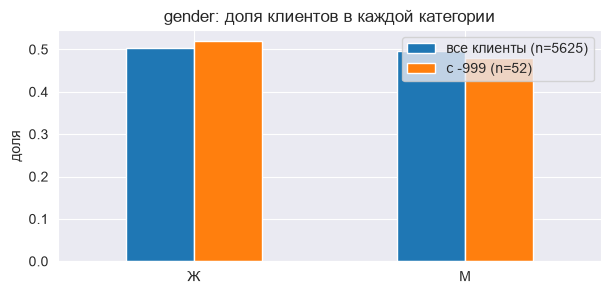

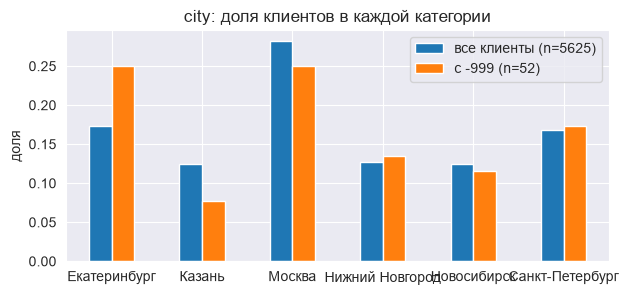

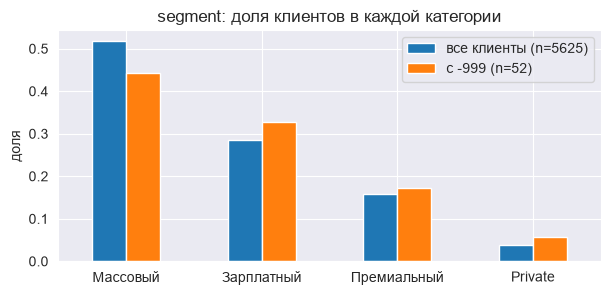

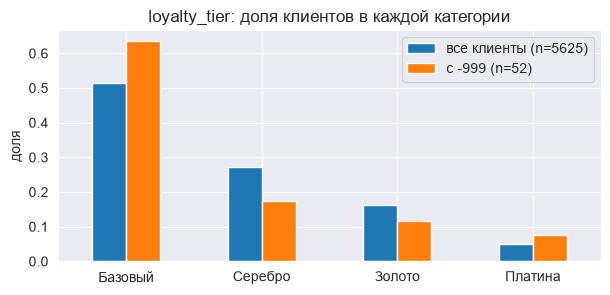

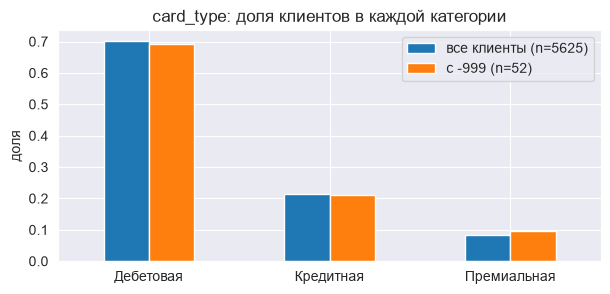

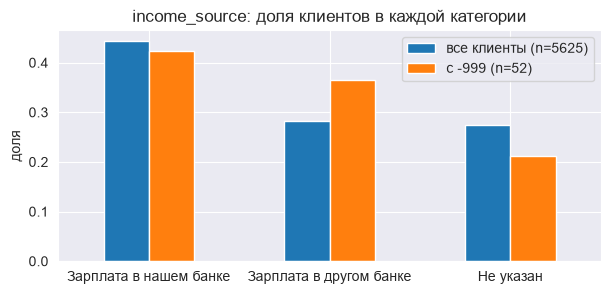

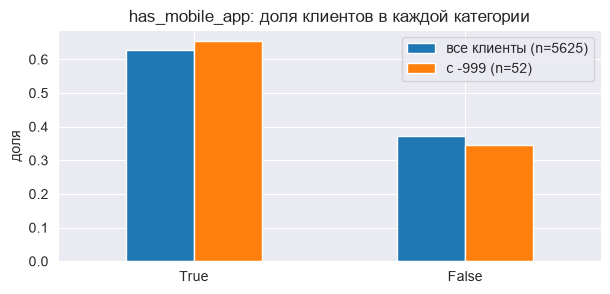

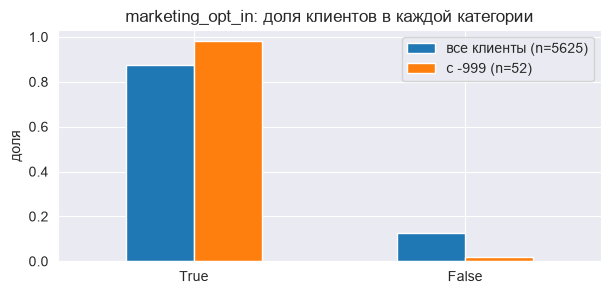

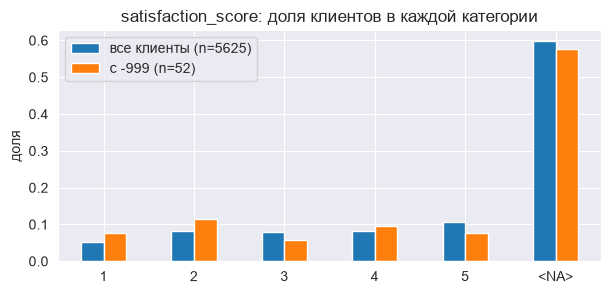

In [52]:
# Клиенты с -999 в monthly_income в сравнении со всеми
plot_compare(inc_999, 'с -999')

**−999 в `monthly_income`.** По графикам распределение клиентов с −999 по всем признакам примерно такое же, как у всех клиентов, явных отличий нет. Клиентов с −999 мало (52), поэтому небольшие колебания долей на графиках заметнее, чем они есть на самом деле. Клиенты с −999 не выделяются ни по сегменту, ни по уровню лояльности, ни по типу карты, поэтому −999 не похоже на метку для очень больших доходов или для какой-то особой группы. По смыслу это значение «доход неизвестен», поэтому заменяем его на пропуск.

In [53]:
# -999 в monthly_income: заменяем на пропуск
clients['monthly_income'] = clients['monthly_income'].mask(inc_999)
add_log('monthly_income', 'метка -999 вместо дохода', 'clients, monthly_income = -999', inc_999.sum(),
        '-999', 'исправлено', 'NaN',
        'клиенты с -999 по признакам не отличаются от остальных, это не метка особой группы, а неизвестный доход')

print('Осталось -999:', (clients['monthly_income'] == -999).sum())
print('Пропусков monthly_income теперь:', clients['monthly_income'].isna().sum())

Осталось -999: 0
Пропусков monthly_income теперь: 558


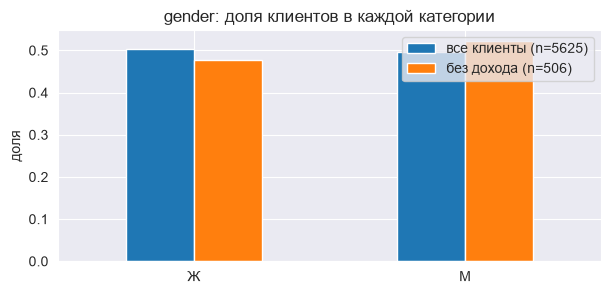

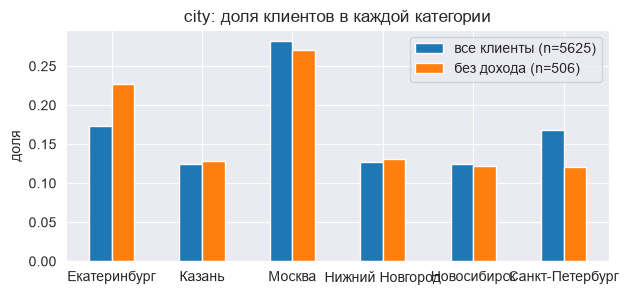

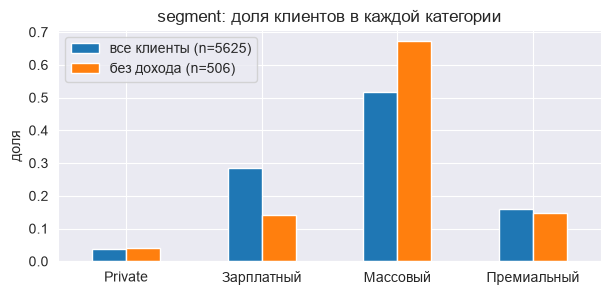

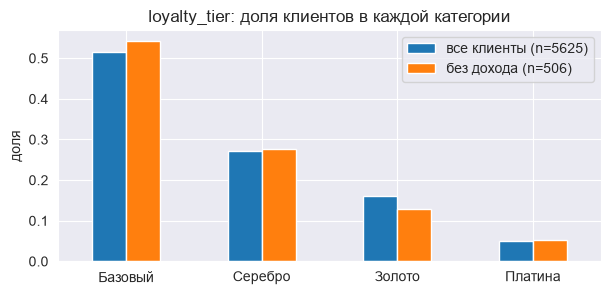

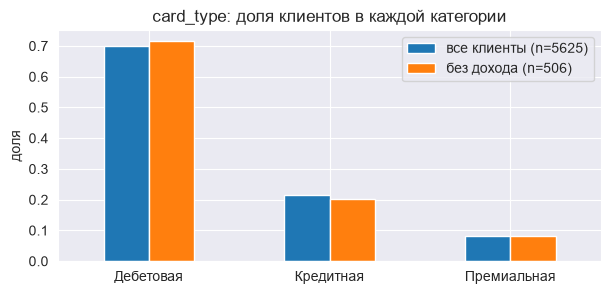

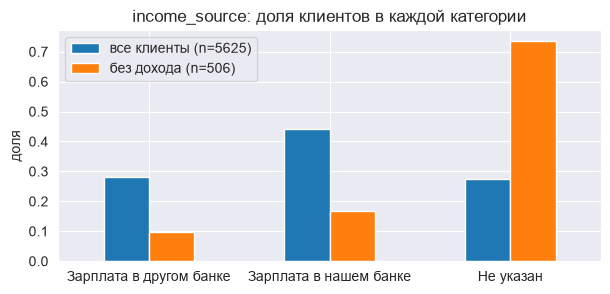

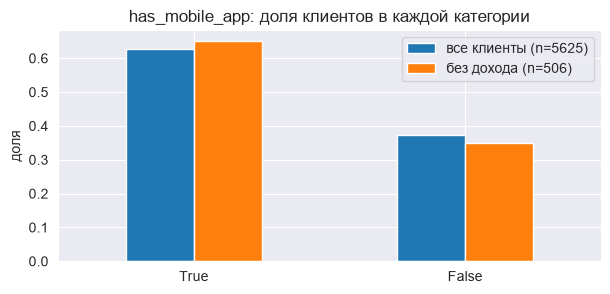

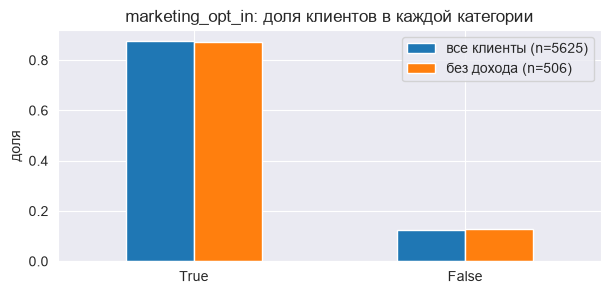

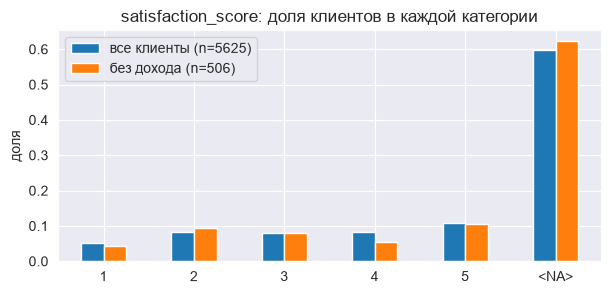

In [54]:
# Клиенты с исходным пропуском monthly_income в сравнении со всеми
plot_compare(inc_na, 'без дохода')

In [55]:
# Доли категорий у всех клиентов и у клиентов без дохода
for col in ['segment', 'income_source']:
    share = pd.DataFrame({
        'все клиенты': clients[col].value_counts(normalize=True),
        'без дохода': clients.loc[inc_na, col].value_counts(normalize=True),
    }).round(3)
    print(f'{col}, доля клиентов в каждой категории:')
    print(share.to_string())
    print()

segment, доля клиентов в каждой категории:
             все клиенты  без дохода
segment                             
Private            0.038       0.040
Зарплатный         0.286       0.140
Массовый           0.517       0.672
Премиальный        0.159       0.148

income_source, доля клиентов в каждой категории:
                         все клиенты  без дохода
income_source                                   
Зарплата в другом банке        0.282       0.099
Зарплата в нашем банке         0.443       0.166
Не указан                      0.275       0.735



**Пропуски `monthly_income`.** Клиенты без дохода (506) заметно отличаются от остальных по двум признакам. Источник зарплаты не указан у 73.5% из них, а среди всех клиентов у 27.5%. Массовых клиентов среди них 67.2% против 51.7% среди всех, а зарплатных вдвое меньше: 14.0% против 28.6%. У зарплатных клиентов зарплата приходит в банк, поэтому доход известен, а клиенты, не назвавшие источник зарплаты, чаще не называют и сумму. По остальным признакам заметных отличий нет. Доход мы не будем использовать для расчета активности и поэтому пропуски не заполняем: заполнение придумало бы доход для 9% клиентов, у некоторых из которых возможно он просто отсутствует.

In [56]:
add_log('monthly_income', 'нет дохода', 'clients, строки без дохода', clients['monthly_income'].isna().sum(),
        'NaN', 'оставлено', 'NaN',
        'пропуск связан с «Не указан» в income_source и с массовым сегментом. '
        'Доход не используется для расчёта активности, заполнение придумало бы доход, которого у части клиентов может не быть')

### 3.4. Выбросы

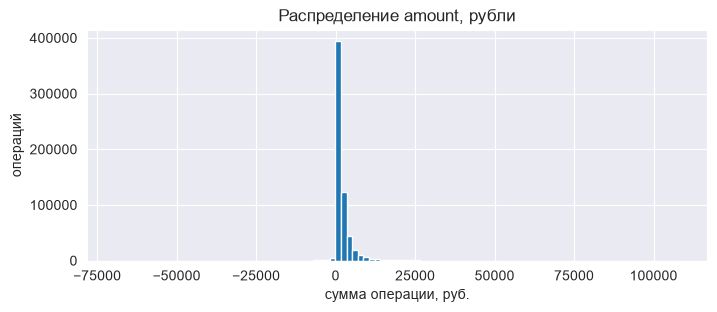

In [57]:
# Сумма операции в рублях
amt = transactions.loc[transactions['currency'] == 'RUB', 'amount']

plt.figure(figsize=(8, 3))
plt.hist(amt, bins=100)
plt.title('Распределение amount, рубли')
plt.xlabel('сумма операции, руб.')
plt.ylabel('операций')
plt.show()

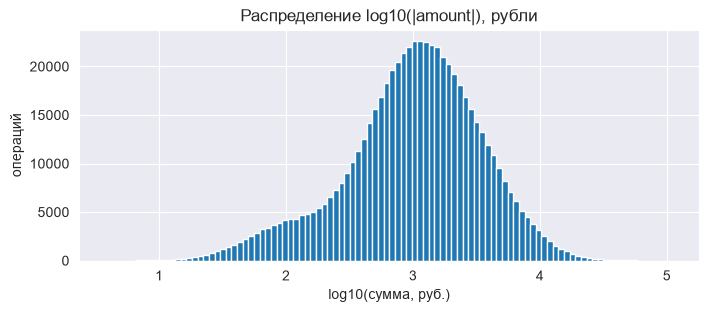

In [58]:
# Сумма операции в логарифмической шкале (возвраты отрицательные, поэтому по модулю)
plt.figure(figsize=(8, 3))
plt.hist(np.log10(amt.abs()), bins=100)
plt.title('Распределение log10(|amount|), рубли')
plt.xlabel('log10(сумма, руб.)')
plt.ylabel('операций')
plt.show()

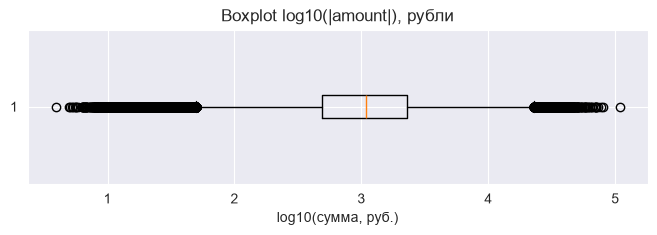

In [59]:
# Boxplot суммы операции, усы считаются по логарифмам
plt.figure(figsize=(8, 2))
plt.boxplot(np.log10(amt.abs()), orientation='horizontal')
plt.title('Boxplot log10(|amount|), рубли')
plt.xlabel('log10(сумма, руб.)')
plt.show()

**Выбросы в `amount`.** В обычной шкале распределение сумм сильно скошено вправо: почти все операции до нескольких тысяч рублей, а редкие крупные покупки растягивают хвост до 100 000. В логарифмической шкале распределение близко к симметричному с центром около 1 000 рублей и с утолщением слева, это большое число мелких операций. Отдельных кучек вдали от основной массы и разрывов нет. На boxplot точки идут сплошной полосой, без отдельной аномальной группы. Значений, похожих на ошибку, не видно, поэтому суммы оставляем как есть.

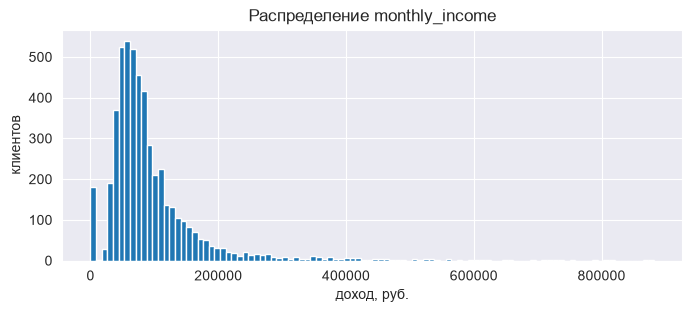

In [60]:
# Доход клиента
inc = clients['monthly_income'].dropna()

plt.figure(figsize=(8, 3))
plt.hist(inc, bins=100)
plt.title('Распределение monthly_income')
plt.xlabel('доход, руб.')
plt.ylabel('клиентов')
plt.show()

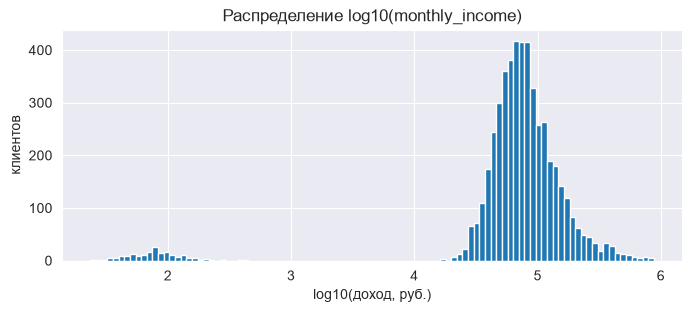

In [61]:
# Доход в логарифмической шкале
plt.figure(figsize=(8, 3))
plt.hist(np.log10(inc), bins=100)
plt.title('Распределение log10(monthly_income)')
plt.xlabel('log10(доход, руб.)')
plt.ylabel('клиентов')
plt.show()

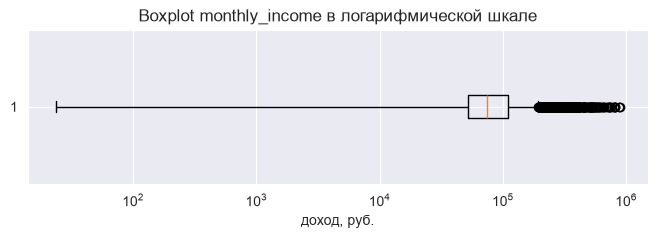

In [62]:
# Boxplot дохода в логарифмической шкале
plt.figure(figsize=(8, 2))
plt.boxplot(inc, orientation='horizontal')
plt.xscale('log')
plt.title('Boxplot monthly_income в логарифмической шкале')
plt.xlabel('доход, руб.')
plt.show()

In [63]:
# Значения меньше 1000 и ближайшее значение выше
small = inc[inc < 1000]
print(f'Доходов меньше 1000: {len(small)} из {len(inc)}')
print(f'Их диапазон: от {small.min()} до {small.max()}')
print(f'Самый маленький доход от 1000 и выше: {inc[inc >= 1000].min()}')

Доходов меньше 1000: 180 из 5067
Их диапазон: от 23.6 до 442.7
Самый маленький доход от 1000 и выше: 16900.0


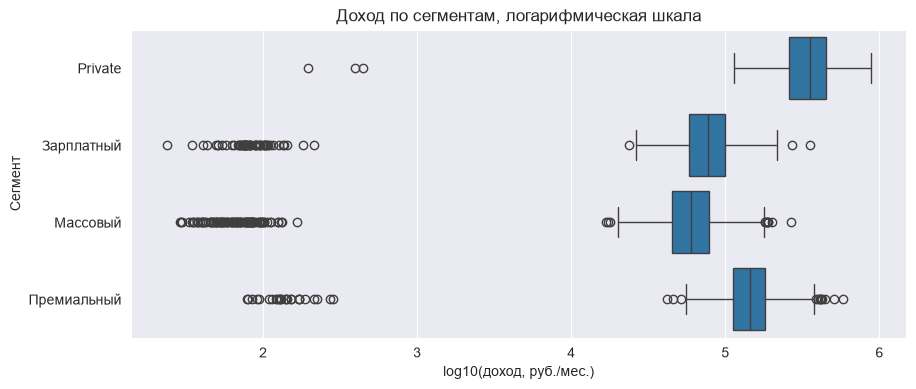

In [64]:
# Доход по сегментам в логарифмической шкале
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(x=np.log10(clients['monthly_income']), y=clients['segment'], ax=ax)
ax.set_title('Доход по сегментам, логарифмическая шкала')
ax.set_xlabel('log10(доход, руб./мес.)')
ax.set_ylabel('Сегмент')
plt.show()

In [65]:
# Вариант 1: умножить на 1000, вариант 2: заменить медианой сегмента
small = clients['monthly_income'] < 1000
seg_median = clients.loc[~small, 'monthly_income'].groupby(clients['segment'], observed=True).median()

income_x1000 = clients['monthly_income'].where(~small, clients['monthly_income'] * 1000)
income_median = clients['monthly_income'].where(~small, clients['segment'].map(seg_median).astype(float))

print(f'Доходов меньше 1000: {small.sum()} из {clients["monthly_income"].notna().sum()}')
print()
print('Медиана сегмента, которой заменяем во втором варианте:')
print(seg_median.to_string())

Доходов меньше 1000: 180 из 5067

Медиана сегмента, которой заменяем во втором варианте:
segment
Private        352900.0
Зарплатный      79100.0
Массовый        61000.0
Премиальный    145100.0


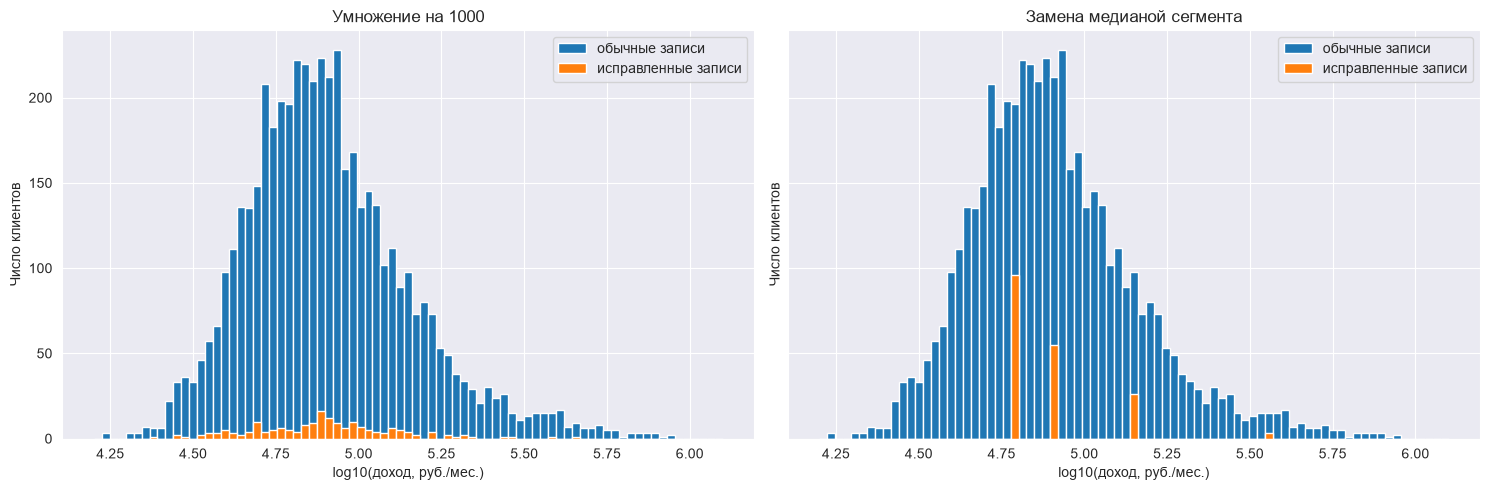

In [66]:
# Сравнение двух вариантов на гистограммах
bins = np.linspace(4.2, 6.1, 80)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, fixed, title in [(axes[0], income_x1000, 'Умножение на 1000'),
                         (axes[1], income_median, 'Замена медианой сегмента')]:
    ax.hist(np.log10(clients.loc[~small, 'monthly_income'].dropna()), bins=bins, label='обычные записи')
    ax.hist(np.log10(fixed[small]), bins=bins, label='исправленные записи')
    ax.set_title(title)
    ax.set_xlabel('log10(доход, руб./мес.)')
    ax.set_ylabel('Число клиентов')
    ax.legend()

plt.tight_layout()
plt.show()

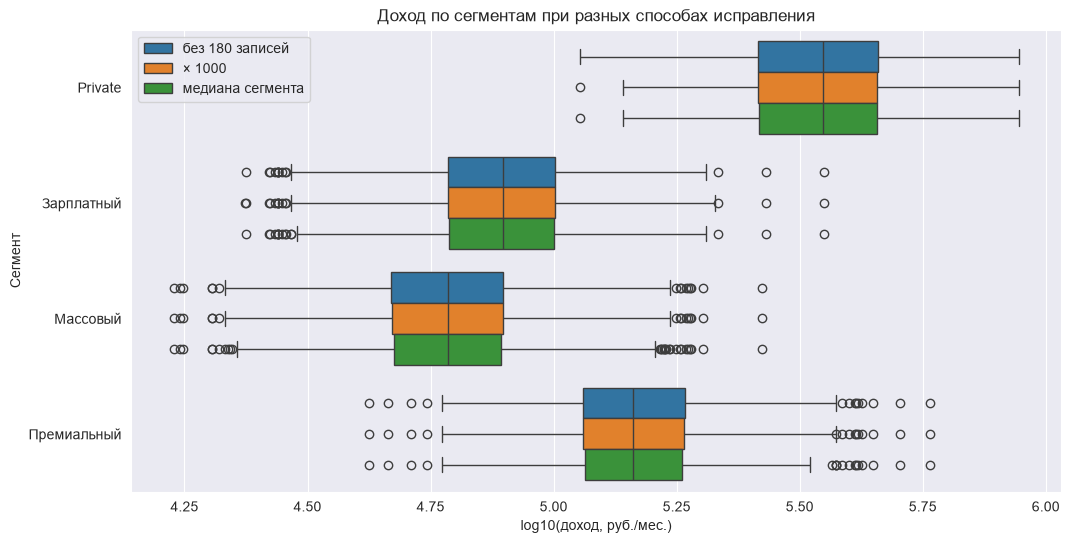

In [67]:
# Boxplot по сегментам: без подозрительных записей, умножение на 1000, замена медианой
compare = pd.concat([
    pd.DataFrame({'segment': clients.loc[~small, 'segment'], 'income': clients.loc[~small, 'monthly_income'],
                  'вариант': f'без {small.sum()} записей'}),
    pd.DataFrame({'segment': clients['segment'], 'income': income_x1000, 'вариант': '× 1000'}),
    pd.DataFrame({'segment': clients['segment'], 'income': income_median, 'вариант': 'медиана сегмента'}),
]).dropna()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=compare, x=np.log10(compare['income']), y='segment', hue='вариант', ax=ax)
ax.set_title('Доход по сегментам при разных способах исправления')
ax.set_xlabel('log10(доход, руб./мес.)')
ax.set_ylabel('Сегмент')
ax.legend(title='')
plt.show()

In [68]:
# Доходы меньше 1000 умножаем на 1000
clients['monthly_income'] = income_x1000
add_log('monthly_income', 'доход записан в тысячах рублей', 'clients, monthly_income меньше 1000', small.sum(),
        'от 23.6 до 442.7', 'исправлено', 'от 23 600 до 442 700',
        'после умножения значения ложатся по всему распределению своего сегмента, '
        'замена медианой создала бы искусственные пики')

print('Минимальный доход теперь:', clients['monthly_income'].min())

Минимальный доход теперь: 16900.0


In [69]:
# Возраст на дату справочника 30.06.2025
age = (pd.Timestamp('2025-06-30') - clients['birth_date']).dt.days / 365.25
print('Возраст клиентов на 30.06.2025:')
print(age.describe().round(1).to_string())

Возраст клиентов на 30.06.2025:
count    5625.0
mean       53.7
std        14.0
min        22.6
25%        43.3
50%        51.8
75%        62.3
max        88.9


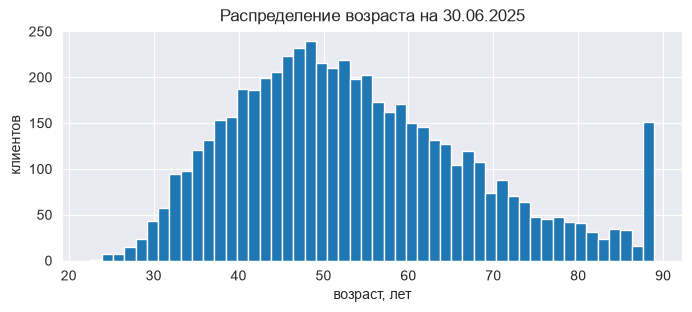

In [70]:
# Распределение возраста
plt.figure(figsize=(8, 3))
plt.hist(age, bins=50)
plt.title('Распределение возраста на 30.06.2025')
plt.xlabel('возраст, лет')
plt.ylabel('клиентов')
plt.show()

In [71]:
# Пик в конце распределения возраста
old = age >= 88
print(f'Клиентов от 88 лет: {old.sum()} из {len(clients)}')
print('Их даты рождения: от', clients.loc[old, 'birth_date'].min().date(),
      'до', clients.loc[old, 'birth_date'].max().date())
print()
print('Клиентов по году рождения (самые ранние годы):')
print(clients['birth_date'].dt.year.value_counts().sort_index().head(6).to_string())

Клиентов от 88 лет: 138 из 5625
Их даты рождения: от 1936-07-23 до 1937-06-27

Клиентов по году рождения (самые ранние годы):
birth_date
1936    56
1937    96
1938     9
1939    27
1940    21
1941    27


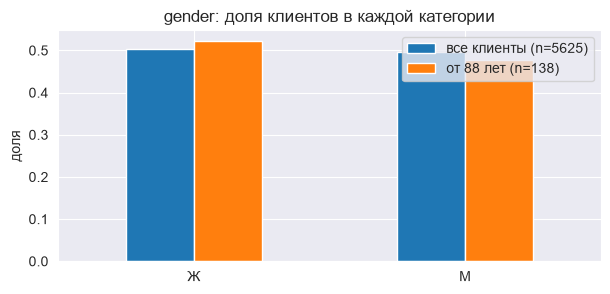

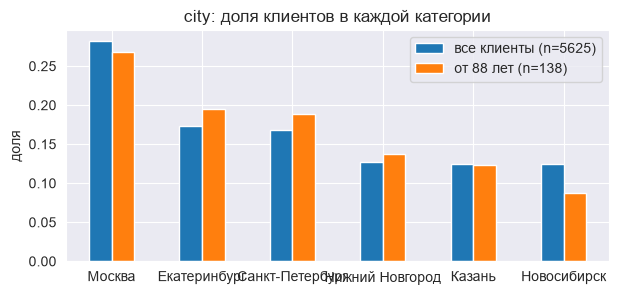

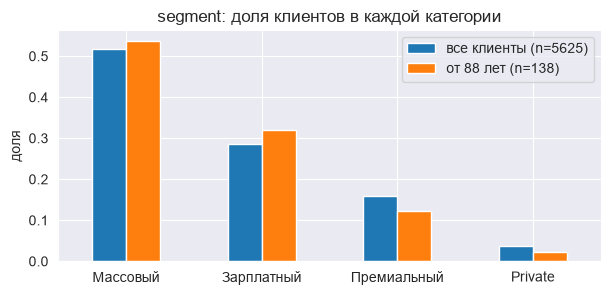

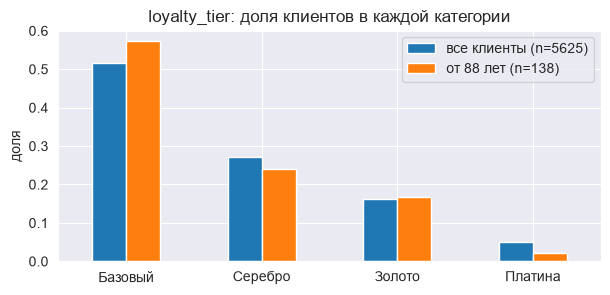

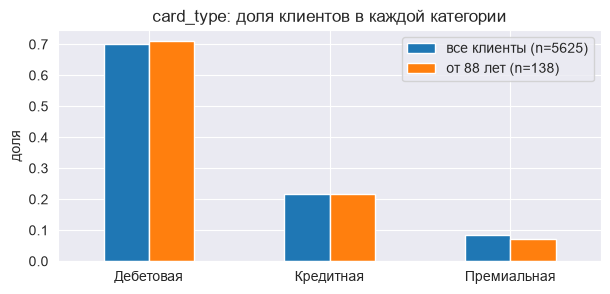

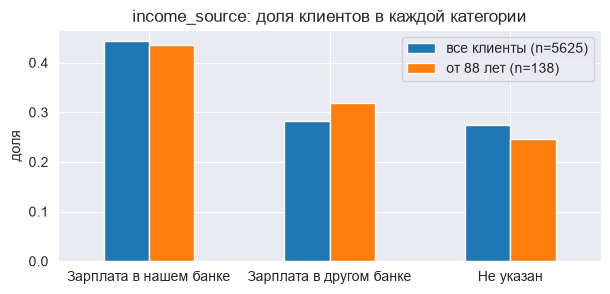

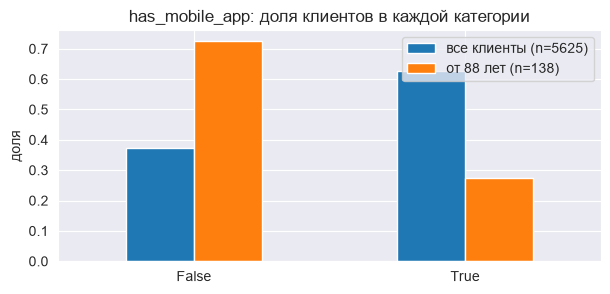

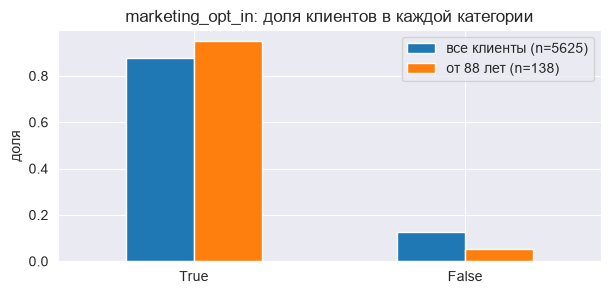

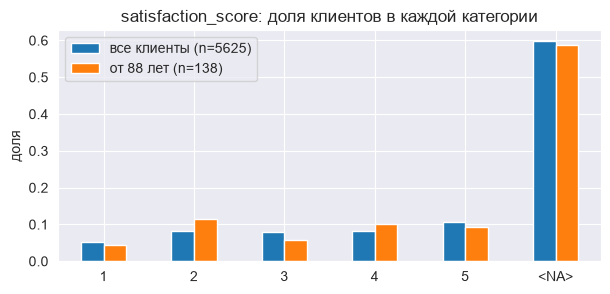

In [72]:
# Клиенты от 88 лет в сравнении со всеми
plot_compare(old, 'от 88 лет')

In [73]:
add_log('birth_date', 'пик клиентов 88 лет, похоже на обрезку возраста сверху', 'clients, возраст от 88 лет', old.sum(),
        'даты рождения 1936–1937', 'оставлено', 'без изменений',
        'по остальным признакам эти клиенты не отличаются от других, только по наличию мобильного приложения, но это логично для людей в возрасте; настоящий возраст скорее всего больше 88, но он неизвестен, поэтому оставляем как есть')

In [74]:
# Диапазоны дат
for col in ['birth_date', 'registration_date', 'card_open_date', 'app_last_login']:
    print(f'{col}: от {clients[col].min()} до {clients[col].max()}')

birth_date: от 1936-07-23 00:00:00 до 2002-12-08 00:00:00
registration_date: от 2010-01-13 00:00:00 до 2025-05-05 00:00:00
card_open_date: от 2016-01-01 00:00:00 до 2025-05-16 00:00:00
app_last_login: от 2024-01 до 2025-06


In [75]:
# Логический порядок дат
report_date = pd.Timestamp('2025-06-30')
age_at_reg = (clients['registration_date'] - clients['birth_date']).dt.days / 365.25
reg_month = clients['registration_date'].dt.to_period('M')

checks = {
    'карта открыта раньше прихода в банк': clients['card_open_date'] < clients['registration_date'],
    'приход в банк позже 30.06.2025': clients['registration_date'] > report_date,
    'карта открыта позже 30.06.2025': clients['card_open_date'] > report_date,
    'в банк пришёл младше 18 лет': age_at_reg < 18,
    'последний вход в приложение раньше прихода в банк': clients['app_last_login'] < reg_month,
}
for name, mask in checks.items():
    print(f'{name}: {mask.sum()} из {len(clients)}')

карта открыта раньше прихода в банк: 0 из 5625
приход в банк позже 30.06.2025: 0 из 5625
карта открыта позже 30.06.2025: 0 из 5625
в банк пришёл младше 18 лет: 27 из 5625
последний вход в приложение раньше прихода в банк: 22 из 5625


In [76]:
# Самый младший возраст на дату прихода в банк
print(f'Минимальный возраст на дату прихода в банк: {age_at_reg.min():.1f} лет')

Минимальный возраст на дату прихода в банк: 13.0 лет


In [77]:
add_log('registration_date, birth_date', 'клиент пришёл в банк младше 18 лет',
        'clients, клиенты, пришедшие в банк до 18 лет', (age_at_reg < 18).sum(),
        f'самому младшему на момент прихода {age_at_reg.min():.0f} лет', 'оставлено', 'без изменений',
        'карту можно оформить подростку с разрешения родителей, значения правдоподобны')

In [78]:
# Дата первой операции каждого клиента
first_txn = transactions.groupby('client_id')['txn_datetime'].min()
first = clients['client_id'].map(first_txn)

print(f'Клиентов с операциями раньше прихода в банк: {(first < clients["registration_date"]).sum()} из {first.notna().sum()}')
print(f'Клиентов с операциями раньше открытия карты: {(first < clients["card_open_date"]).sum()} из {first.notna().sum()}')

Клиентов с операциями раньше прихода в банк: 0 из 5619
Клиентов с операциями раньше открытия карты: 0 из 5619


In [79]:
# Последний вход в приложение раньше прихода в банк: заменяем месяцем прихода
early_login = clients['app_last_login'] < clients['registration_date'].dt.to_period('M')
example_before = clients.loc[early_login, 'app_last_login'].iloc[0]
example_reg = clients.loc[early_login, 'registration_date'].dt.to_period('M').iloc[0]

clients.loc[early_login, 'app_last_login'] = clients.loc[early_login, 'registration_date'].dt.to_period('M')
add_log('app_last_login', 'последний вход в приложение раньше прихода в банк',
        'clients, app_last_login раньше registration_date', early_login.sum(),
        f'вход {example_before}, приход {example_reg}', 'исправлено', f'вход {example_reg}',
        'войти в приложение до прихода в банк нельзя; операций до прихода в банк нет, поэтому скорее всего просто ошибка записи данных; ставим минимально возможную дату входа - месяц прихода')

print(f'Заменено: {early_login.sum()}')
print('Осталось входов раньше прихода:',
      (clients['app_last_login'] < clients['registration_date'].dt.to_period('M')).sum())

Заменено: 22
Осталось входов раньше прихода: 0


In [80]:
# Операции вне периода 01.01.2024–30.06.2025
period_start, period_end = pd.Timestamp('2024-01-01'), pd.Timestamp('2025-06-30 23:59:59')
out_of_period = (transactions['txn_datetime'] < period_start) | (transactions['txn_datetime'] > period_end)
print(f'Операций вне периода: {out_of_period.sum()} из {len(transactions)}')
print('По месяцам:')
print(transactions.loc[out_of_period, 'txn_datetime'].dt.to_period('M').value_counts().sort_index().to_string())

Операций вне периода: 88 из 617507
По месяцам:
txn_datetime
2023-11    2
2023-12    7
2025-07    3
2025-08    6
2025-09    6
2025-10    7
2025-11    8
2025-12    9
2026-01    4
2026-02    5
2026-03    7
2026-04    4
2026-05    9
2026-06    3
2026-07    5
2026-08    3
Freq: M


In [81]:
# Блок txn_id от 990000: номера отдельно от остальных
ids = transactions['txn_id'].astype(int)
block = ids >= 990000
print(f'Основные txn_id: от {ids[~block].min()} до {ids[~block].max()}')
print(f'Блок txn_id: от {ids[block].min()} до {ids[block].max()}, операций {block.sum()}')
print()
print(f'Операций вне периода в блоке: {(out_of_period & block).sum()} из {out_of_period.sum()}')
print(f'Операций вне периода вне блока: {(out_of_period & ~block).sum()}')

Основные txn_id: от 100001 до 722558
Блок txn_id: от 990001 до 990220, операций 220

Операций вне периода в блоке: 88 из 88
Операций вне периода вне блока: 0


In [82]:
# Разница дат между соседними txn_id
ids = transactions['txn_id'].astype(int)
is_block = ids >= 990000

for name, part in [('основная нумерация', transactions[~is_block]), ('блок 990xxx', transactions[is_block])]:
    part = part.assign(num=ids[part.index]).sort_values('num')
    gap = part['txn_datetime'].diff()
    print(f'{name}: операций {len(part)}')
    print(f'  разница дат у соседних номеров: от {gap.min()} до {gap.max()}')
    print()

основная нумерация: операций 617287
  разница дат у соседних номеров: от -1 days +00:00:37 до 1 days 03:58:55

блок 990xxx: операций 220
  разница дат у соседних номеров: от -868 days +00:05:19 до 957 days 06:06:20



In [83]:
# Распределение признака у обычных операций и у блока (доли внутри каждой группы)
def plot_compare_txn(mask, group_name):
    for col in ['status', 'channel', 'currency', 'category']:
        share = pd.DataFrame({
            f'обычные (n={(~mask).sum()})': transactions.loc[~mask, col].value_counts(normalize=True),
            f'{group_name} (n={mask.sum()})': transactions.loc[mask, col].value_counts(normalize=True),
        }).fillna(0)

        ax = share.plot.bar(figsize=(8, 3), rot=0 if col != 'category' else 45)
        ax.set_title(f'{col}: доля операций в каждой категории')
        ax.set_xlabel('')
        ax.set_ylabel('доля')
        plt.show()

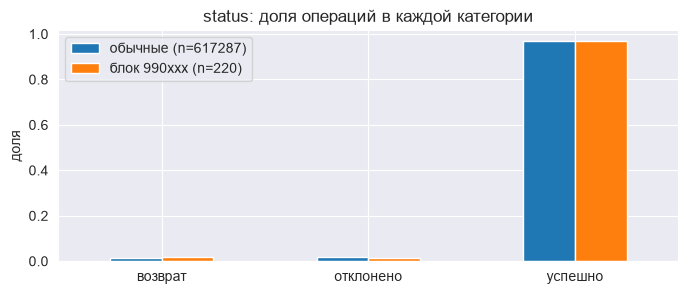

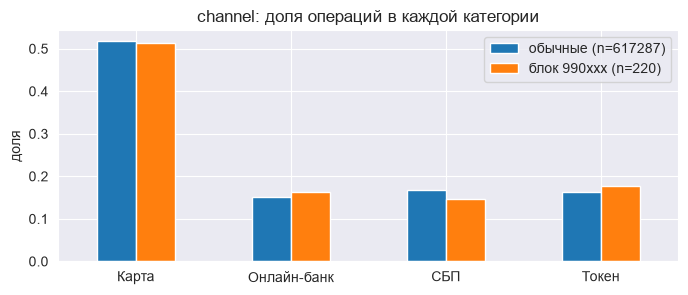

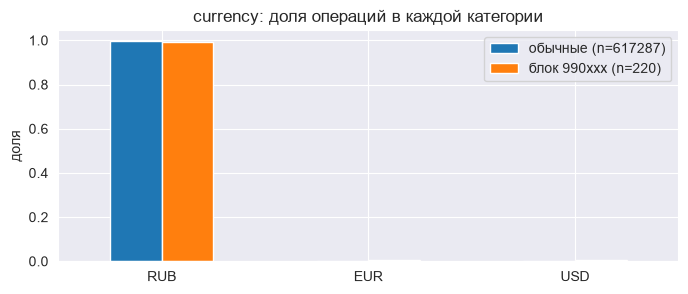

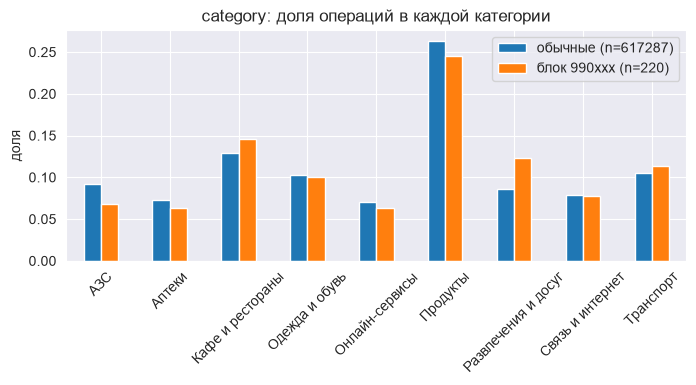

In [84]:
# Блок 990xxx в сравнении с обычными операциями
ids = transactions['txn_id'].astype(int)
is_block = ids >= 990000
plot_compare_txn(is_block, 'блок 990xxx')

In [85]:
# Блок txn_id 990001–990220: дата не согласована с номером, удаляем
n_before = len(transactions)

transactions = transactions[~is_block]
add_log('все поля', 'блок номеров отдельно от основной нумерации, даты не согласованы с номерами',
        'transactions, txn_id от 990000', n_before - len(transactions),
        'номера 990001–990220, даты с 2023 по 2026 вразнобой', 'удалено', 'строк нет',
        'даты в блоке не связаны с номерами, в основной нумерации такой проблемы нет;'
        ' по распределению характеристик операции не отличаются от остальных, '
        'поэтому скорее всего даты операций перепутаны или операции выгружены из другой системы;'
        ' удаляем, чтобы операции с ненадёжной датой не попали не в тот период при расчёте активности')

print(f'Удалено операций: {n_before - len(transactions)}')
print(f'Осталось: {len(transactions)}')
print('Первая операция:', transactions['txn_datetime'].min())
print('Последняя операция:', transactions['txn_datetime'].max())

Удалено операций: 220
Осталось: 617287
Первая операция: 2024-01-01 00:00:00
Последняя операция: 2025-06-30 23:59:41


In [86]:
# Возраст вместо даты рождения
clients['age'] = age.astype(int)
clients = clients.drop(columns='birth_date')

add_log('birth_date, age', 'для анализа будем использовать возраст, а не дату рождения', 'clients, все строки', len(clients),
        f'дата рождения', 'исправлено', 'возраст (полных лет на 30.06.2025)',
        'для анализа важен возраст клиента, а не конкретная дата рождения')

print('Столбцы clients:', list(clients.columns))

Столбцы clients: ['client_id', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_date', 'card_open_date', 'income_source', 'monthly_income', 'has_mobile_app', 'app_last_login', 'satisfaction_score', 'marketing_opt_in', 'age']


### 3.5. Фильтры, применяемые перед расчётом активности

In [87]:
# Воронка по клиентам: удаляем тех, для кого активность посчитать нельзя
ok = transactions['status'] == 'успешно'
funnel = [('Клиенты перед применением фильтра', len(clients))]

# 1. Есть успешные операции
n = len(clients)
clients = clients[clients['client_id'].isin(transactions.loc[ok, 'client_id'])]
funnel.append(('Есть успешные операции', len(clients)))
add_log('все поля', 'у клиента нет успешных операций', 'clients, клиенты без успешных операций', n - len(clients),
        'нет операций', 'удалено', 'только клиенты с операциями',
        'активность без операций посчитать нельзя')

# 2. Карта открыта до 01.01.2024
n = len(clients)
clients = clients[clients['card_open_date'] < '2024-01-01']
funnel.append(('Текущая карта открыта до 2024 года (полный базовый год)', len(clients)))
add_log('все поля', 'карта открыта в 2024–2025 годах', 'clients, card_open_date от 01.01.2024', n - len(clients),
        'карта открыта в 2024–2025 годах', 'удалено', 'карта открыта до 01.01.2024',
        'операций до открытия карты нет, у таких клиентов нет полного базового года для сравнения')

# 3. В 2024 году хотя бы одна успешная операция в месяц
base_per_month = transactions[ok & (transactions['txn_datetime'] < '2025-01-01')].groupby('client_id').size() / 12
n = len(clients)
clients = clients[clients['client_id'].map(base_per_month).fillna(0) >= 1]
funnel.append(('В 2024 году не меньше 1 операции в месяц', len(clients)))
add_log('все поля', 'в 2024 году меньше одной операции в месяц', 'clients, меньше 1 успешной операции в месяц в 2024',
        n - len(clients), 'меньше 1 операции в месяц', 'удалено', 'от 1 операции в месяц',
        'при почти нулевой базе падение активности посчитать нельзя')

funnel_df = pd.DataFrame(funnel, columns=['шаг', 'осталось клиентов'])
funnel_df['ушло'] = (-funnel_df['осталось клиентов'].diff()).fillna(0).astype(int)
funnel_df

,шаг,осталось клиентов,ушло
0,Клиенты перед применением фильтра,5625,0
1,Есть успешные операции,5619,6
2,Текущая карта открыта до 2024 года (полный баз...,4846,773
3,В 2024 году не меньше 1 операции в месяц,4839,7


In [88]:
# Операции: оставляем только клиентов, которые остались в clients
n = len(transactions)
transactions = transactions[transactions['client_id'].isin(clients['client_id'])]
add_log('все поля', 'операции клиентов, которых нет в итоговом clients', 'transactions, client_id не из clients',
        n - len(transactions), 'операции клиентов не из справочника и клиентов, не прошедших фильтры', 'удалено',
        'операции только клиентов, для которых считаем активность',
        'у клиентов не из справочника нет признаков и согласия, остальные клиенты не прошли фильтры выше')

# Для расчёта активности берём только успешные операции, transactions целиком сохраняем
ok_txn = transactions[transactions['status'] == 'успешно']

print(f'Операций было: {n}')
print(f'Ушло: {n - len(transactions)}')
print(f'Осталось в transactions: {len(transactions)}')
print(f'Из них успешных, ok_txn: {len(ok_txn)}')

Операций было: 617287
Ушло: 41843
Осталось в transactions: 575444
Из них успешных, ok_txn: 557311


In [89]:
# Среднее число успешных операций в месяц в 2024 году — отдельным столбцом
ops_2024 = ok_txn[ok_txn['txn_datetime'] < '2025-01-01'].groupby('client_id').size() / 12
clients['ops_per_month_2024'] = clients['client_id'].map(ops_2024)

add_log('ops_per_month_2024', 'нужно среднее число успешных операций клиента в месяц за 2024 год', 'clients, все строки',
        len(clients), 'столбца нет', 'добавлено', 'успешных операций за 2024 год / 12',
        'считаем только по 2024 году, чтобы видеть обычный уровень клиента без изменений 2025 года; понадобится в разведочном анализе и для сравнения 2025 года с 2024')

print('Успешных операций в месяц в 2024 году:')
print(clients['ops_per_month_2024'].describe().round(1).to_string())

Успешных операций в месяц в 2024 году:
count    4839.0
mean        6.9
std         4.1
min         1.0
25%         4.1
50%         5.9
75%         8.7
max        52.0


In [90]:
# Журнал изменений: собираем из записей раздела 3
cleaning_log = pd.DataFrame(log_rows, columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])
print('Записей в журнале:', len(cleaning_log))
cleaning_log

Записей в журнале: 30


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,все поля,полные дубли строк,"clients, строки, совпадающие целиком",41,две одинаковые строки,удалено,одна строка,"повтор выгрузки, новой информации не несёт"
1,все поля,полные дубли строк,"transactions, строки, совпадающие целиком",1272,две одинаковые строки,удалено,одна строка,"повтор выгрузки, иначе одна операция посчитает..."
2,все поля,у одного client_id несколько строк с разными з...,"clients, строки с одинаковым client_id, но раз...",14,две версии строки клиента,удалено,последняя строка по client_id,"верную версию по данным не определить, носудя ..."
3,"birth_date, registration_date, card_open_date,...",даты записаны строками,"clients, все строки с заполненной датой",5625,"строки ГГГГ-ММ-ДД, ДД.ММ.ГГГГ, ГГГГ-ММ",исправлено,"datetime, app_last_login как месяц","значение не меняется, меняется только тип, что..."
4,txn_datetime,"дата записана строкой, часть без времени","transactions, все строки",617735,строки ГГГГ-ММ-ДД ЧЧ:ММ:СС и ГГГГ-ММ-ДД,исправлено,"datetime, у строк без времени 00:00:00","меняем тип, чтобы с датами можно было работать..."
5,txn_datetime,"одна операция записана дважды, с временем и без","transactions, строки с одинаковым txn_id, одна...",228,2024-01-03 13:29:31 и 2024-01-03 00:00:00,удалено,2024-01-03 13:29:31,"день совпадает у всех 228 пар, строка со време..."
6,"has_mobile_app, marketing_opt_in",да/нет записаны текстом,"clients, все строки",5625,Да / Нет,исправлено,True / False,"значение не меняется, меняется только тип, что..."
7,satisfaction_score,целая оценка хранится как дробное число из-за ...,"clients, все строки",5625,5.0,исправлено,5,"значение не меняется, меняется только тип, оце..."
8,city,один город записан разными способами,"clients, строки, где город записан не полным н...",1604,"«г. Москва», « москва», «СПб»",исправлено,"«Москва», «Санкт-Петербург»","это одни и те же города в разных написаниях, с..."
9,category,одна категория записана разными способами,"transactions, строки с вариантами «Кафе/рестор...",51337,"«Кафе/рестораны», «Связь и Интернет»",исправлено,"«Кафе и рестораны», «Связь и интернет»",это одни и те же категории в разных написаниях...


## 5. Разведочный анализ

### 5.1. Распределения количественных признаков

In [91]:
# Числовые признаки клиентов
num = pd.DataFrame({
    'возраст, лет': clients['age'],
    'доход, руб.': clients['monthly_income'],
    'успешных операций в месяц в 2024': clients['ops_per_month_2024'],
})
print('Описательные статистики числовых признаков клиентов:')
print(num.describe().round(1).to_string())

Описательные статистики числовых признаков клиентов:
       возраст, лет  доход, руб.  успешных операций в месяц в 2024
count        4839.0       4359.0                            4839.0
mean           53.2      96704.1                               6.9
std            13.9      77965.7                               4.1
min            22.0      16900.0                               1.0
25%            43.0      54650.0                               4.1
50%            51.0      75700.0                               5.9
75%            62.0     109000.0                               8.7
max            88.0     882300.0                              52.0


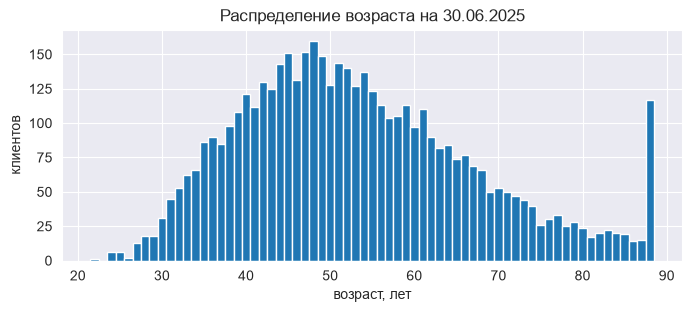

In [92]:
# Распределение возраста
plt.figure(figsize=(8, 3))
plt.hist(clients['age'], bins=np.arange(clients['age'].min(), clients['age'].max() + 2) - 0.5)
plt.title('Распределение возраста на 30.06.2025')
plt.xlabel('возраст, лет')
plt.ylabel('клиентов')
plt.show()

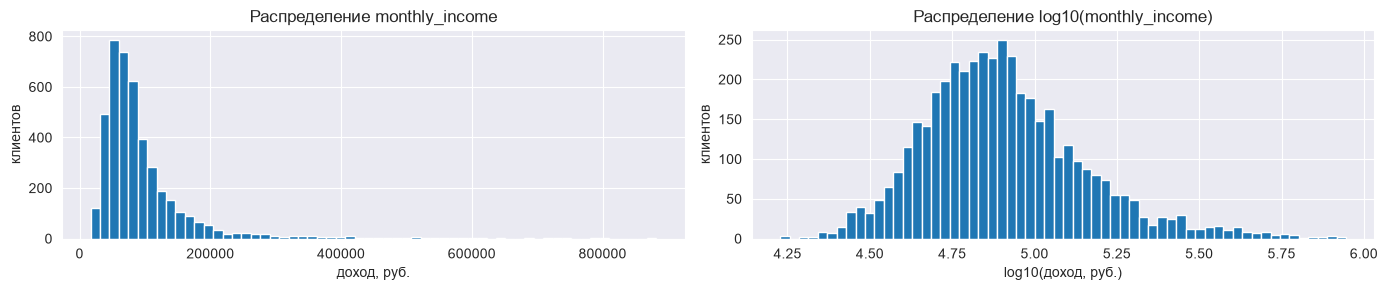

In [93]:
# Распределение дохода: обычная и логарифмическая шкала
inc = clients['monthly_income'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].hist(inc, bins=60)
axes[0].set_title('Распределение monthly_income')
axes[0].set_xlabel('доход, руб.')
axes[1].hist(np.log10(inc), bins=60)
axes[1].set_title('Распределение log10(monthly_income)')
axes[1].set_xlabel('log10(доход, руб.)')
for ax in axes:
    ax.set_ylabel('клиентов')
plt.tight_layout()
plt.show()

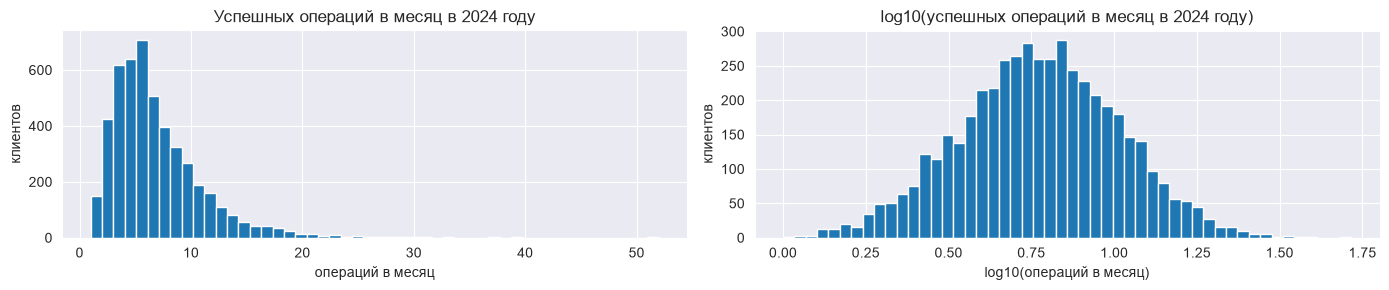

In [94]:
# Распределение числа операций в месяц в 2024 году: обычная и логарифмическая шкала
ops = clients['ops_per_month_2024']
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].hist(ops, bins=50)
axes[0].set_title('Успешных операций в месяц в 2024 году')
axes[0].set_xlabel('операций в месяц')
axes[1].hist(np.log10(ops), bins=50)
axes[1].set_title('log10(успешных операций в месяц в 2024 году)')
axes[1].set_xlabel('log10(операций в месяц)')
for ax in axes:
    ax.set_ylabel('клиентов')
plt.tight_layout()
plt.show()

In [95]:
# Сумма успешной операции по валютам
print('Описательные статистики суммы успешной операции по валютам:')
print(ok_txn.groupby('currency', observed=True)['amount'].describe().T.round(1))

Описательные статистики суммы успешной операции по валютам:
currency     EUR       RUB     USD
count     1190.0  555008.0  1113.0
mean        19.5    1880.5    19.6
std         25.3    2557.5    26.7
min          0.1       3.9     0.1
25%          5.1     490.0     5.0
50%         12.0    1083.0    11.3
75%         23.7    2261.5    22.8
max        282.2  108042.2   283.0


In [96]:
# Доля операций в каждой валюте (успешные операции)
cur_counts = ok_txn['currency'].value_counts()
for cur, k in cur_counts.items():
    print(f'{cur}: {k} из {len(ok_txn)} ({k / len(ok_txn):.2%})')

RUB: 555008 из 557311 (99.59%)
EUR: 1190 из 557311 (0.21%)
USD: 1113 из 557311 (0.20%)


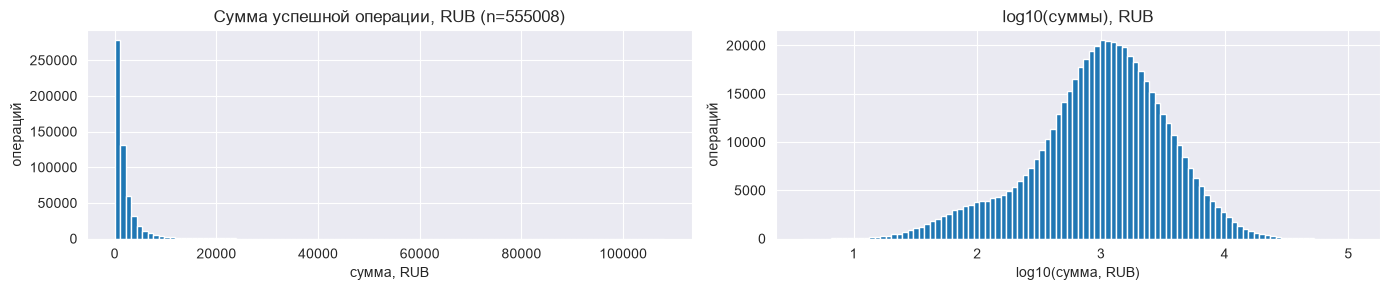

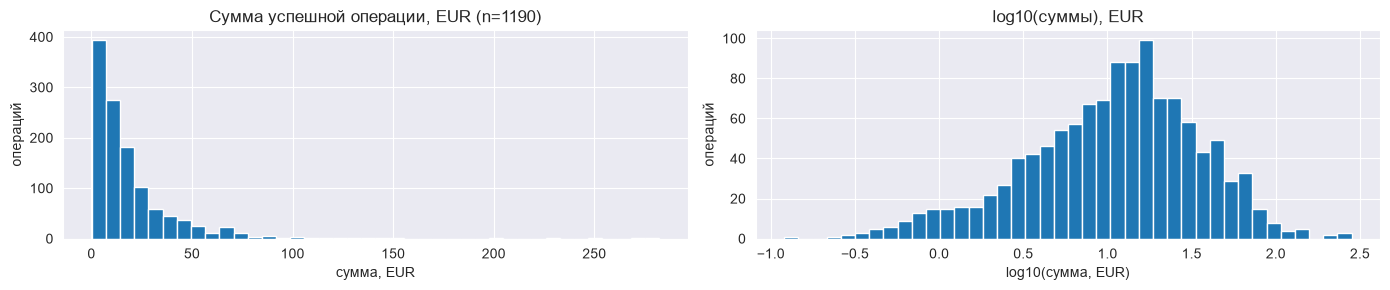

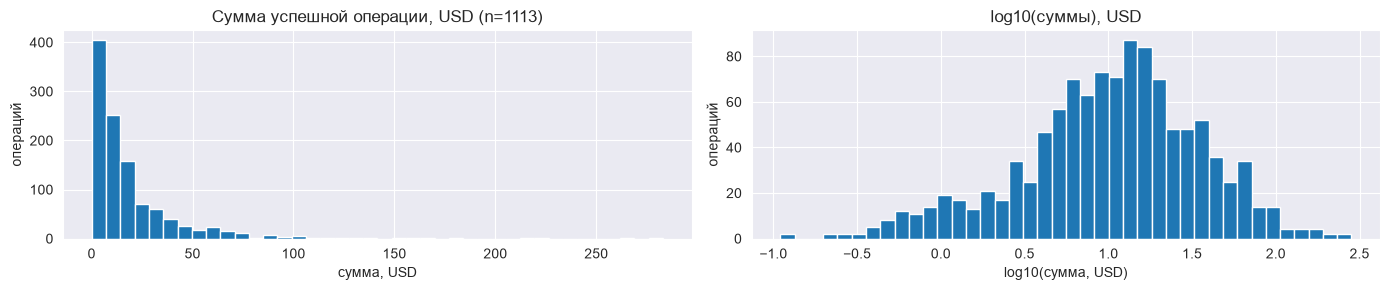

In [97]:
# Распределение суммы по валютам: обычная и логарифмическая шкала
for cur in ['RUB', 'EUR', 'USD']:
    amt = ok_txn.loc[ok_txn['currency'] == cur, 'amount']
    fig, axes = plt.subplots(1, 2, figsize=(14, 3))
    axes[0].hist(amt, bins=100 if cur == 'RUB' else 40)
    axes[0].set_title(f'Сумма успешной операции, {cur} (n={len(amt)})')
    axes[0].set_xlabel(f'сумма, {cur}')
    axes[1].hist(np.log10(amt), bins=100 if cur == 'RUB' else 40)
    axes[1].set_title(f'log10(суммы), {cur}')
    axes[1].set_xlabel(f'log10(сумма, {cur})')
    for ax in axes:
        ax.set_ylabel('операций')
    plt.tight_layout()
    plt.show()

**Меры центра и разброса.** Доход и сумма операции распределены несимметрично: длинный хвост справа, среднее заметно больше медианы. Редкие большие значения в таком случае тянут вверх среднее и стандартное отклонение, которые плохо описывают типичного клиента. Поэтому типичное значение дохода и суммы операции описываем медианой, а разброс диапазоном, в котором лежит средняя половина значений (от 25-го до 75-го процентиля)., на них хвост почти не влияет.

### 5.2. Частотные характеристики категориальных признаков

In [98]:
# Частоты категориального признака: доля и число в каждой категории
def plot_freq(df, col, what):
    counts = df[col].value_counts(dropna=False)
    if isinstance(df[col].dtype, pd.CategoricalDtype) and df[col].cat.ordered:
        counts = counts.reindex(df[col].cat.categories)     # порядковые шкалы в своём порядке
    share = counts / len(df) * 100

    fig, ax = plt.subplots(figsize=(8, 0.45 * len(counts) + 1))
    share.plot.barh(ax=ax)
    for i, (s, k) in enumerate(zip(share, counts)):
        ax.text(s, i, f'  {s:.1f}%  ({k} из {len(df)})', va='center')
    ax.set_title(f'{col}: доля {what}')
    ax.set_xlabel('%')
    ax.set_ylabel('')
    ax.set_xlim(0, share.max() * 1.4)
    ax.invert_yaxis()
    plt.show()

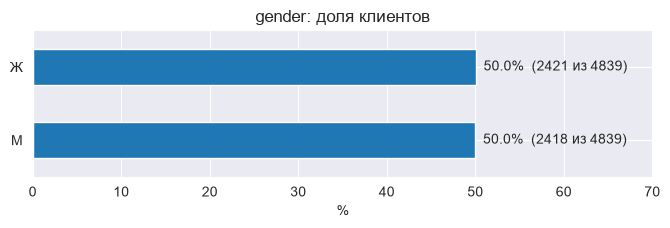

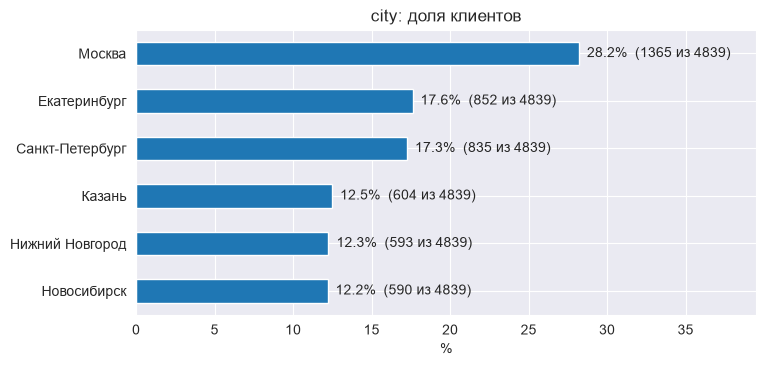

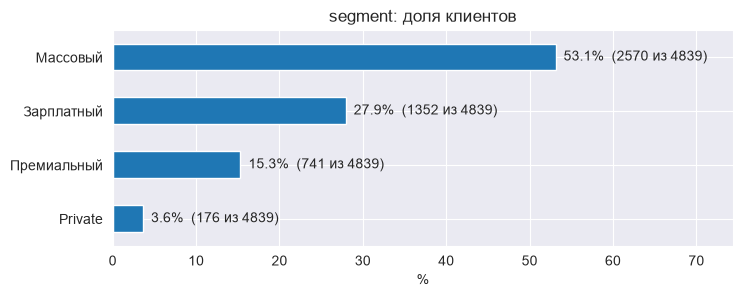

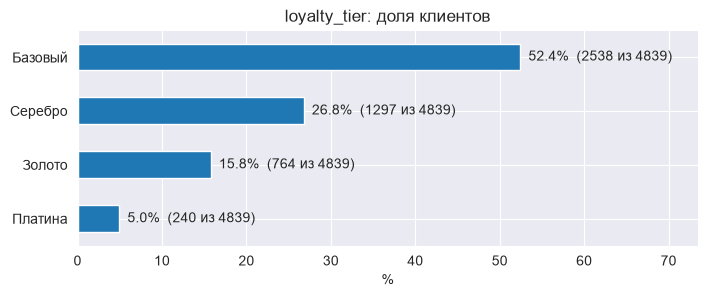

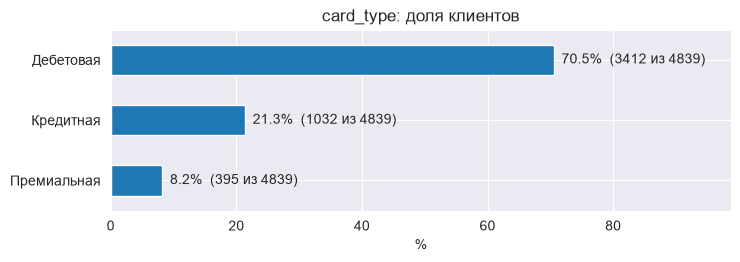

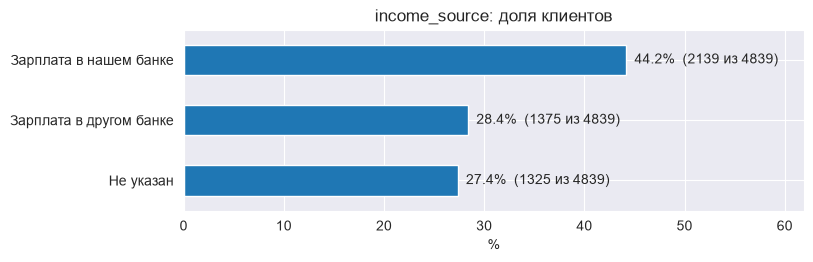

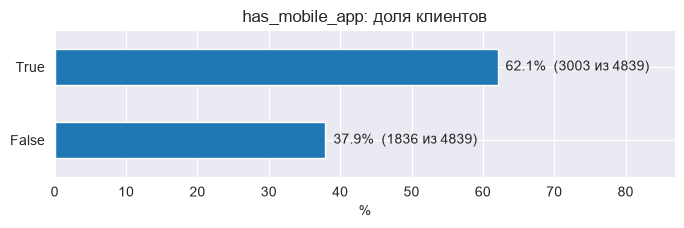

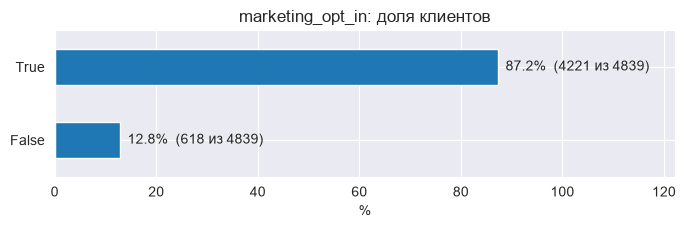

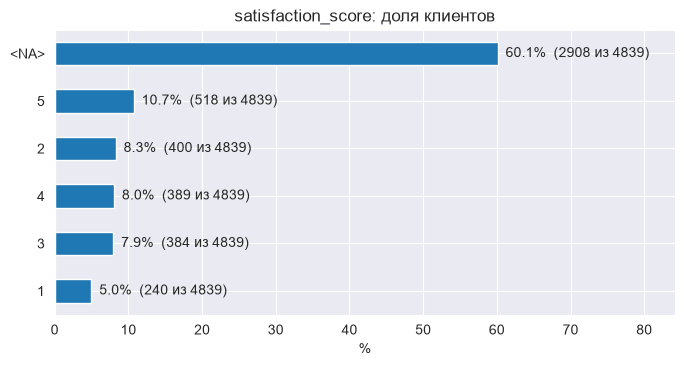

In [99]:
# Категориальные признаки клиентов
for col in ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'income_source',
            'has_mobile_app', 'marketing_opt_in', 'satisfaction_score']:
    plot_freq(clients, col, 'клиентов')

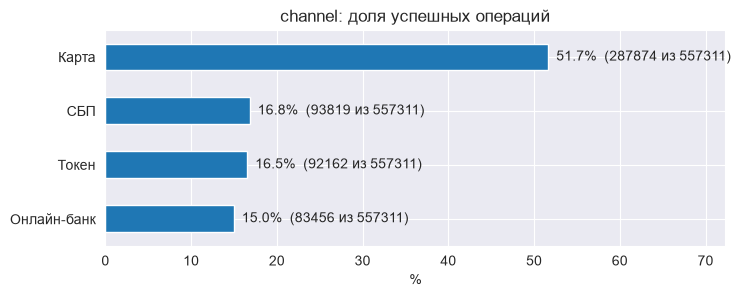

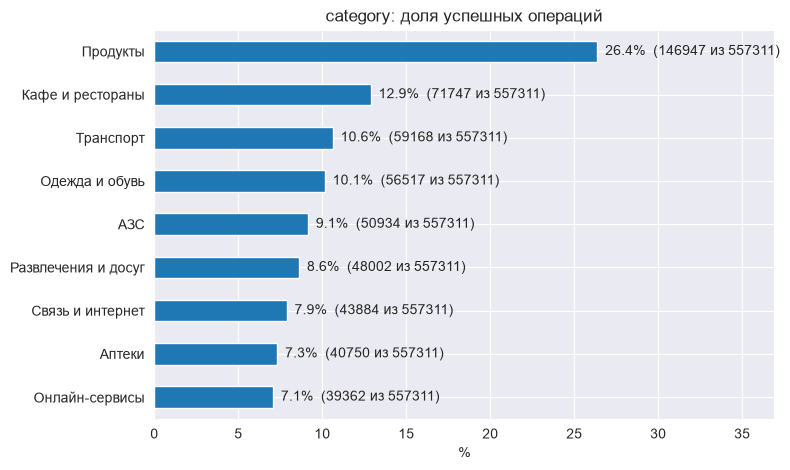

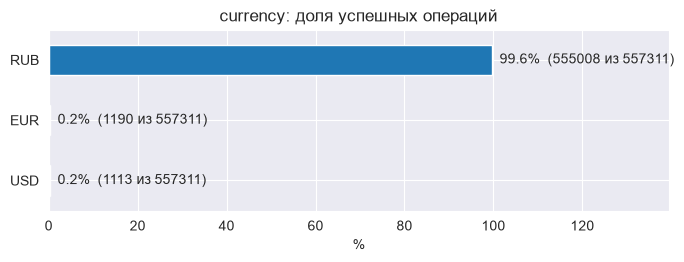

In [100]:
# Категориальные признаки успешных операций
for col in ['channel', 'category', 'currency']:
    plot_freq(ok_txn, col, 'успешных операций')

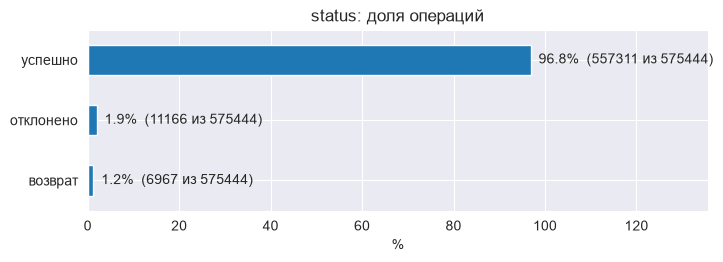

In [101]:
# Статусы — по всем операциям
plot_freq(transactions, 'status', 'операций')

### 5.3. Динамика по месяцам

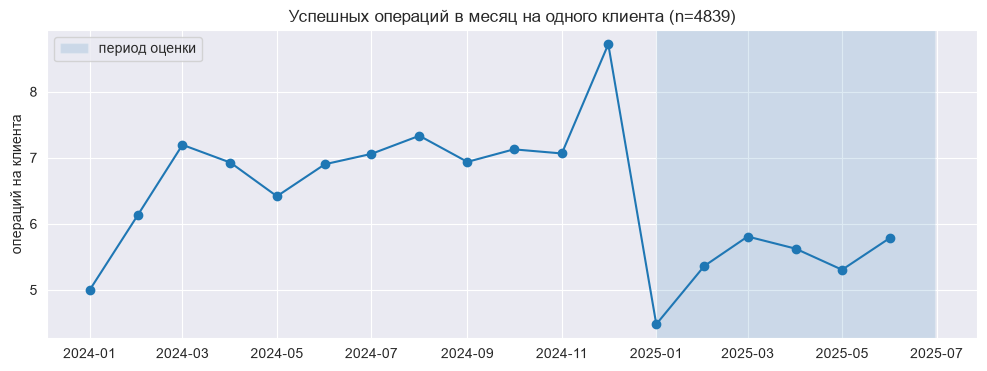

In [102]:
# Успешных операций в месяц на одного клиента
month = ok_txn['txn_datetime'].dt.to_period('M')
per_client = month.value_counts().sort_index() / len(clients)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(per_client.index.to_timestamp(), per_client.values, marker='o')
ax.axvspan(pd.Timestamp('2025-01-01'), pd.Timestamp('2025-06-30'), alpha=0.15, label='период оценки')
ax.set_title(f'Успешных операций в месяц на одного клиента (n={len(clients)})')
ax.set_ylabel('операций на клиента')
ax.legend()
plt.show()

In [103]:
# Средние по полугодиям
half = month.apply(lambda m: f'{m.year} {"I" if m.month <= 6 else "II"} полугодие')
by_half = ok_txn.groupby(half).size() / len(clients) / 6
print('Успешных операций в месяц на клиента, в среднем по полугодиям:')
print(by_half.round(2).to_string())

Успешных операций в месяц на клиента, в среднем по полугодиям:
txn_datetime
2024 I полугодие     6.43
2024 II полугодие    7.37
2025 I полугодие     5.39


In [104]:
print(f'I полугодие 2025 к I полугодию 2024: {by_half.iloc[2] / by_half.iloc[0] - 1:.1%}')

I полугодие 2025 к I полугодию 2024: -16.1%


**Динамика по месяцам.** В 2024 году клиенты в первом полугодии делали в среднем 6.43 успешной операции в месяц, во втором 7.37. По одному году нельзя уверенно говорить о сезонности, однако график первого полугодия 2025 очень похож по форме на график первого полугодия 2024, только ниже по уровню. К тому же логично, что, например, в декабре покупают больше. Поэтому будем считать, что сезонность есть.

В первом полугодии 2025 года в среднем 5.39 операции в месяц, это примерно на 16% меньше, чем в те же месяцы 2024 года. Значит, падение активности реальное, а не только сезонное. При сравнении января–июня 2025 с целым 2024 годом нужно учитывать, что первое полугодие и так ниже среднего за год, иначе падение окажется завышенным.

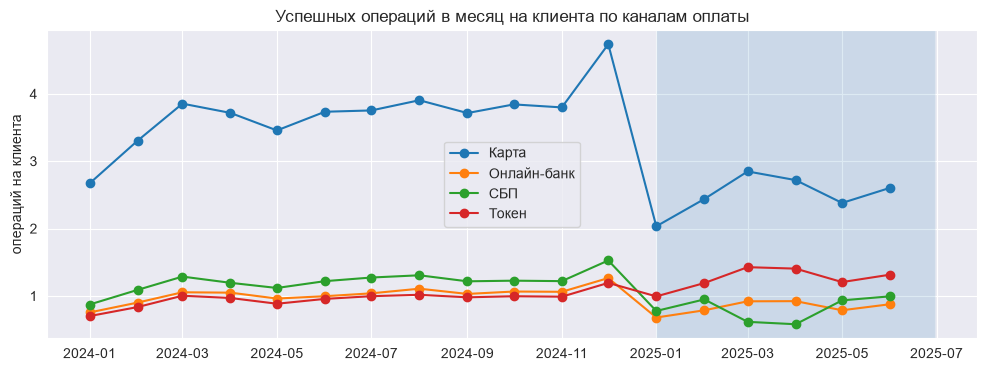

In [105]:
# Успешные операции по каналам оплаты, по месяцам
by_channel = ok_txn.groupby([month, 'channel'], observed=True).size().unstack() / len(clients)

fig, ax = plt.subplots(figsize=(12, 4))
for ch in by_channel.columns:
    ax.plot(by_channel.index.to_timestamp(), by_channel[ch], marker='o', label=ch)
ax.axvspan(pd.Timestamp('2025-01-01'), pd.Timestamp('2025-06-30'), alpha=0.15)
ax.set_title('Успешных операций в месяц на клиента по каналам оплаты')
ax.set_ylabel('операций на клиента')
ax.legend()
plt.show()

**Динамика по каналам.** Основной канал — оплата пластиковой картой: в 2024 году около 3.5–3.9 успешной операции в месяц на клиента. В январе 2025 года оплата картой резко падает примерно до 2 операций и до конца периода держится на уровне 2.5–2.9, то есть заметно ниже 2024 года. Падение не постепенное, а скачком на границе года. Оплата токеном в 2025 году, наоборот, выше, чем в 2024: часть клиентов перешла с пластика на токен. СБП и онлайн-банк в 2025 году немного ниже, чем в 2024. Получается, что общее падение активности в основном связано с отказом от пластиковой карты, но часть этих операций не пропала, а ушла в токен. Поэтому в группах нужно отличать тех, кто перестал платить картой и перешёл на другой способ, от тех, кто просто перестал платить.

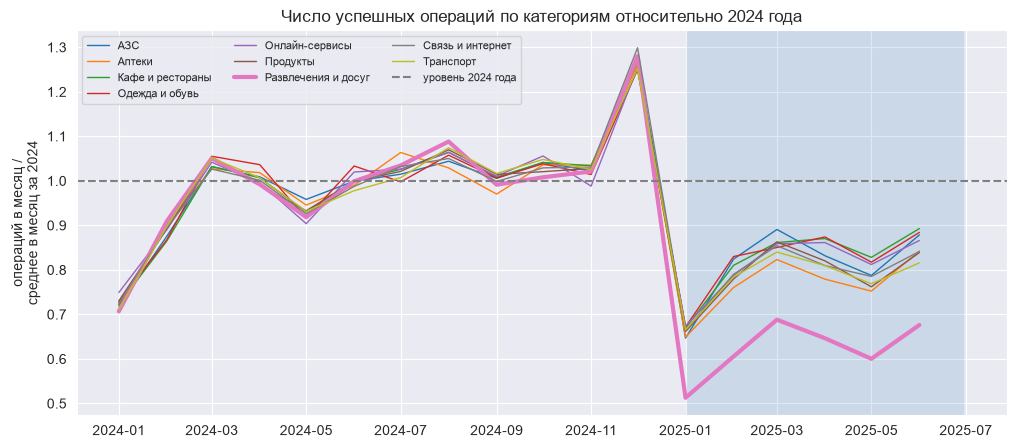

In [106]:
# Динамика категорий трат относительно 2024 года
by_cat = ok_txn.groupby([month, 'category'], observed=True).size().unstack()
by_cat_index = by_cat / by_cat.loc['2024-01':'2024-12'].mean()

fig, ax = plt.subplots(figsize=(12, 5))
for cat in by_cat_index.columns:
    lw = 3 if cat == 'Развлечения и досуг' else 1
    ax.plot(by_cat_index.index.to_timestamp(), by_cat_index[cat], label=cat, linewidth=lw)
ax.axhline(1, color='gray', linestyle='--', label='уровень 2024 года')
ax.axvspan(pd.Timestamp('2025-01-01'), pd.Timestamp('2025-06-30'), alpha=0.15)
ax.set_title('Число успешных операций по категориям относительно 2024 года')
ax.set_ylabel('операций в месяц /\nсреднее в месяц за 2024')
ax.legend(fontsize=8, ncol=3)
plt.show()

**Динамика по категориям.** Для каждой категории число операций в месяц поделено на её среднее в месяц за 2024 год, поэтому 1 означает уровень 2024 года. В 2024 году все категории ведут себя одинаково: одна и та же сезонность и пик в декабре. В 2025 году все категории снижаются примерно до 0.8–0.9 от уровня 2024 года, а «Развлечения и досуг» до 0.5–0.7. Это единственная категория, которая падает заметно сильнее остальных, поэтому её стоит проверить отдельно: возможно, часть клиентов перестала тратить именно на развлечения.

### 5.4. Разрезы и связи между признаками

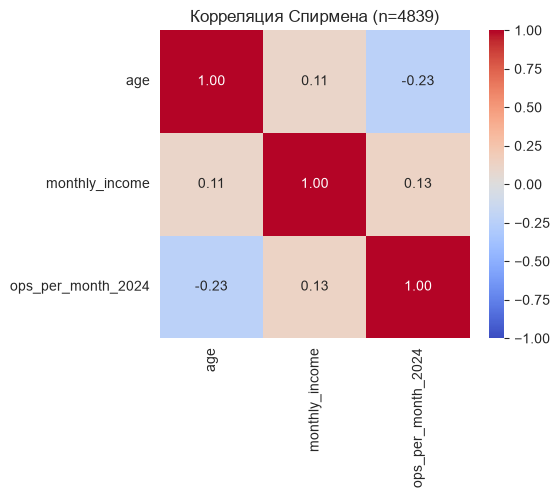

In [107]:
# Корреляция Спирмена между числовыми признаками (через ранги)
num_cols = ['age', 'monthly_income', 'ops_per_month_2024']
spearman = clients[num_cols].rank().corr()

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(spearman, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm', ax=ax)
ax.set_title(f'Корреляция Спирмена (n={len(clients)})')
plt.show()

In [108]:
# Горизонтальные столбики: доля в каждой группе с подписью «доля (k из n)»
def plot_share(mask, by, title, xlabel):
    stat = mask.groupby(by, observed=True).agg(['mean', 'sum', 'size'])
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(stat) + 1))
    (stat['mean'] * 100).plot.barh(ax=ax)
    for i, (share, k, n) in enumerate(stat.itertuples(index=False)):
        ax.text(share * 100, i, f'  {share:.1%} ({k} из {n})', va='center')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('')
    ax.set_xlim(0, stat['mean'].max() * 140)
    ax.invert_yaxis()
    plt.show()

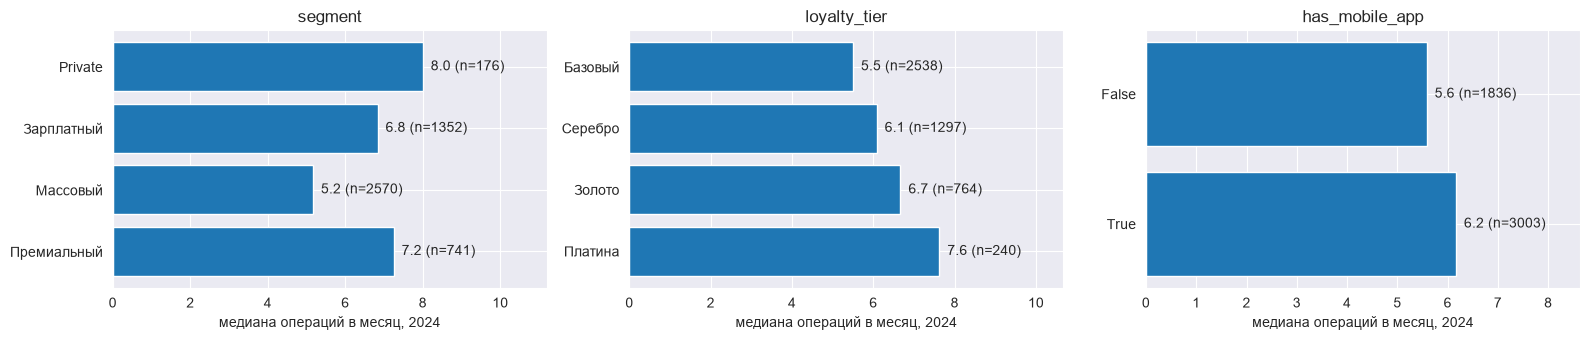

In [109]:
# Медиана успешных операций в месяц в 2024 году по группам
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, col in zip(axes, ['segment', 'loyalty_tier', 'has_mobile_app']):
    stat = clients.groupby(col, observed=True)['ops_per_month_2024'].agg(['median', 'size'])
    ax.barh(stat.index.astype(str), stat['median'])
    for i, (med, n) in enumerate(stat.itertuples(index=False)):
        ax.text(med, i, f'  {med:.1f} (n={n})', va='center')
    ax.set_title(col)
    ax.set_xlabel('медиана операций в месяц, 2024')
    ax.set_xlim(0, stat['median'].max() * 1.4)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

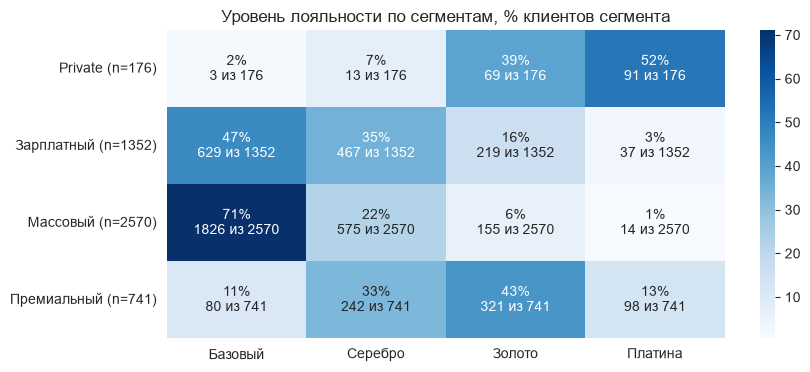

In [110]:
# Уровень лояльности внутри каждого сегмента: % и число клиентов
counts = pd.crosstab(clients['segment'], clients['loyalty_tier'])
seg_size = counts.sum(axis=1)
share = counts.div(seg_size, axis=0) * 100
labels = share.round(0).astype(int).astype(str) + '%\n' + counts.astype(str) + ' из ' + \
         pd.DataFrame({c: seg_size for c in counts.columns}).astype(str)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(share, annot=labels, fmt='', cmap='Blues', ax=ax)
ax.set_yticklabels([f'{s} (n={n})' for s, n in seg_size.items()], rotation=0)
ax.set_title('Уровень лояльности по сегментам, % клиентов сегмента')
ax.set_xlabel('')
ax.set_ylabel('')
plt.show()

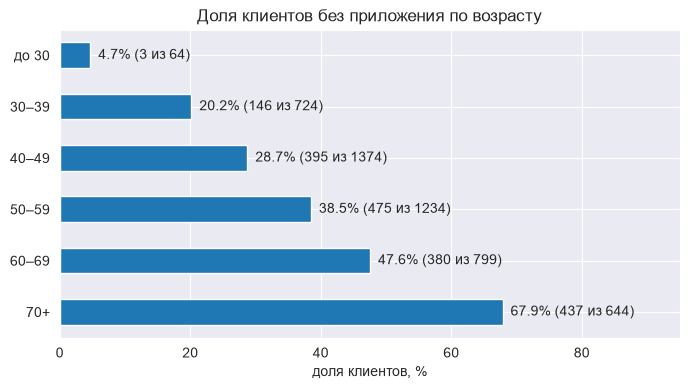

In [111]:
# Доля клиентов без приложения по возрастным группам
age_group = pd.cut(clients['age'], bins=[0, 30, 40, 50, 60, 70, 100],
                   labels=['до 30', '30–39', '40–49', '50–59', '60–69', '70+'], right=False)
plot_share(~clients['has_mobile_app'], age_group,
           'Доля клиентов без приложения по возрасту', 'доля клиентов, %')

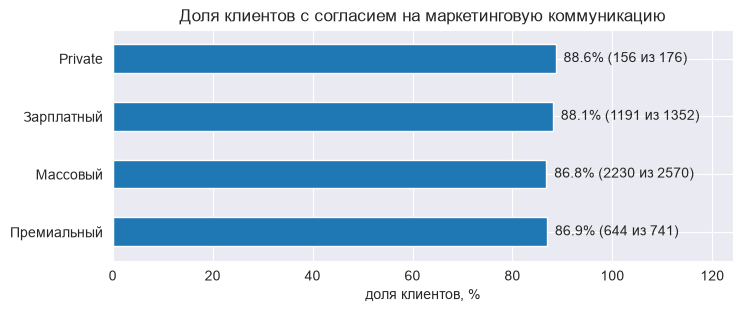

In [112]:
# Доля клиентов с согласием на коммуникацию по сегментам
plot_share(clients['marketing_opt_in'], clients['segment'],
           'Доля клиентов с согласием на маркетинговую коммуникацию', 'доля клиентов, %')

**Связи и разрезы.** Числовые признаки связаны слабо: корреляция Спирмена между возрастом и числом успешных операций в месяц в 2024 году −0.23 (старшие клиенты платят немного реже), между доходом и числом операций 0.13, между возрастом и доходом 0.11. По одному числовому признаку частоту операций клиента не предсказать.

Число операций заметно различается по сегментам: медиана успешных операций в месяц в 2024 году у Private 8.0, у премиальных 7.2, у зарплатных 6.8, у массовых 5.2. Так же оно растёт с уровнем лояльности: от 5.5 у Базового до 7.6 у Платины. Поэтому сравнивать 2025 год с 2024 стоит внутри сегментов.

Уровень лояльности сильно связан с сегментом: у массовых клиентов 71% Базовый, у Private 91% Золото и Платина. Без приложения чаще старшие клиенты: до 30 лет 5%, в 70 лет и старше 68%. Согласие на коммуникацию дали 87% клиентов, по сегментам доля почти одинаковая, от 87% до 89%.

## 6. Метрика активности

**Что считаем активностью.** Активность клиента — число его успешных операций в месяц по всем каналам: картой, токеном, через СБП и онлайн-банк. Считаем именно число операций, а не сумму: сумма зависит от размера отдельных покупок и валюты, а число операций прямо показывает, как часто клиент пользуется банком. Все каналы берём вместе, потому что переход с пластика на оплату телефоном — это смена способа, а не снижение активности. Отклонённые операции и возвраты не учитываем, это не совершённые покупки.

**Множество.** Метрику считаем для 4839 клиентов, прошедших фильтры из 3.5: они есть в справочнике, у них есть успешные операции, текущая карта открыта до 2024 года (полный базовый год) и в 2024 году у них в среднем не меньше одной операции в месяц.

**Окна.** Базовый период — весь 2024 год (12 месяцев), период оценки — январь–июнь 2025 года (6 месяцев). Периоды разной длины, поэтому в обоих считаем среднее число операций в месяц: `ops_per_month_2024` и `ops_per_month_2025`.

**Поправка на сезон.** В 5.3 видно, что первое полугодие спокойнее второго. Если сравнивать январь–июнь 2025 с целым 2024 годом напрямую, часть падения окажется сезонной. Поэтому ожидаемый уровень на январь–июнь — это уровень клиента в 2024 году, умноженный на сезонный коэффициент: среднее число операций в месяц за январь–июнь 2024, делённое на среднее за весь 2024 год. Коэффициент считается по всем клиентам вместе, так он устойчивее, чем по каждому клиенту отдельно.

**Что оцениваем.** Нам нужно найти клиентов, которые снизили активность, поэтому оцениваем не саму активность, а её изменение: насколько реже клиент совершал операции в январе–июне 2025 года по сравнению с тем, что ожидалось для этих месяцев по его уровню в 2024 году. Изменение считается в процентах (формула ниже), и по нему мы будем искать клиентов с падением.

**Формула.** Изменение активности = `ops_per_month_2025 / (ops_per_month_2024 × сезонный коэффициент) − 1`, в процентах. 0% — клиент активен как обычно для этих месяцев, −50% — вдвое реже ожидаемого, −100% — в 2025 году ни одной операции.

**Чего метрика не видит.**
- Снижения трат при том же числе операций: если клиент покупает так же часто, но на меньшие суммы, метрика этого не заметит.
- Перераспределения внутри активности: если клиент сменил способ оплаты (с карты на токен или СБП) или перестал тратить в одной категории, но чаще покупает в другой, общее число операций почти не меняется, и метрика падения не покажет.
- Падения внутри периода оценки: клиент, который перестал платить только в июне, усредняется с первыми пятью месяцами и выглядит почти нормальным.

**Допущение.** Сезонный коэффициент оценён по одному году, другого года в данных нет. Если в 2025 году сезонность отличается от 2024, поправка будет неточной, и падение окажется немного завышенным или заниженным для всех клиентов одинаково.

In [113]:
# Успешных операций в месяц в январе–июне 2025
ops_2025 = ok_txn[ok_txn['txn_datetime'] >= '2025-01-01'].groupby('client_id').size() / 6
clients['ops_per_month_2025'] = clients['client_id'].map(ops_2025).fillna(0)
add_log('ops_per_month_2025', 'нужно среднее число успешных операций клиента в месяц за январь–июнь 2025',
        'clients, все строки', len(clients), 'столбца нет', 'добавлено',
        'успешных операций за январь–июнь 2025 / 6, без операций — 0',
        'для подсчёта изменения активности и для описания групп')

print(f'Клиентов без единой операции в 2025: {(clients["ops_per_month_2025"] == 0).sum()} из {len(clients)}')
print("У клиента, который в 2025 году не сделал ни одной операции, активность 0")

Клиентов без единой операции в 2025: 3 из 4839
У клиента, который в 2025 году не сделал ни одной операции, активность 0


In [114]:
# Сезонный коэффициент: насколько январь–июнь спокойнее года в целом (по 2024 году)
per_month = ok_txn.groupby(ok_txn['txn_datetime'].dt.to_period('M')).size()
SEASON_H1 = per_month['2024-01':'2024-06'].mean() / per_month['2024-01':'2024-12'].mean()
print(f'Сезонный коэффициент января–июня: {SEASON_H1:.3f}')

Сезонный коэффициент января–июня: 0.931


In [115]:
# Изменение активности с поправкой на сезон, %
clients['activity_change'] = (clients['ops_per_month_2025'] / (clients['ops_per_month_2024'] * SEASON_H1) - 1) * 100
add_log('activity_change', 'нужна метрика изменения активности', 'clients, все строки', len(clients),
        'столбца нет', 'добавлено', 'операций в месяц 2025 / (операций в месяц 2024 × сезонный коэффициент) − 1, %',
        'сравниваем январь–июнь 2025 с ожидаемым уровнем для этих месяцев')

print('Изменение активности с поправкой на сезон, %:')
print(clients['activity_change'].describe().round(1).to_string())

Изменение активности с поправкой на сезон, %:
count    4839.0
mean      -17.6
std        39.7
min      -100.0
25%       -51.9
50%       -16.2
75%         7.4
max       189.0


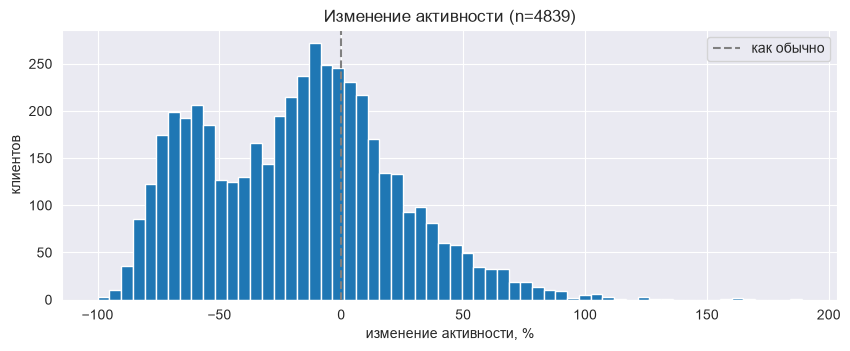

In [116]:
# Распределение изменения активности
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(clients['activity_change'], bins=60)
ax.axvline(0, color='gray', linestyle='--', label='как обычно')
ax.set_title(f'Изменение активности (n={len(clients)})')
ax.set_xlabel('изменение активности, %')
ax.set_ylabel('клиентов')
ax.legend()
plt.show()

In [117]:
# Сколько клиентов в каждом промежутке изменения активности
bins = [-100.1, -80, -60, -40, -20, 0, 20, np.inf]
labels = ['от −100% до −80%', 'от −80% до −60%', 'от −60% до −40%', 'от −40% до −20%',
          'от −20% до 0%', 'от 0% до +20%', 'больше +20%']
ranges = pd.cut(clients['activity_change'], bins=bins, labels=labels)

counts = ranges.value_counts().reindex(labels)
print('Клиенты по изменению активности:')
for label, k in counts.items():
    print(f'  {label}: {k} из {len(clients)} ({k / len(clients):.1%})')

Клиенты по изменению активности:
  от −100% до −80%: 150 из 4839 (3.1%)
  от −80% до −60%: 750 из 4839 (15.5%)
  от −60% до −40%: 621 из 4839 (12.8%)
  от −40% до −20%: 700 из 4839 (14.5%)
  от −20% до 0%: 1034 из 4839 (21.4%)
  от 0% до +20%: 810 из 4839 (16.7%)
  больше +20%: 774 из 4839 (16.0%)


Медиана изменения активности −16.2%, у половины клиентов изменение от −51.9% до +7.4%. Распределение двугорбое: у одной части клиентов активность почти не изменилась, у другой упала примерно на 60%.  Только 3 клиента в 2025 году не сделали ни одной операции, то есть почти все упавшие продолжают пользоваться банком, но гораздо реже.

## 7. Поиск и описание групп

**Почему смотрим на клиентов с падением от 40%.** Распределение изменения активности двугорбое, и горбы, скорее всего, соответствуют двум разным типам клиентов. Правый горб около 0% — клиенты, у которых ничего особенного не произошло: их активность колеблется вокруг обычной, кто-то в этом полугодии покупал чуть чаще, кто-то чуть реже. Небольшое снижение у них может быть случайным. Левый горб около −60% — клиенты, которые стали платить в разы реже. Если бы падение было просто случайным разбросом, левый хвост плавно спадал бы, а не собирался в отдельный горб. Значит, у большой группы клиентов что-то произошло, и, вероятно, у многих одно и то же. Задача — найти, у кого снизилась активность и почему, поэтому причину ищем там, где падение настоящее. К тому же кампания ограничена 2000 клиентами, и её лучше направить на тех, у кого активность действительно упала. Граница −40% проходит по провалу между горбами.

In [118]:
DROP_THRESHOLD = -40
strong = clients['activity_change'] <= DROP_THRESHOLD
print(f'Клиентов с падением на 40% и больше: {strong.sum()} из {len(clients)}')

Клиентов с падением на 40% и больше: 1521 из 4839


In [119]:
# Все признаки клиента для разрезов: категориальные как есть, числовые — интервалами
report = pd.Timestamp('2025-06-30')
feat = pd.DataFrame(index=clients.index)

feat['Сегмент'] = clients['segment']
feat['Уровень лояльности'] = clients['loyalty_tier']
feat['Тип карты'] = clients['card_type']
feat['Город'] = clients['city']
feat['Пол'] = clients['gender']
feat['Источник дохода'] = clients['income_source']
feat['Мобильное приложение'] = clients['has_mobile_app'].map({True: 'есть', False: 'нет'})
feat['Согласие на коммуникацию'] = clients['marketing_opt_in'].map({True: 'есть', False: 'нет'})
feat['Оценка обслуживания'] = pd.Categorical(
    clients['satisfaction_score'].astype('string').fillna('нет оценки'),
    categories=['1', '2', '3', '4', '5', 'нет оценки'], ordered=True)

months_login = (pd.Period('2025-06', freq='M') - clients['app_last_login']).apply(lambda x: x.n if pd.notna(x) else np.nan)
feat['Месяцев с последнего входа в приложение'] = pd.cut(
    months_login, bins=[-1, 0, 2, 5, 11, 18],
    labels=['в июне 2025', '1–2', '3–5', '6–11', '12–17']).cat.add_categories('нет приложения').fillna('нет приложения')

feat['Возраст'] = pd.cut(clients['age'], bins=[0, 30, 40, 50, 60, 70, 120], right=False,
                         labels=['до 30', '30–39', '40–49', '50–59', '60–69', '70+'])
feat['Стаж в банке, лет'] = pd.cut((report - clients['registration_date']).dt.days / 365.25,
                                   bins=[0, 3, 5, 8, 11, 16], labels=['до 3', '3–5', '5–8', '8–11', '11+'])

feat['Доход, тыс. руб.'] = pd.cut(clients['monthly_income'] / 1000, bins=[0, 50, 75, 100, 150, 1000],
                                  labels=['до 50', '50–75', '75–100', '100–150', '150+'])
feat['Доход, тыс. руб.'] = feat['Доход, тыс. руб.'].cat.add_categories('не указан').fillna('не указан')
feat['Операций в месяц в 2024 году'] = pd.cut(clients['ops_per_month_2024'], bins=[1, 3, 5, 8, 12, 60], right=False,
                                              labels=['1–3', '3–5', '5–8', '8–12', '12+'])

In [120]:
# Внутри выбранной части клиентов: доля с падением на 40% и больше по каждому признаку
def plot_within(subset, subset_name, skip_cols=()):
    strong_sub = strong[subset]
    overall = strong_sub.mean() * 100
    print(f'{subset_name}: {subset.sum()} клиентов, из них активность упала на {-DROP_THRESHOLD}% и больше '
          f'у {strong_sub.sum()} ({overall:.1f}%)')

    for col in feat.columns.drop(list(skip_cols)):
        stat = strong_sub.groupby(feat.loc[subset, col], observed=True).agg(['mean', 'sum', 'size'])
        stat['mean'] = stat['mean'] * 100
        if isinstance(feat[col].dtype, pd.CategoricalDtype):
            stat = stat.reindex([c for c in feat[col].cat.categories if c in stat.index])
        else:
            stat = stat.sort_values('mean')

        fig, ax = plt.subplots(figsize=(10, 0.6 * len(stat) + 1.5))
        stat['mean'].plot.barh(ax=ax, label='доля в этой категории')
        ax.axvline(overall, color='red', linestyle='--', label=f'в среднем ({subset_name.lower()}): {overall:.0f}%')
        for i, (share, k, n) in enumerate(zip(stat['mean'], stat['sum'], stat['size'])):
            ax.text(share, i, f'  {share:.0f}%  ({k} из {n})', va='center', fontsize=10)
        ax.set_title(f'{subset_name}. Признак «{col}»: у какой доли клиентов активность упала на {-DROP_THRESHOLD}% и больше')
        ax.set_xlabel(f'% клиентов категории с падением активности на {-DROP_THRESHOLD}% и больше')
        ax.set_ylabel('')
        ax.set_xlim(0, max(stat['mean'].max(), overall) * 1.45)
        ax.legend(loc='lower right')
        plt.show()

Все клиенты: 4839 клиентов, из них активность упала на 40% и больше у 1521 (31.4%)


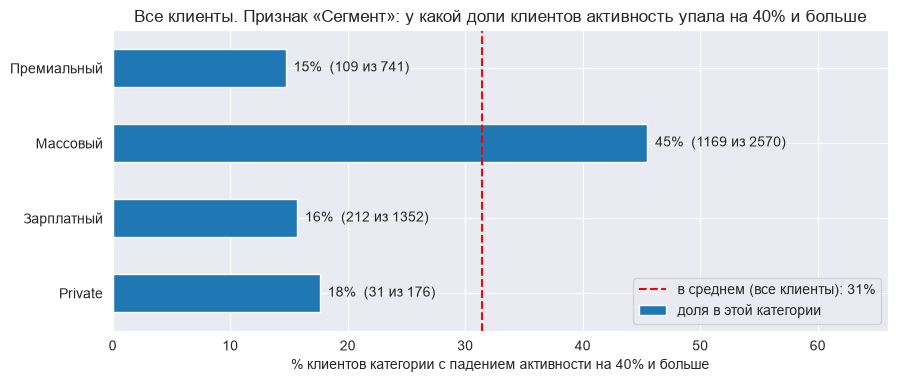

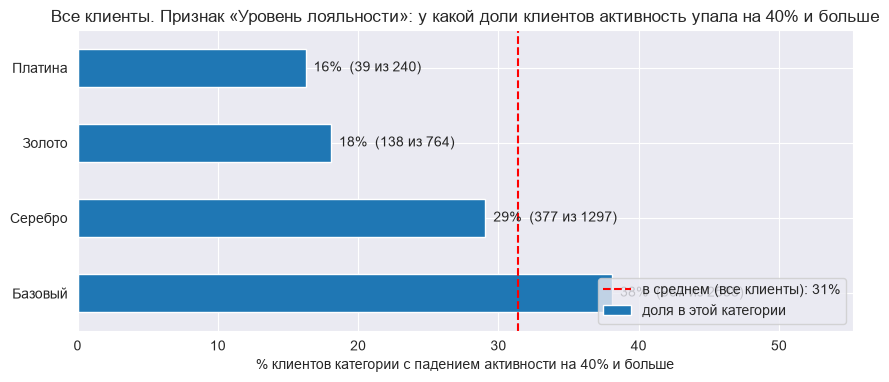

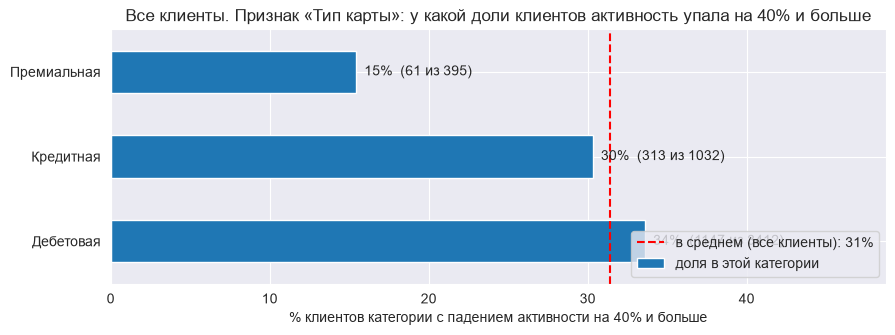

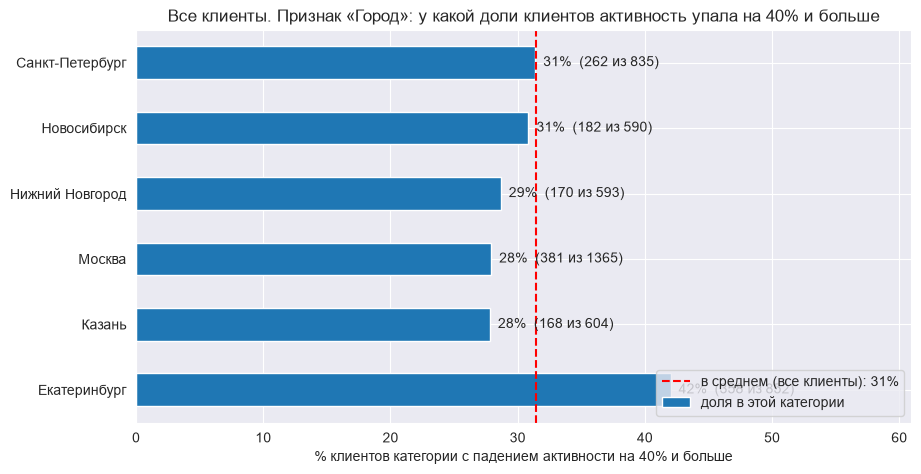

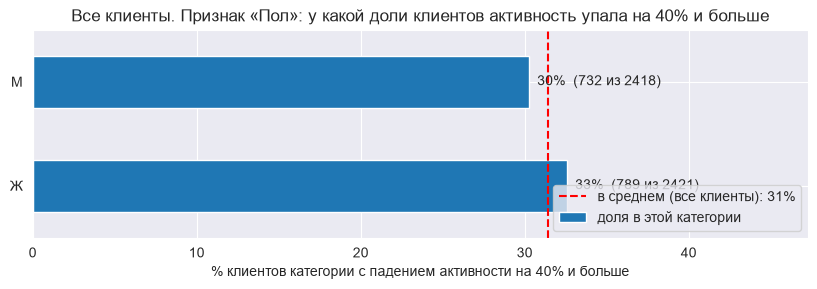

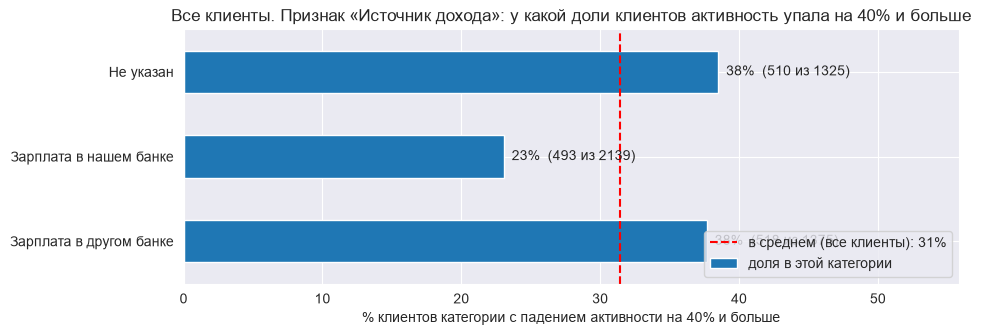

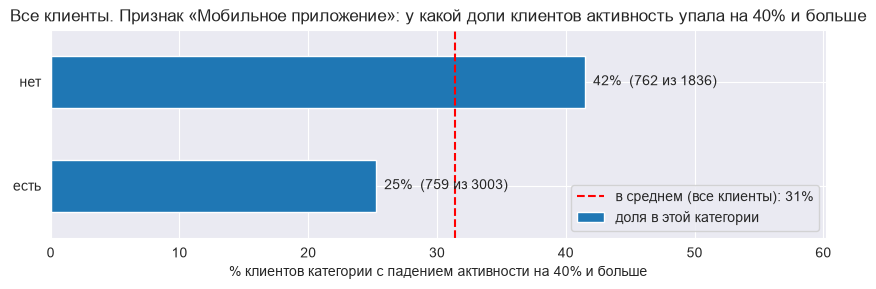

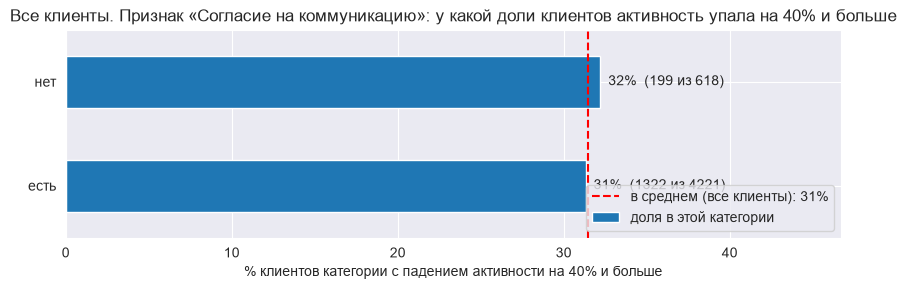

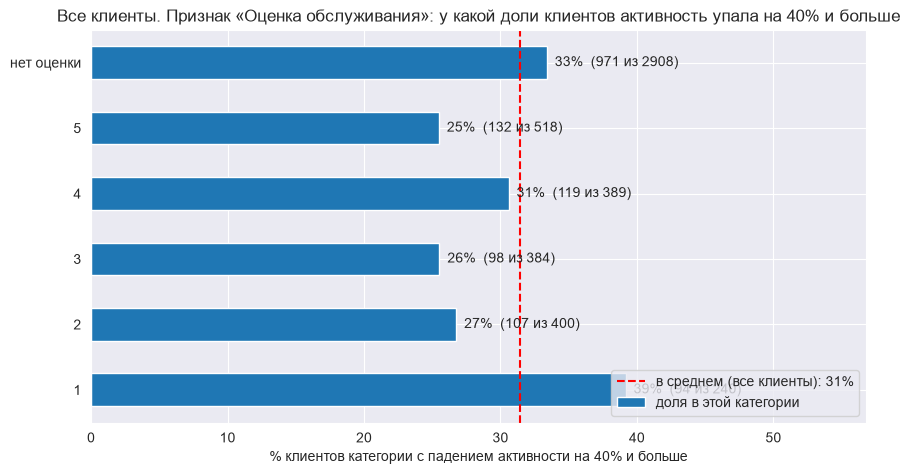

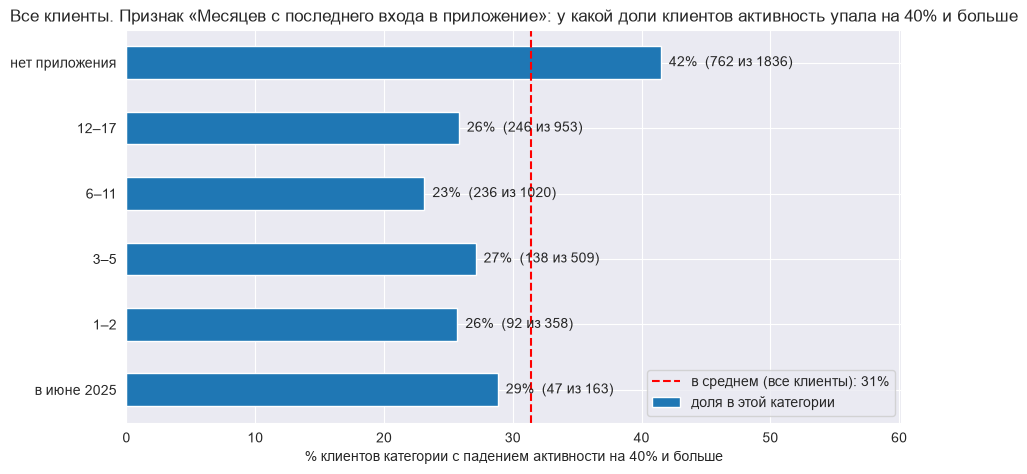

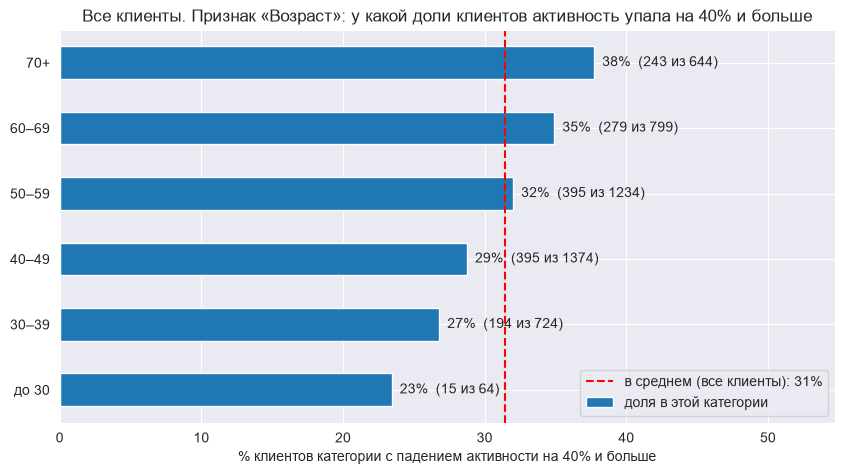

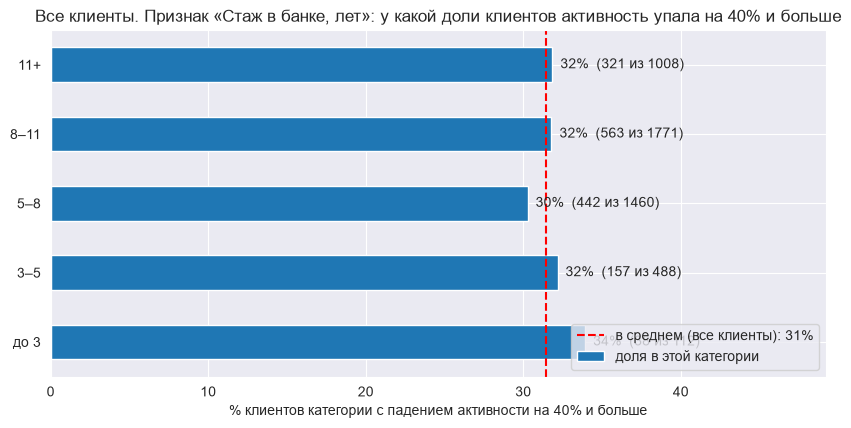

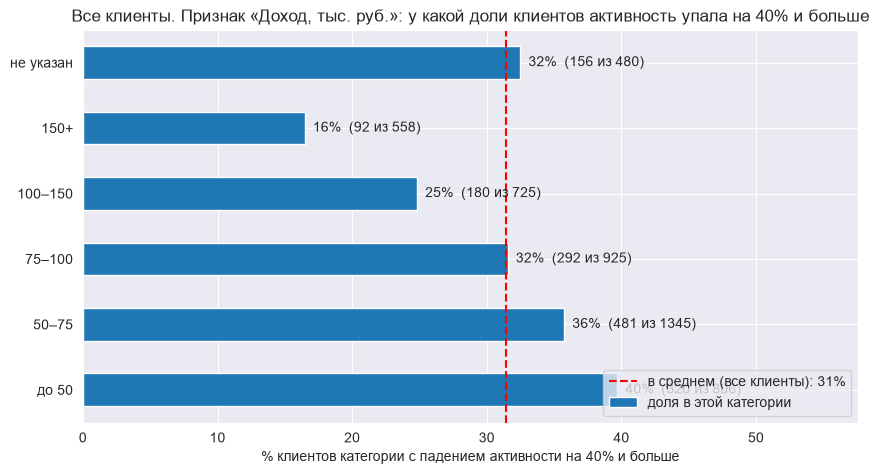

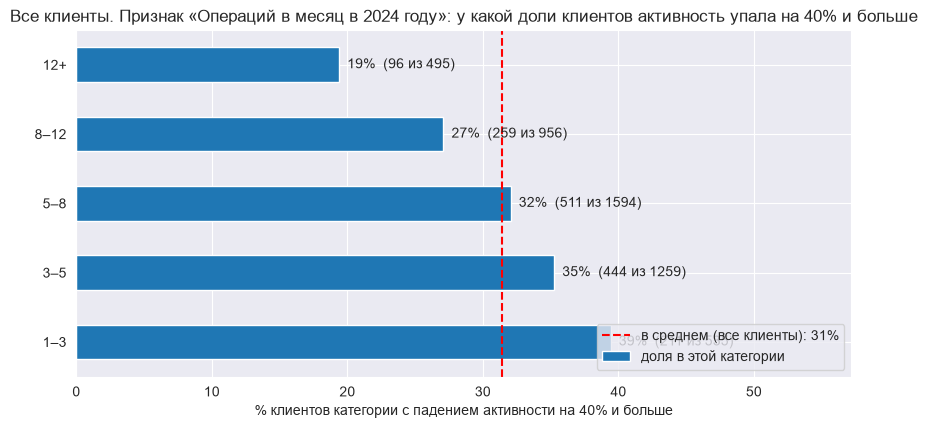

In [121]:
# Все клиенты: в каких группах доля сильного падения выше средней
plot_within(clients['client_id'].notna(), 'Все клиенты')

Массовые клиенты: 2570 клиентов, из них активность упала на 40% и больше у 1169 (45.5%)


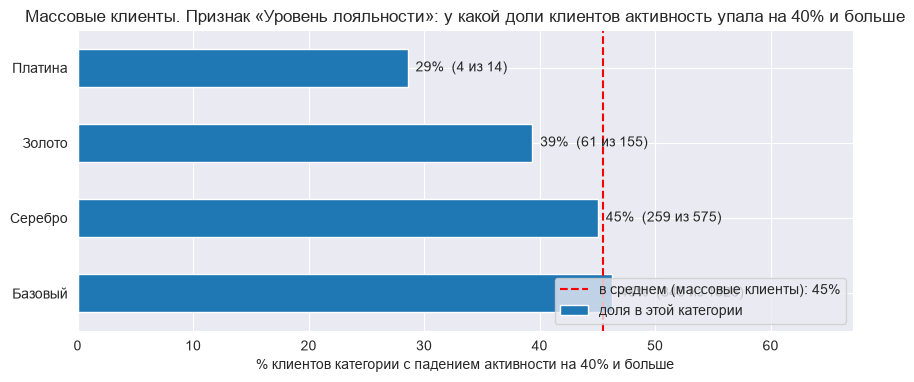

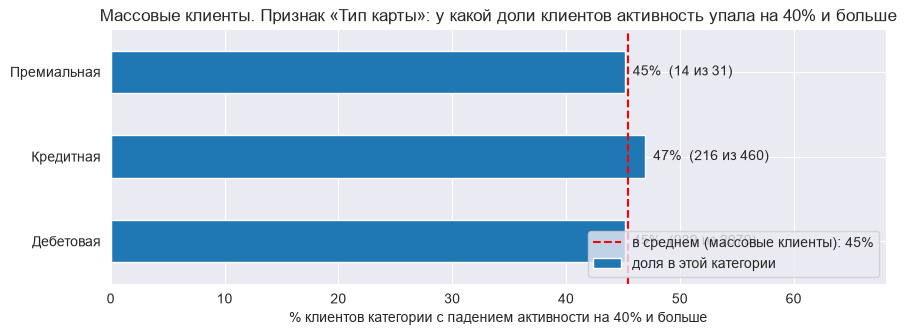

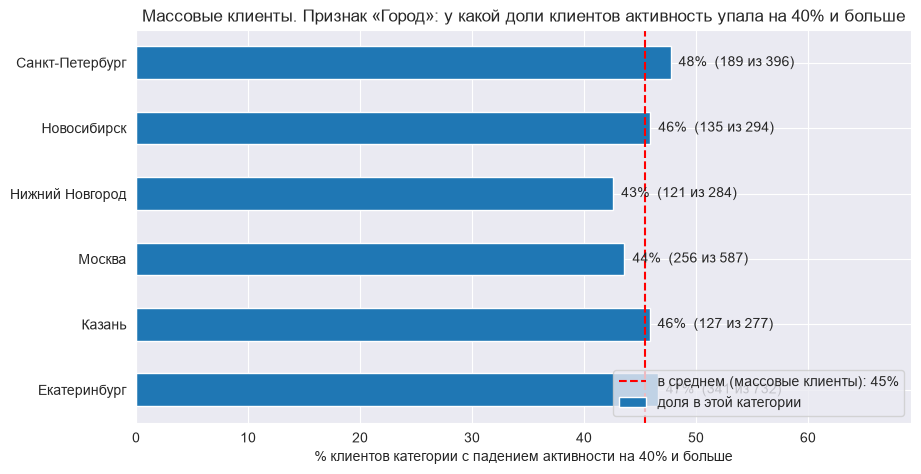

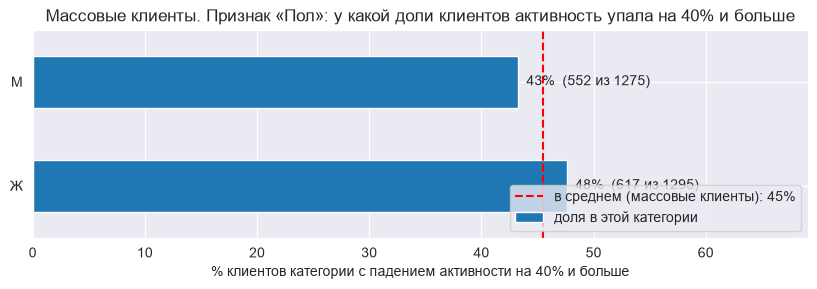

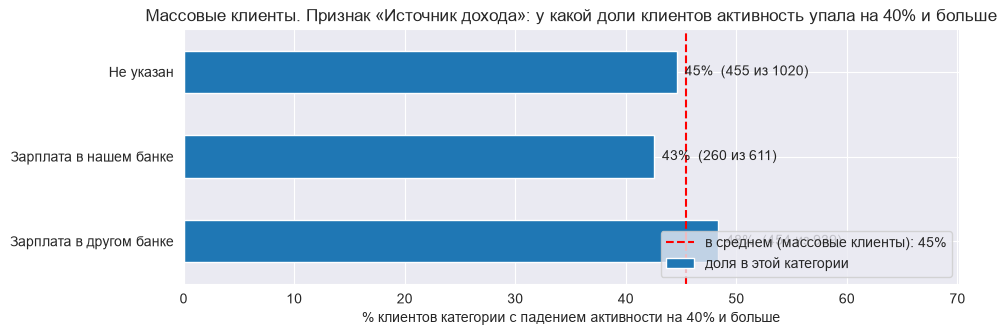

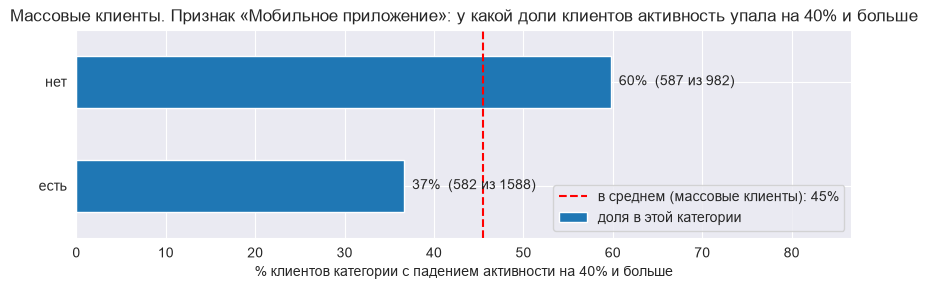

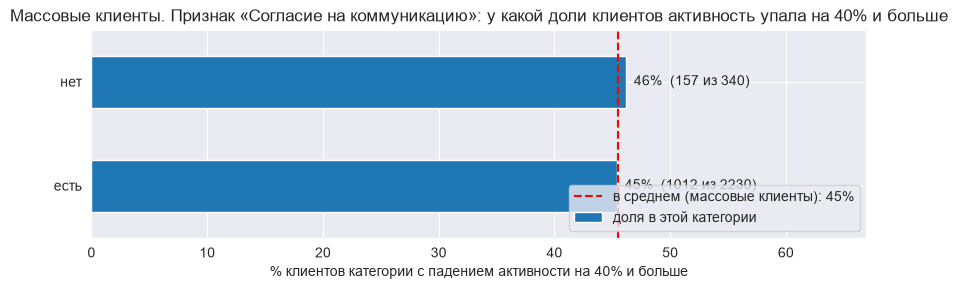

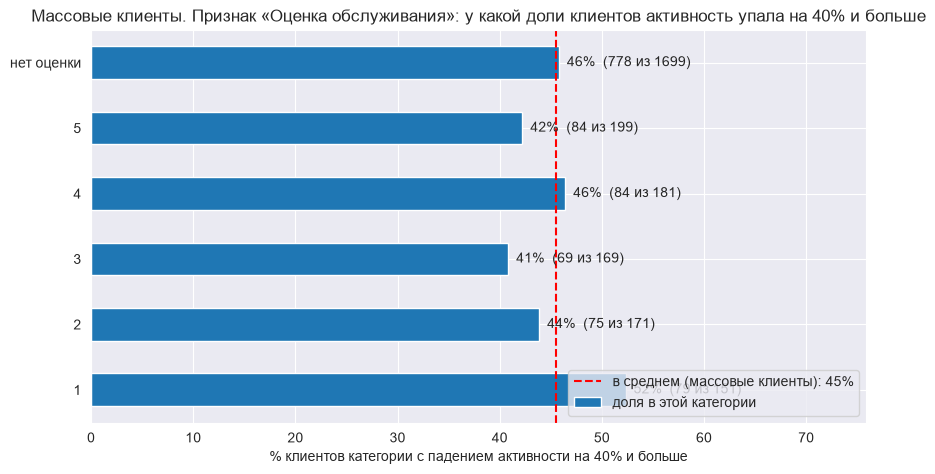

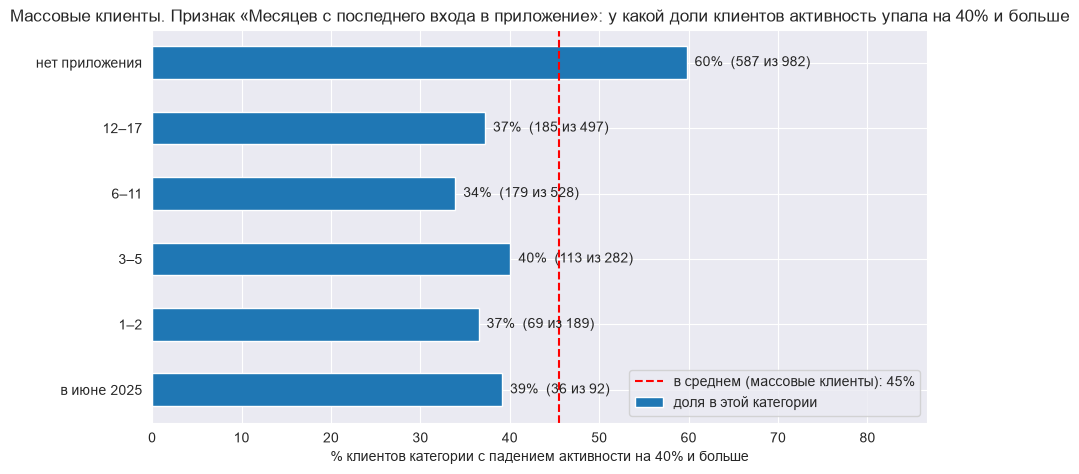

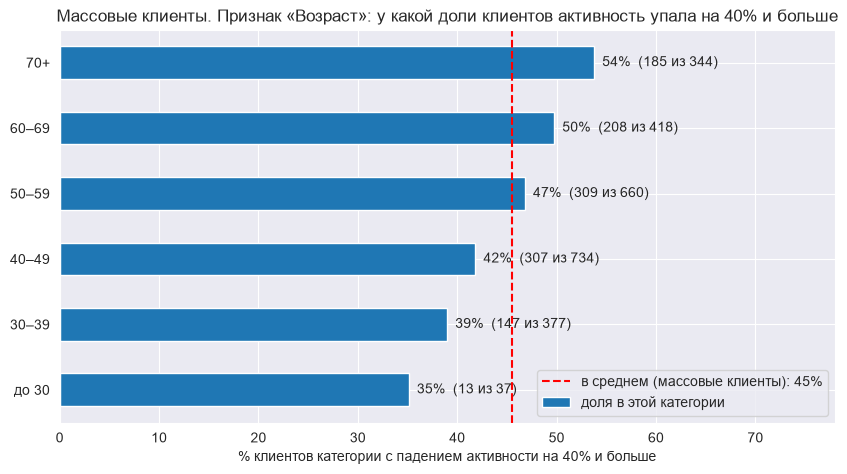

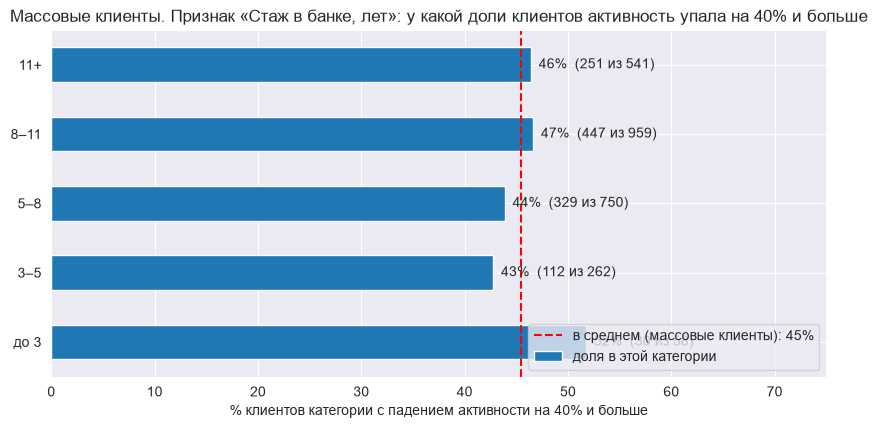

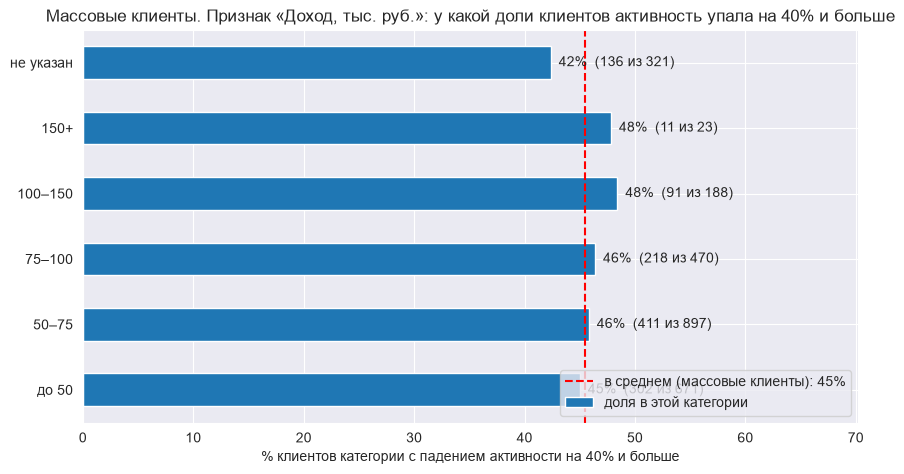

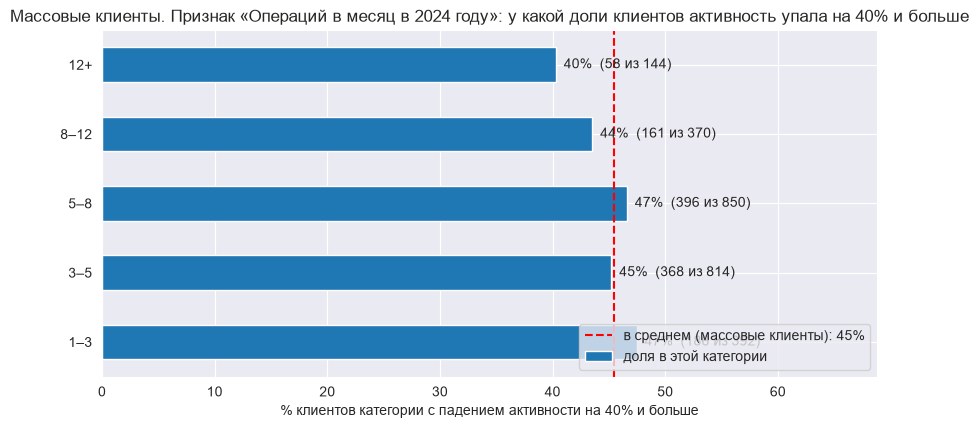

In [122]:
# Массовые клиенты: внутри сегмента, в каких группах доля сильного падения выше средней
mass = clients['segment'] == 'Массовый'
plot_within(mass, 'Массовые клиенты', skip_cols=['Сегмент'])

In [123]:
# Операции 2024 года и подсчёт операций клиента в месяц по любому условию
is_2024 = ok_txn['txn_datetime'] < '2025-01-01'

def per_month(mask, months):
    counts = ok_txn[mask].groupby('client_id').size() / months
    return clients['client_id'].map(counts).fillna(0)

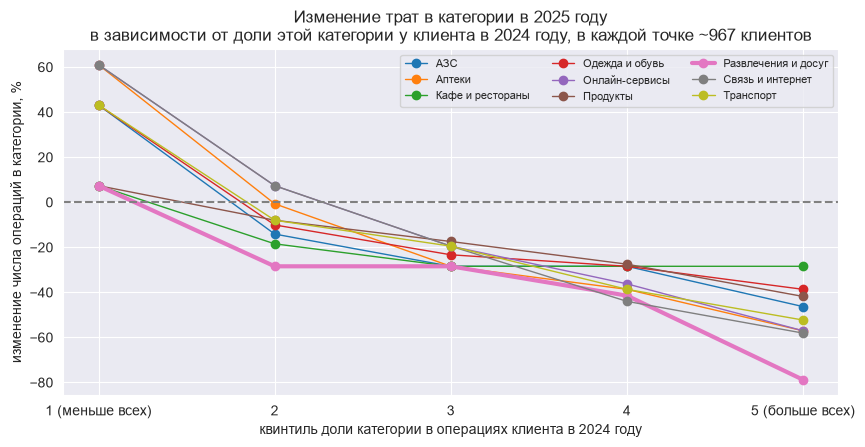

In [124]:
# Изменение трат в категории по квинтилям её доли в операциях клиента в 2024 году
quint_labels = ['1 (меньше всех)', '2', '3', '4', '5 (больше всех)']

fig, ax = plt.subplots(figsize=(10, 4.5))
for cat in ok_txn['category'].cat.categories:
    in_cat = ok_txn['category'] == cat
    cat_2024, cat_2025 = per_month(is_2024 & in_cat, 12), per_month(~is_2024 & in_cat, 6)
    share = cat_2024 / clients['ops_per_month_2024']
    change = cat_2025 / (cat_2024 * SEASON_H1).replace(0, np.nan)
    quint = pd.qcut(share.rank(method='first'), 5, labels=quint_labels)
    by_quint = (change.groupby(quint, observed=False).median() - 1) * 100
    lw = 3 if cat == 'Развлечения и досуг' else 1
    ax.plot(quint_labels, by_quint.values, marker='o', linewidth=lw, label=cat)
ax.axhline(0, color='gray', linestyle='--')
ax.set_title(f'Изменение трат в категории в 2025 году\n'
             f'в зависимости от доли этой категории у клиента в 2024 году, в каждой точке ~{len(clients) // 5} клиентов')
ax.set_xlabel('квинтиль доли категории в операциях клиента в 2024 году')
ax.set_ylabel('изменение числа операций в категории, %')
ax.legend(fontsize=8, ncol=3)
plt.show()

In [125]:
# Перестали тратить на развлечения: были заметной частью операций, упали минимум вдвое, остальное почти как обычно
is_ent = ok_txn['category'] == 'Развлечения и досуг'
ent_2024, ent_2025 = per_month(is_2024 & is_ent, 12), per_month(~is_2024 & is_ent, 6)
rest_2024, rest_2025 = per_month(is_2024 & ~is_ent, 12), per_month(~is_2024 & ~is_ent, 6)

ent_share = ent_2024 / clients['ops_per_month_2024']                  # доля развлечений в операциях 2024 года
ent_change = ent_2025 / (ent_2024 * SEASON_H1).replace(0, np.nan)      # 1 = как ожидали, 0.5 = вдвое меньше
rest_change = rest_2025 / (rest_2024 * SEASON_H1)                     # то же для остальных операций
ent_drop = (ent_share >= 0.12) & (ent_change <= 0.5) & (rest_change >= 0.8)

print(f'80-й процентиль доли развлечений: {ent_share.quantile(0.8):.1%}')
print(f'Перестали тратить на развлечения: {ent_drop.sum()} из {len(clients)}')

80-й процентиль доли развлечений: 11.8%
Перестали тратить на развлечения: 414 из 4839


Для каждой категории клиенты разбиты на пять равных групп по доле этой категории в их операциях 2024 года: от 20% клиентов, у которых категория занимала меньше всего, до 20% клиентов, у которых больше всего. Для каждого клиента считаем, на сколько процентов изменились его траты в категории в 2025 году с поправкой на сезон, и в каждой группе берём медиану. 0% значит как в 2024 году, −50% значит вдвое меньше.

У всех категорий линия идёт вниз: кто в 2024 году тратил на категорию мало, в 2025 тратит на неё больше, а кто много, тратит меньше. Это отчасти статистический эффект возврата к среднему: при отборе по большой доле в 2024 году попадают и клиенты, у которых в тот год такие траты были случайно выше обычного. Поэтому важен не сам наклон, а то, какая категория выделяется. В первых четырёх группах развлечения ведут себя как остальные категории, а в пятой падают на ~80%, тогда как остальные категории на ~25–60%. То есть клиенты, для которых развлечения были заметной частью трат, бросили их гораздо сильнее, чем можно объяснить общим эффектом.

In [126]:
# Операции в месяц картой и другими способами, отдельно за 2024 и январь–июнь 2025
is_card = ok_txn['channel'] == 'Карта'
card_2024, card_2025 = per_month(is_2024 & is_card, 12), per_month(~is_2024 & is_card, 6)
other_2024, other_2025 = per_month(is_2024 & ~is_card, 12), per_month(~is_2024 & ~is_card, 6)

In [127]:
# Перестали платить картой: картой не больше половины ожидаемого
card_expected = card_2024 * SEASON_H1
card_dropped = (card_2024 >= 1) & (card_2025 <= card_expected * 0.5)

# Перешли на другой способ: другие каналы выросли хотя бы на половину потерянного по карте
card_lost = card_expected - card_2025
other_gain = other_2025 - other_2024 * SEASON_H1
switched = card_dropped & (other_gain >= card_lost * 0.5)
lost_card = card_dropped & ~switched

print(f'Перестали платить картой: {card_dropped.sum()} из {len(clients)}')
print(f'  из них перешли на другой способ: {switched.sum()}, '
      f'медиана изменения активности {clients.loc[switched, "activity_change"].median():.0f}%')
print(f'  из них не перешли: {lost_card.sum()}, '
      f'медиана изменения активности {clients.loc[lost_card, "activity_change"].median():.0f}%')

Перестали платить картой: 1543 из 4839
  из них перешли на другой способ: 445, медиана изменения активности -4%
  из них не перешли: 1098, медиана изменения активности -66%


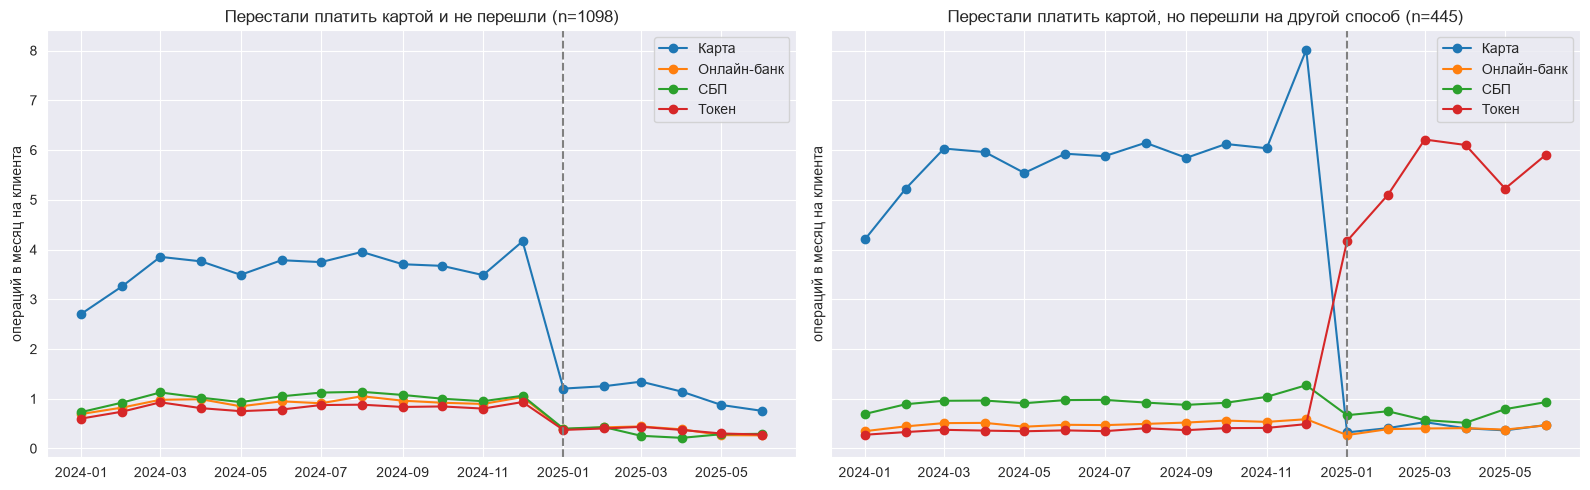

In [128]:
# Операции по каналам по месяцам: перестали платить картой и не перешли против перешедших
month = ok_txn['txn_datetime'].dt.to_period('M')
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, (name, mask) in zip(axes, [('Перестали платить картой и не перешли', lost_card),
                                   ('Перестали платить картой, но перешли на другой способ', switched)]):
    ids = clients.loc[mask, 'client_id']
    ops = ok_txn[ok_txn['client_id'].isin(ids)]
    by_channel = ops.groupby([month[ops.index], 'channel'], observed=True).size().unstack(fill_value=0) / mask.sum()
    for ch in by_channel.columns:
        ax.plot(by_channel.index.to_timestamp(), by_channel[ch], marker='o', label=ch)
    ax.axvline(pd.Timestamp('2025-01-01'), color='gray', linestyle='--')
    ax.set_title(f'{name} (n={mask.sum()})')
    ax.set_ylabel('операций в месяц на клиента')
    ax.legend()
plt.tight_layout()
plt.show()

In [129]:
# Насколько «перестали платить картой и не перешли» совпадает с падением активности на 40% и больше
both = strong & lost_card
print(f'Клиентов с падением активности на 40% и больше: {strong.sum()} из {len(clients)}')
print(f'Клиентов, переставших платить картой и не перешедших на другой способ: {lost_card.sum()} из {len(clients)}')
print()
print(f'Из переставших платить картой и не перешедших активность упала на 40% и больше у {both.sum()} из {lost_card.sum()} ({both.sum() / lost_card.sum():.0%})')
print(f'Из клиентов с падением на 40% и больше перестали платить картой и не перешли {both.sum()} из {strong.sum()} ({both.sum() / strong.sum():.0%})')
print(f'Из перешедших на другой способ активность упала на 40% и больше у {(strong & switched).sum()} из {switched.sum()}')

Клиентов с падением активности на 40% и больше: 1521 из 4839
Клиентов, переставших платить картой и не перешедших на другой способ: 1098 из 4839

Из переставших платить картой и не перешедших активность упала на 40% и больше у 1027 из 1098 (94%)
Из клиентов с падением на 40% и больше перестали платить картой и не перешли 1027 из 1521 (68%)
Из перешедших на другой способ активность упала на 40% и больше у 2 из 445


**Как опредедяем, что клиент перестал платить картой.** Для каждого клиента считаем среднее число успешных операций в месяц отдельно для оплаты картой и для остальных способов (токен, СБП, онлайн-банк), за 2024 год и за январь–июнь 2025 года. Ожидаемое число операций картой в 2025 году — уровень 2024 года, умноженный на сезонный коэффициент.

Клиент **перестал платить картой**, если в 2024 году платил картой хотя бы раз в месяц, а в 2025 году картой платил не больше половины ожидаемого. Условие «хотя бы раз в месяц» нужно, чтобы не учитывать тех, кто и раньше почти не пользовался картой: у них падение вдвое — это разница в одну-две операции, то есть шум.

Дальше разделяем таких клиентов на две части. Считаем, сколько операций картой клиент потерял (ожидаемое минус фактическое), и насколько выросли остальные способы оплаты по сравнению с ожидаемым. Если остальные способы выросли хотя бы на половину потерянного, клиент **перешёл на другой способ**: операции не пропали, а ушли в токен или СБП. Если нет, клиент **перестал платить картой и не перешёл**: его операции просто пропали.

Из 4839 клиентов перестали платить картой и не перешли 1098, перешли на другой способ 445. У перешедших общая активность почти не изменилась, поэтому снижения активности у них нет, и в кампанию они не попадают. У не перешедших активность упала сильно: 94% из них снизили активность на 40% и больше, и это две трети всех клиентов с таким падением. Значит, отказ от карты без замены — основной механизм падения активности.

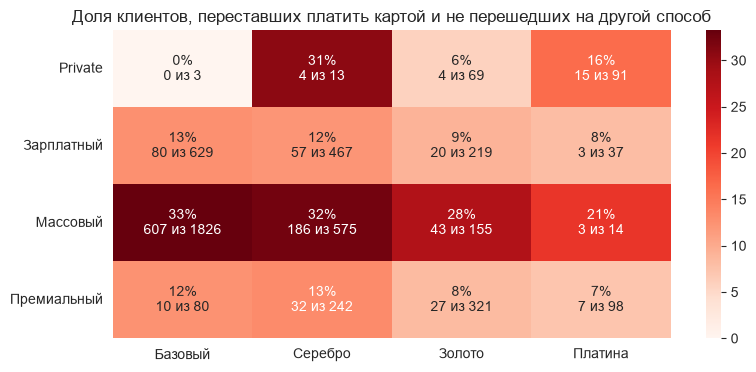

In [130]:
# Доля клиентов, переставших платить картой и не перешедших, по сегменту и уровню лояльности
k = lost_card.groupby([clients['segment'], clients['loyalty_tier']], observed=True).sum().unstack()
n = lost_card.groupby([clients['segment'], clients['loyalty_tier']], observed=True).size().unstack()
share = k / n * 100
labels = share.round(0).astype('Int64').astype(str) + '%\n' + k.astype('Int64').astype(str) + ' из ' + n.astype('Int64').astype(str)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(share, annot=labels, fmt='', cmap='Reds', ax=ax)
ax.set_title(f'Доля клиентов, переставших платить картой и не перешедших на другой способ')
ax.set_xlabel('')
ax.set_ylabel('')
plt.show()

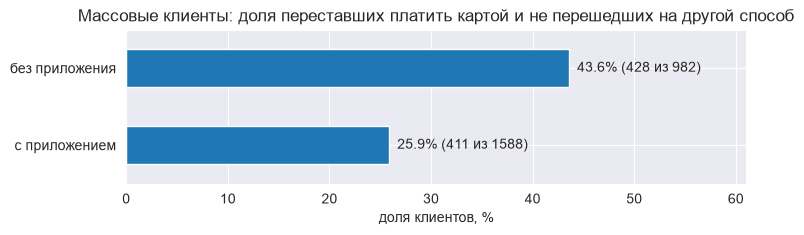

In [131]:
# Массовые клиенты: доля переставших платить картой и не перешедших, с приложением и без
app_label = clients['has_mobile_app'].map({True: 'с приложением', False: 'без приложения'})
plot_share(lost_card[mass], app_label[mass],
           'Массовые клиенты: доля переставших платить картой и не перешедших на другой способ',
           'доля клиентов, %')

**Группы**

Если клиент подходит под несколько правил, он попадает в первую по порядку.

1. **Перестали тратить на развлечения.** Кто: клиенты, у которых в 2024 году развлечения составляли не меньше 12% успешных операций. Что произошло: в январе–июне 2025 года операций на развлечения не больше половины ожидаемого, а остальные операции не меньше 80% ожидаемого.
2. **Массовые клиенты без приложения, перестали платить картой.** Кто: массовый сегмент, нет мобильного приложения. Что произошло: перестали платить картой и не перешли на другой способ оплаты.
3. **Массовые клиенты с приложением, перестали платить картой.** Кто: массовый сегмент, есть мобильное приложение. Что произошло: перестали платить картой и не перешли на другой способ оплаты.
4. **Зарплатные и премиальные клиенты с уровнем Базовый или Серебро, перестали платить картой.** Кто: зарплатный или премиальный сегмент, уровень лояльности Базовый или Серебро. Что произошло: перестали платить картой и не перешли на другой способ оплаты. Среди зарплатных и премиальных такие клиенты бросают карту в полтора раза чаще, чем с уровнем Золото или Платина, и они ценны для банка, поэтому выделены отдельно.

Массовых клиентов делим на две группы по наличию приложения, потому что у них заметно разная доля переставших платить картой: без приложения 43.6% (428 из 982), с приложением 25.9% (411 из 1588). Вероятно, у клиентов без приложения нет удобной замены карте, оплаты телефоном или СБП, поэтому, перестав пользоваться картой, они перестают платить через банк вовсе. Для кампании это тоже разные клиенты: тем, у кого есть приложение, можно написать в приложении, а клиентам без приложения нужен другой канал связи и предлагать им нужно разное.

Развлечения стоят первыми, потому что это самое узкое правило: у таких клиентов упала одна категория, а остальные операции почти как обычно. В кампанию идут только клиенты с согласием на маркетинговую коммуникацию.

In [132]:
# Кто это
mass = clients['segment'] == 'Массовый'
app = clients['has_mobile_app']
salary_premium_low = (clients['segment'].isin(['Зарплатный', 'Премиальный'])
                      & clients['loyalty_tier'].isin(['Базовый', 'Серебро']))

# Группы: клиент попадает в первую подходящую по порядку
conditions = [
    ent_drop,
    mass & ~app & lost_card,
    mass & app & lost_card,
    salary_premium_low & lost_card,
]
names = [
    'перестали тратить на развлечения',
    'массовые без приложения, перестали платить картой',
    'массовые с приложением, перестали платить картой',
    'зарплатные и премиальные с Базовым или Серебром, перестали платить картой',
]
group = pd.Series(np.select(conditions, names, default=''), index=clients.index)

# Таблица кампании: клиенты из групп с согласием на коммуникацию
campaign = clients.loc[(group != '') & clients['marketing_opt_in'], ['client_id']].copy()
campaign['group'] = group[campaign.index]

print('Клиентов в группах (всего и с согласием на коммуникацию):')
for name in names:
    print(f'  {name}: {(group == name).sum()}, с согласием {(campaign["group"] == name).sum()}')
print()
print(f'Всего в кампании: {len(campaign)} из лимита 2000')
print(f'Каждый client_id один раз: {campaign["client_id"].is_unique}')

Клиентов в группах (всего и с согласием на коммуникацию):
  перестали тратить на развлечения: 414, с согласием 365
  массовые без приложения, перестали платить картой: 427, с согласием 372
  массовые с приложением, перестали платить картой: 410, с согласием 351
  зарплатные и премиальные с Базовым или Серебром, перестали платить картой: 176, с согласием 153

Всего в кампании: 1241 из лимита 2000
Каждый client_id один раз: True


In [133]:
# Падение активности в каждой группе (клиенты кампании)
print('Медианы по группам (клиенты кампании):')
for name in names:
    g = clients.loc[campaign.index[campaign['group'] == name]]
    print(f'\n{name} ({len(g)} клиентов):')
    print(f'  операций в месяц в 2024: {g["ops_per_month_2024"].median():.1f}')
    print(f'  операций в месяц в 2025: {g["ops_per_month_2025"].median():.1f}')
    print(f'  изменение активности: {g["activity_change"].median():.0f}%')

Медианы по группам (клиенты кампании):

перестали тратить на развлечения (365 клиентов):
  операций в месяц в 2024: 5.9
  операций в месяц в 2025: 4.7
  изменение активности: -18%

массовые без приложения, перестали платить картой (372 клиентов):
  операций в месяц в 2024: 5.2
  операций в месяц в 2025: 1.5
  изменение активности: -69%

массовые с приложением, перестали платить картой (351 клиентов):
  операций в месяц в 2024: 5.5
  операций в месяц в 2025: 1.8
  изменение активности: -65%

зарплатные и премиальные с Базовым или Серебром, перестали платить картой (153 клиентов):
  операций в месяц в 2024: 6.8
  операций в месяц в 2025: 2.3
  изменение активности: -63%


### 7.1. Кого в кампанию не берём и почему

In [134]:
# 7.1. Кого не берём в кампанию и почему
gone = raw_transactions.loc[~raw_transactions['client_id'].isin(raw_clients['client_id']), 'client_id'].nunique()
new_card = funnel_df.loc[2, 'ушло']
rare = funnel_df.loc[1, 'ушло'] + funnel_df.loc[3, 'ушло']
lost_not_in_group = lost_card & (group == '')
no_cause = strong & (group == '') & ~switched
no_consent = (group != '') & ~clients['marketing_opt_in']

card_ratio = card_2025 / (card_2024 * SEASON_H1).replace(0, np.nan)
other_ratio = other_2025 / (other_2024 * SEASON_H1).replace(0, np.nan)

print(f'1. Нет в справочнике на 30.06.2025: {gone} клиентов.')
print('   Почему не берём: скорее всего, ушли из банка; нет признаков клиента и согласия на коммуникацию.')
print()
print(f'2. Карта открыта в 2024–2025 годах: {new_card} клиентов.')
print('   Почему не берём: операций до открытия карты нет, нет полного базового года, падение не посчитать.')
print()
print(f'3. Нет успешных операций или в 2024 году меньше одной в месяц: {rare} клиентов.')
print('   Почему не берём: при почти нулевой базе падение активности посчитать нельзя.')
print()
print(f'4. Перестали платить картой, но перешли на токен или СБП: {switched.sum()} клиентов, '
      f'медиана изменения активности {clients.loc[switched, "activity_change"].median():.0f}%.')
print('   Почему не берём: операции не пропали, а ушли в другие способы оплаты, активность не упала.')
print()
print(f'5. Перестали платить картой и не перешли, но не попали в группы: {lost_not_in_group.sum()} клиентов, '
      f'из них Private {(lost_not_in_group & (clients["segment"] == "Private")).sum()}, '
      f'зарплатные и премиальные с Золотом или Платиной '
      f'{(lost_not_in_group & clients["segment"].isin(["Зарплатный", "Премиальный"]) & clients["loyalty_tier"].isin(["Золото", "Платина"])).sum()}.')
print('   Почему не берём: их мало, бросают карту реже среднего, это самые ценные клиенты, '
      'для них уместнее персональная работа менеджера, чем массовая кампания.')
print()
print(f'6. Активность упала на 40% и больше, но не попали ни в группы, ни в перешедших: {no_cause.sum()} клиентов')
print('   Почему не берём: упали все способы оплаты сразу, по другим категориям особенносией нет, по данным не видно, что произошло поэтому непонятно, что им предложить.')
print()
print(f'7. Подходят под группу, но нет согласия на коммуникацию: {no_consent.sum()} клиентов.')
print('   Почему не берём: писать им без согласия нельзя.')

1. Нет в справочнике на 30.06.2025: 375 клиентов.
   Почему не берём: скорее всего, ушли из банка; нет признаков клиента и согласия на коммуникацию.

2. Карта открыта в 2024–2025 годах: 773 клиентов.
   Почему не берём: операций до открытия карты нет, нет полного базового года, падение не посчитать.

3. Нет успешных операций или в 2024 году меньше одной в месяц: 13 клиентов.
   Почему не берём: при почти нулевой базе падение активности посчитать нельзя.

4. Перестали платить картой, но перешли на токен или СБП: 445 клиентов, медиана изменения активности -4%.
   Почему не берём: операции не пропали, а ушли в другие способы оплаты, активность не упала.

5. Перестали платить картой и не перешли, но не попали в группы: 76 клиентов, из них Private 21, зарплатные и премиальные с Золотом или Платиной 55.
   Почему не берём: их мало, бросают карту реже среднего, это самые ценные клиенты, для них уместнее персональная работа менеджера, чем массовая кампания.

6. Активность упала на 40% и больше

In [135]:
# Сводка исключений для отчёта
exclusions = pd.DataFrame([
    ('нет в справочнике', gone),
    ('карта открыта в 2024–2025', new_card),
    ('нет операций или меньше одной в месяц в 2024', rare),
    ('перешли на другой способ оплаты', switched.sum()),
    ('бросили карту, но не попали в группы', lost_not_in_group.sum()),
    ('падение без видимой причины', no_cause.sum()),
    ('подходят под группу, но нет согласия', no_consent.sum()),
], columns=['кто', 'клиентов'])

## 8. Что проверили и что не подтвердилось

В гипотезах про то, кто падает, сравниваем долю клиентов с падением активности на 40% и больше в проверяемой группе и у остальных. Массовые клиенты падают гораздо чаще остальных, поэтому часть гипотез проверяем только среди массовых: иначе признак, которого просто больше у массовых, будет казаться важным.

*Гипотезы о самом падении*

1. **Падение временное, клиенты просели в начале года и вернулись.** Из 1095 клиентов, у которых в январе–марте 2025 было не больше половины ожидаемых операций, 801 остались на таком же низком уровне в апреле–июне, и только 71 вернулся хотя бы к 90% ожидаемого. Падение устойчивое. Не подтвердилась.
2. **Падение получилось из-за способа расчёта метрики.** Если сравнивать январь–июнь 2025 с теми же месяцами 2024 без сезонного коэффициента, результат почти тот же: корреляция Спирмена 0.96, падение на 40% и больше у 1521 и 1543 клиентов, у 1429 в обоих случаях. Не подтвердилась.
3. **Снижение активности — это начало ухода из банка.** У 375 клиентов, которых нет в справочнике, за 4–12 месяцев до ухода было в среднем около 5 операций в месяц, а за последние 3 месяца перед уходом даже чуть больше. Они ушли резко, без постепенного снижения. Значит, наши клиенты с падением — не уходящие, а те, кто продолжает пользоваться банком реже. Не подтвердилась.

*Гипотезы о том, кто падает*

4. **Чаще падают клиенты из Екатеринбурга.** По всем клиентам 42% против 29%, но среди массовых 47% против 45%. В Екатеринбурге просто больше массовых клиентов. Не подтвердилась.
5. **Клиенты ушли к конкуренту — те, у кого зарплата приходит в другой банк.** Среди массовых 48% против 44%: разница небольшая. Не подтвердилась.
6. **Чаще падают пожилые клиенты, 50 лет и старше.** Среди массовых без приложения 61% против 57%, с приложением 39% против 35%. Пожилые чаще без приложения, а при одинаковом наличии приложения разница небольшая. Не подтвердилась.
7. **Чаще падают клиенты, которые платят небольшими суммами.** Среди массовых 46% против 46%. Не подтвердилась.
8. **Чаще падают недовольные клиенты, с оценкой обслуживания 1.** Среди массовых 52% против 45%, но таких клиентов всего 151, а у 60% клиентов оценки нет вообще. Основой для группы это быть не может.

*Гипотезы о причинах*

9. **Кафе и рестораны бросили так же, как развлечения.** Среди 20% клиентов с самой большой долей категории развлечения упали на 79%, а кафе и рестораны на 28%, при том что остальные операции у тех и других почти не изменились (−5%). Кафе ведут себя как обычные категории, отдельно выделяются только развлечения. Не подтвердилась.
10. **Клиенты перестали платить из-за частых отказов по операциям.** Доля отклонённых операций около 2% и в 2025 году почти не изменилась ни у клиентов с падением, ни у остальных. Не подтвердилась.

**Подтверждение цифр кодом:**

In [136]:
# Доля клиентов с падением активности на 40% и больше: в проверяемой группе и у остальных
def drop_share(mask, within=None):
    if within is None:
        within = pd.Series(True, index=clients.index)
    a, b = mask & within, ~mask & within
    return (f'в группе {strong[a].mean():.0%} ({strong[a].sum()} из {a.sum()}), '
            f'у остальных {strong[b].mean():.0%} ({strong[b].sum()} из {b.sum()})')

In [137]:
# 1. Падение временное: клиенты просели в начале 2025 года и вернулись
per_month_2024 = ok_txn[is_2024].groupby(ok_txn.loc[is_2024, 'txn_datetime'].dt.to_period('M')).size()
season_q1 = per_month_2024['2024-01':'2024-03'].mean() / per_month_2024.mean()
season_q2 = per_month_2024['2024-04':'2024-06'].mean() / per_month_2024.mean()
in_q1 = (ok_txn['txn_datetime'] >= '2025-01-01') & (ok_txn['txn_datetime'] < '2025-04-01')
in_q2 = (ok_txn['txn_datetime'] >= '2025-04-01') & (ok_txn['txn_datetime'] < '2025-07-01')
ratio_q1 = per_month(in_q1, 3) / (clients['ops_per_month_2024'] * season_q1)
ratio_q2 = per_month(in_q2, 3) / (clients['ops_per_month_2024'] * season_q2)
low_q1 = ratio_q1 <= 0.5
print(f'1. В январе–марте 2025 не больше половины ожидаемого: {low_q1.sum()} клиентов.')
print(f'   Из них в апреле–июне всё ещё не больше половины: {(low_q1 & (ratio_q2 <= 0.5)).sum()}, '
      f'вернулись хотя бы к 90% ожидаемого: {(low_q1 & (ratio_q2 >= 0.9)).sum()}.')

# 2. Падение — артефакт способа расчёта метрики
h1_2024 = per_month((ok_txn['txn_datetime'] >= '2024-01-01') & (ok_txn['txn_datetime'] < '2024-07-01'), 6)
change_vs_h1 = (clients['ops_per_month_2025'] / h1_2024.replace(0, np.nan) - 1) * 100
strong_h1 = change_vs_h1 <= -40
print(f'2. Корреляция Спирмена с расчётом к январю–июню 2024: {clients["activity_change"].rank().corr(change_vs_h1.rank()):.2f}. '
      f'Падение на 40% и больше: {strong.sum()} и {strong_h1.sum()} клиентов, в обоих случаях {(strong & strong_h1).sum()}.')

# 3. Снижение активности — это начало ухода из банка (по 375 клиентам, которых нет в справочнике)
raw_ok = raw_transactions[(raw_transactions['status'] == 'успешно')
                          & (raw_transactions['txn_id'].astype(int) < 990000)
                          & ~raw_transactions['client_id'].isin(raw_clients['client_id'])].copy()
raw_ok['month'] = pd.to_datetime(raw_ok['txn_datetime'], format='mixed').dt.to_period('M')
gone_monthly = raw_ok.groupby(['client_id', 'month']).size()
gone_last = raw_ok.groupby('client_id')['month'].max()
before = [np.mean([gone_monthly.get((cid, m - k), 0) for k in range(4, 13)]) for cid, m in gone_last.items()]
near = [np.mean([gone_monthly.get((cid, m - k), 0) for k in range(1, 4)]) for cid, m in gone_last.items()]
print(f'3. Ушедшие клиенты ({len(gone_last)}): медиана операций в месяц за 4–12 месяцев до ухода {np.median(before):.1f}, '
      f'за последние 3 месяца перед уходом {np.median(near):.1f}.')

1. В январе–марте 2025 не больше половины ожидаемого: 1096 клиентов.
   Из них в апреле–июне всё ещё не больше половины: 806, вернулись хотя бы к 90% ожидаемого: 71.
2. Корреляция Спирмена с расчётом к январю–июню 2024: 0.96. Падение на 40% и больше: 1521 и 1543 клиентов, в обоих случаях 1429.
3. Ушедшие клиенты (375): медиана операций в месяц за 4–12 месяцев до ухода 4.9, за последние 3 месяца перед уходом 5.7.


In [138]:
mass = clients['segment'] == 'Массовый'
app = clients['has_mobile_app']
cheque = clients['client_id'].map(
    ok_txn[is_2024 & (ok_txn['currency'] == 'RUB')].groupby('client_id')['amount'].median())
low_cheque = cheque <= cheque.groupby(clients['segment'], observed=True).transform(lambda s: s.quantile(0.25))

print('4. Екатеринбург. Все клиенты:', drop_share(clients['city'] == 'Екатеринбург'))
print('   Только массовые:', drop_share(clients['city'] == 'Екатеринбург', mass))
print('5. Зарплата в другом банке. Все клиенты:', drop_share(clients['income_source'] == 'Зарплата в другом банке'))
print('   Только массовые:', drop_share(clients['income_source'] == 'Зарплата в другом банке', mass))
print('6. 50 лет и старше. Массовые без приложения:', drop_share(clients['age'] >= 50, mass & ~app))
print('   Массовые с приложением:', drop_share(clients['age'] >= 50, mass & app))
print('7. Маленький чек (нижняя четверть в своём сегменте). Только массовые:', drop_share(low_cheque, mass))
print('8. Оценка обслуживания 1. Только массовые:', drop_share(clients['satisfaction_score'] == 1, mass))

4. Екатеринбург. Все клиенты: в группе 42% (358 из 852), у остальных 29% (1163 из 3987)
   Только массовые: в группе 47% (341 из 732), у остальных 45% (828 из 1838)
5. Зарплата в другом банке. Все клиенты: в группе 38% (518 из 1375), у остальных 29% (1003 из 3464)
   Только массовые: в группе 48% (454 из 939), у остальных 44% (715 из 1631)
6. 50 лет и старше. Массовые без приложения: в группе 61% (419 из 687), у остальных 57% (168 из 295)
   Массовые с приложением: в группе 39% (283 из 735), у остальных 35% (299 из 853)
7. Маленький чек (нижняя четверть в своём сегменте). Только массовые: в группе 46% (293 из 643), у остальных 45% (876 из 1927)
8. Оценка обслуживания 1. Только массовые: в группе 52% (79 из 151), у остальных 43% (312 из 720)


In [139]:
# 9. Кафе и рестораны бросили так же, как развлечения
for cat in ['Развлечения и досуг', 'Кафе и рестораны']:
    in_cat = ok_txn['category'] == cat
    c24, c25 = per_month(is_2024 & in_cat, 12), per_month(~is_2024 & in_cat, 6)
    r24, r25 = per_month(is_2024 & ~in_cat, 12), per_month(~is_2024 & ~in_cat, 6)
    share = c24 / clients['ops_per_month_2024']
    top = share.rank(method='first') > share.rank(method='first').quantile(0.8)
    cat_ch = (c25 / (c24 * SEASON_H1).replace(0, np.nan) - 1) * 100
    rest_ch = (r25 / (r24 * SEASON_H1) - 1) * 100
    print(f'9. {cat}, 20% клиентов с самой большой долей категории: '
          f'операций в категории {cat_ch[top].median():.0f}%, остальных операций {rest_ch[top].median():.0f}% (медианы)')

# 10. Клиенты перестали платить из-за частых отказов
is_2024_all = transactions['txn_datetime'] < '2025-01-01'
declined = transactions['status'] == 'отклонено'
def decline_share(period):
    return clients['client_id'].map(declined[period].groupby(transactions.loc[period, 'client_id']).mean())
dec_2024, dec_2025 = decline_share(is_2024_all), decline_share(~is_2024_all)
print(f'10. Доля отклонённых операций. С падением: 2024 {dec_2024[strong].mean():.1%}, 2025 {dec_2025[strong].mean():.1%}. '
      f'Остальные: 2024 {dec_2024[~strong].mean():.1%}, 2025 {dec_2025[~strong].mean():.1%}.')

9. Развлечения и досуг, 20% клиентов с самой большой долей категории: операций в категории -79%, остальных операций -5% (медианы)
9. Кафе и рестораны, 20% клиентов с самой большой долей категории: операций в категории -28%, остальных операций -5% (медианы)
10. Доля отклонённых операций. С падением: 2024 1.8%, 2025 2.1%. Остальные: 2024 2.0%, 2025 1.9%.


## 9. Сохранение результатов

In [140]:
cleaning_log = pd.DataFrame(log_rows, columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

# Очищенные таблицы для второго ноутбука
clients.to_parquet("clean_data.parquet", index=False)
transactions.to_parquet("clean_transactions.parquet", index=False)

# Журнал изменений и список кампании
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")
exclusions.to_csv('exclusions.csv', index=False, encoding='utf-8')

print(f'clean_data.parquet: {len(clients)} клиентов, {clients.shape[1]} столбцов')
print(f'clean_transactions.parquet: {len(transactions)} операций')
print(f'cleaning_log.csv: {len(cleaning_log)} записей')
print(f'campaign_list.csv: {len(campaign)} клиентов, групп {campaign["group"].nunique()}')

clean_data.parquet: 4839 клиентов, 18 столбцов
clean_transactions.parquet: 575444 операций
cleaning_log.csv: 32 записей
campaign_list.csv: 1241 клиентов, групп 4
